In [4]:

import pandas as pd
import numpy as np

INPUT_FILE = "merged_dataset_movement_5.csv"
OUTPUT_FILE = "movement_sample_1million.csv"
TARGET = "MOVED"
SAMPLE_SIZE = 1_000_000
MOVER_SHARE = 0.50
RANDOM_STATE = 6480
CHUNK_SIZE = 250_000

N_MOVERS = int(SAMPLE_SIZE * MOVER_SHARE)
N_NONMOVERS = SAMPLE_SIZE - N_MOVERS


def normalize_moved(series):
    numeric = pd.to_numeric(series, errors="coerce")
    return numeric.where(numeric.isin([0, 1]))


def keep_random_candidates(current, new_rows, n_needed):
    combined = pd.concat([current, new_rows], ignore_index=True)
    if len(combined) > n_needed:
        combined = combined.nsmallest(n_needed, "_sample_random")
    return combined


def create_fixed_sample(input_file=INPUT_FILE, output_file=OUTPUT_FILE):
    rng = np.random.default_rng(RANDOM_STATE)
    movers = pd.DataFrame()
    nonmovers = pd.DataFrame()
    total_rows = 0
    mover_rows_seen = 0
    nonmover_rows_seen = 0

    print(f"Reading: {input_file}")
    print(f"Target sample: {SAMPLE_SIZE:,} rows")
    print(f"Requested movers: {N_MOVERS:,}")
    print(f"Requested non-movers: {N_NONMOVERS:,}")

    reader = pd.read_csv(input_file, chunksize=CHUNK_SIZE, low_memory=False)

    for chunk_number, chunk in enumerate(reader, start=1):
        total_rows += len(chunk)
        if TARGET not in chunk.columns:
            raise KeyError(f"{TARGET} not found in source CSV")

        chunk = chunk.copy()
        chunk[TARGET] = normalize_moved(chunk[TARGET])
        chunk = chunk.dropna(subset=[TARGET])
        chunk[TARGET] = chunk[TARGET].astype("int8")
        chunk["_sample_random"] = rng.random(len(chunk))

        mover_chunk = chunk[chunk[TARGET] == 0]
        nonmover_chunk = chunk[chunk[TARGET] == 1]
        mover_rows_seen += len(mover_chunk)
        nonmover_rows_seen += len(nonmover_chunk)

        movers = keep_random_candidates(movers, mover_chunk, N_MOVERS)
        nonmovers = keep_random_candidates(nonmovers, nonmover_chunk, N_NONMOVERS)

        if chunk_number % 10 == 0:
            print(
                f"Chunks: {chunk_number} | rows scanned: {total_rows:,} | "
                f"movers seen: {mover_rows_seen:,} | non-movers seen: {nonmover_rows_seen:,}"
            )

    if len(movers) < N_MOVERS:
        raise ValueError(f"Only {len(movers):,} movers available; requested {N_MOVERS:,}")
    if len(nonmovers) < N_NONMOVERS:
        raise ValueError(f"Only {len(nonmovers):,} non-movers available; requested {N_NONMOVERS:,}")

    sample = pd.concat([movers, nonmovers], ignore_index=True)
    sample = sample.drop(columns="_sample_random")
    sample = sample.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    assert len(sample) == SAMPLE_SIZE
    assert set(sample[TARGET].unique()).issubset({0, 1})

    print("\nFinal class counts:")
    print(sample[TARGET].value_counts().sort_index())
    print("\nFinal class percentages:")
    print((sample[TARGET].value_counts(normalize=True).sort_index() * 100).round(2))

    sample.to_csv(output_file, index=False)
    print(f"\nSaved: {output_file}")
    return sample


if __name__ == "__main__":
    sample_df = create_fixed_sample()


Reading: merged_dataset_movement_5.csv
Target sample: 1,000,000 rows
Requested movers: 500,000
Requested non-movers: 500,000
Chunks: 10 | rows scanned: 2,500,000 | movers seen: 0 | non-movers seen: 2,500,000
Chunks: 20 | rows scanned: 5,000,000 | movers seen: 0 | non-movers seen: 5,000,000
Chunks: 30 | rows scanned: 7,500,000 | movers seen: 0 | non-movers seen: 7,500,000
Chunks: 40 | rows scanned: 10,000,000 | movers seen: 0 | non-movers seen: 10,000,000
Chunks: 50 | rows scanned: 12,500,000 | movers seen: 0 | non-movers seen: 12,500,000
Chunks: 60 | rows scanned: 15,000,000 | movers seen: 0 | non-movers seen: 15,000,000
Chunks: 70 | rows scanned: 17,500,000 | movers seen: 0 | non-movers seen: 17,500,000
Chunks: 80 | rows scanned: 20,000,000 | movers seen: 0 | non-movers seen: 20,000,000
Chunks: 90 | rows scanned: 22,500,000 | movers seen: 0 | non-movers seen: 22,500,000
Chunks: 100 | rows scanned: 25,000,000 | movers seen: 0 | non-movers seen: 25,000,000
Chunks: 110 | rows scanned: 27

In [5]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# STEP 2: AUDIT THE FIXED 1,000,000-ROW SAMPLE
# ============================================================
# Run this AFTER Step 1 has created movement_sample_1million.csv.
# This script DOES NOT train a model and DOES NOT change the saved sample.
# Its job is to inspect the sample and help us decide which variables are safe
# and useful for modeling before the train/test split and preprocessing steps.

INPUT_FILE = "movement_sample_1million.csv"
TARGET = "MOVED"
REPORT_DIR = Path("step2_audit_reports")
REPORT_DIR.mkdir(exist_ok=True)

# Practical review thresholds. These flag columns for inspection; they do not
# automatically delete them.
HIGH_CARDINALITY_N = 50
HIGH_CARDINALITY_PCT = 5.0
HIGH_MISSING_PCT = 50.0
NEAR_UNIQUE_PCT = 95.0

# Names commonly associated with IDs, linkages, or geography in the earlier
# census work. We only flag columns that actually exist in the current sample.
ID_OR_LINKAGE_NAMES = {
    "HIK", "SERIAL", "PERNUM", "NUMPREC", "NUMPERHH", "HISTID",
    "HISTID_MOM2", "HISTID_POP2", "PERSON_ID"
}

GEOGRAPHY_NAMES = {
    "STATEFIP", "CITY", "COUNTYICP", "COUNTYNHG", "STATEICP",
    "STATE_BASELINE", "COUNTY_BASELINE", "STATE_FOLLOWUP", "COUNTY_FOLLOWUP"
}


def print_section(title):
    print("\n" + "=" * 72)
    print(title)
    print("=" * 72)


def audit_sample(file_name=INPUT_FILE):
    print_section("STEP 2 - LOAD FIXED SAMPLE")
    df = pd.read_csv(file_name, low_memory=False)

    print(f"File: {file_name}")
    print(f"Rows: {len(df):,}")
    print(f"Columns: {df.shape[1]:,}")
    print(f"Duplicate full rows: {df.duplicated().sum():,}")

    if TARGET not in df.columns:
        raise KeyError(f"Required target '{TARGET}' is not present in the sample.")

    print_section("TARGET CHECK")
    target_counts = df[TARGET].value_counts(dropna=False).sort_index()
    target_pct = df[TARGET].value_counts(normalize=True, dropna=False).sort_index() * 100
    print("Counts:")
    print(target_counts)
    print("\nPercentages:")
    print(target_pct.round(3))
    print(f"Missing target values: {df[TARGET].isna().sum():,}")

    # --------------------------------------------------------
    # COLUMN-LEVEL AUDIT
    # --------------------------------------------------------
    print_section("BUILD COLUMN AUDIT")
    rows = []
    n_rows = len(df)

    for col in df.columns:
        s = df[col]
        nunique = s.nunique(dropna=True)
        missing_n = int(s.isna().sum())
        missing_pct = (missing_n / n_rows * 100) if n_rows else 0
        unique_pct = (nunique / n_rows * 100) if n_rows else 0

        rows.append({
            "column": col,
            "dtype": str(s.dtype),
            "missing_n": missing_n,
            "missing_pct": missing_pct,
            "unique_n": int(nunique),
            "unique_pct_of_rows": unique_pct,
            "constant": nunique <= 1,
            "binary": nunique == 2,
            "high_missing_flag": missing_pct >= HIGH_MISSING_PCT,
            "high_cardinality_flag": (
                nunique >= HIGH_CARDINALITY_N and unique_pct >= HIGH_CARDINALITY_PCT
            ),
            "near_unique_id_flag": unique_pct >= NEAR_UNIQUE_PCT,
            "name_id_or_linkage_flag": col.upper() in ID_OR_LINKAGE_NAMES,
            "name_geography_flag": col.upper() in GEOGRAPHY_NAMES,
        })

    audit = pd.DataFrame(rows)

    # A review flag means "look at this before modeling", not "always drop it".
    audit["needs_review"] = audit[[
        "constant", "high_missing_flag", "high_cardinality_flag",
        "near_unique_id_flag", "name_id_or_linkage_flag", "name_geography_flag"
    ]].any(axis=1)

    audit.to_csv(REPORT_DIR / "column_audit.csv", index=False)
    print(f"Saved full column audit: {REPORT_DIR / 'column_audit.csv'}")

    # --------------------------------------------------------
    # MISSINGNESS
    # --------------------------------------------------------
    print_section("MISSINGNESS")
    missing = audit.loc[audit["missing_n"] > 0, [
        "column", "dtype", "missing_n", "missing_pct"
    ]].sort_values(["missing_pct", "missing_n"], ascending=False)

    if missing.empty:
        print("No missing values found.")
    else:
        print(missing.head(30).to_string(index=False))
    missing.to_csv(REPORT_DIR / "missingness.csv", index=False)

    # --------------------------------------------------------
    # CARDINALITY
    # --------------------------------------------------------
    print_section("HIGHEST-CARDINALITY COLUMNS")
    cardinality = audit[[
        "column", "dtype", "unique_n", "unique_pct_of_rows",
        "high_cardinality_flag", "near_unique_id_flag"
    ]].sort_values("unique_n", ascending=False)
    print(cardinality.head(30).to_string(index=False))
    cardinality.to_csv(REPORT_DIR / "cardinality.csv", index=False)

    # --------------------------------------------------------
    # REVIEW CANDIDATES
    # --------------------------------------------------------
    print_section("COLUMNS TO REVIEW BEFORE MODELING")
    review = audit.loc[audit["needs_review"]].copy()
    review = review.sort_values(
        ["near_unique_id_flag", "name_id_or_linkage_flag", "high_cardinality_flag", "missing_pct"],
        ascending=False
    )
    if review.empty:
        print("No columns crossed the automatic review thresholds.")
    else:
        print(review[[
            "column", "dtype", "missing_pct", "unique_n", "unique_pct_of_rows",
            "constant", "high_cardinality_flag", "near_unique_id_flag",
            "name_id_or_linkage_flag", "name_geography_flag"
        ]].to_string(index=False))
    review.to_csv(REPORT_DIR / "columns_to_review.csv", index=False)

    # --------------------------------------------------------
    # INITIAL MODELING CANDIDATES
    # --------------------------------------------------------
    # Conservative rule: remove target, constants, obvious/near-unique IDs and
    # named geography fields for the first comparable experiment. High missingness
    # and other high-cardinality columns are NOT silently removed. They stay on the
    # manual-review list because missingness itself may be informative.
    automatic_exclusions = set(
        audit.loc[
            audit["constant"]
            | audit["near_unique_id_flag"]
            | audit["name_id_or_linkage_flag"]
            | audit["name_geography_flag"],
            "column"
        ]
    )
    automatic_exclusions.add(TARGET)

    candidate_features = [c for c in df.columns if c not in automatic_exclusions]

    pd.Series(sorted(automatic_exclusions), name="excluded_column").to_csv(
        REPORT_DIR / "initial_exclusions.csv", index=False
    )
    pd.Series(candidate_features, name="candidate_feature").to_csv(
        REPORT_DIR / "candidate_features.csv", index=False
    )

    print_section("INITIAL FEATURE RECOMMENDATION")
    print(f"Automatically excluded columns: {len(automatic_exclusions):,}")
    print(f"Candidate modeling features: {len(candidate_features):,}")
    print("\nAutomatic exclusions:")
    for col in sorted(automatic_exclusions):
        print(f"  - {col}")

    print("\nHigh-cardinality or high-missing columns still requiring manual review:")
    manual = audit.loc[
        (~audit["column"].isin(automatic_exclusions))
        & (audit["high_cardinality_flag"] | audit["high_missing_flag"]),
        ["column", "missing_pct", "unique_n", "high_cardinality_flag", "high_missing_flag"]
    ]
    if manual.empty:
        print("  None flagged by the current thresholds.")
    else:
        print(manual.to_string(index=False))

    # Light numeric summary, useful for AGE and other continuous/count variables.
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
    if numeric_cols:
        numeric_summary = df[numeric_cols].describe().T
        numeric_summary.to_csv(REPORT_DIR / "numeric_summary.csv")

    print_section("STEP 2 COMPLETE")
    print("Reports written to:")
    print(f"  {REPORT_DIR / 'column_audit.csv'}")
    print(f"  {REPORT_DIR / 'missingness.csv'}")
    print(f"  {REPORT_DIR / 'cardinality.csv'}")
    print(f"  {REPORT_DIR / 'columns_to_review.csv'}")
    print(f"  {REPORT_DIR / 'initial_exclusions.csv'}")
    print(f"  {REPORT_DIR / 'candidate_features.csv'}")
    if numeric_cols:
        print(f"  {REPORT_DIR / 'numeric_summary.csv'}")

    return df, audit, candidate_features


if __name__ == "__main__":
    sample_df, audit_df, candidate_features = audit_sample()



STEP 2 - LOAD FIXED SAMPLE
File: movement_sample_1million.csv
Rows: 1,000,000
Columns: 107
Duplicate full rows: 0

TARGET CHECK
Counts:
0    500000
1    500000
Name: MOVED, dtype: int64

Percentages:
0    50.0
1    50.0
Name: MOVED, dtype: float64
Missing target values: 0

BUILD COLUMN AUDIT
Saved full column audit: step2_audit_reports/column_audit.csv

MISSINGNESS
          column   dtype  missing_n  missing_pct
     PERNUM_MOM2 float64    1000000        100.0
     PERNUM_POP2 float64    1000000        100.0
        SEX_MOM2 float64    1000000        100.0
        SEX_POP2 float64    1000000        100.0
        AGE_MOM2 float64    1000000        100.0
        AGE_POP2 float64    1000000        100.0
       RACE_MOM2 float64    1000000        100.0
       RACE_POP2 float64    1000000        100.0
      RACED_MOM2 float64    1000000        100.0
      RACED_POP2 float64    1000000        100.0
        BPL_MOM2 float64    1000000        100.0
        BPL_POP2 float64    1000000        

In [6]:
# ============================================================
# STEP 2B: CREATE THE CLEAN MODELING DATASET
# ============================================================

# PURPOSE:
#
# Step 2 showed several groups of variables that should not
# be included directly in the first model comparison.
#
# We will now create a cleaner modeling dataset from the fixed
# 1,000,000-row sample.
#
# IMPORTANT:
#
# This does NOT change movement_sample_1million.csv.
#
# That CSV remains our permanent master sample.
#
# We are creating a SECOND file containing only the variables
# that are appropriate for modeling.


import pandas as pd


# ------------------------------------------------------------
# LOAD FIXED MASTER SAMPLE
# ------------------------------------------------------------

INPUT_FILE = "movement_sample_1million.csv"

OUTPUT_FILE = "movement_modeling_1million.csv"

TARGET = "MOVED"


df = pd.read_csv(
    INPUT_FILE,
    low_memory=False
)


print("Original shape:", df.shape)

Original shape: (1000000, 107)


In [7]:
# ------------------------------------------------------------
# EXCLUDE COMPLETELY EMPTY VARIABLES
# ------------------------------------------------------------

# Identify columns where EVERY observation is missing.
#
# These variables contain no information in this particular
# sample and cannot contribute to the models.

all_missing_columns = [

    col for col in df.columns

    if df[col].isna().all()

]


print(
    "100% missing columns:",
    len(all_missing_columns)
)


for col in all_missing_columns:

    print("  ", col)

100% missing columns: 34
   PERNUM_MOM2
   PERNUM_POP2
   SEX_MOM2
   SEX_POP2
   AGE_MOM2
   AGE_POP2
   RACE_MOM2
   RACE_POP2
   RACED_MOM2
   RACED_POP2
   BPL_MOM2
   BPL_POP2
   BPLD_MOM2
   BPLD_POP2
   NATIVITY_MOM2
   NATIVITY_POP2
   LIT_MOM2
   LIT_POP2
   OCC_MOM2
   OCC_POP2
   OCC1950_MOM2
   OCC1950_POP2
   VERSIONHIST_MOM2
   VERSIONHIST_POP2
   BLIND_MOM2
   BLIND_POP2
   DEAF_MOM2
   DEAF_POP2
   IDIOTIC_MOM2
   IDIOTIC_POP2
   INSANE_MOM2
   INSANE_POP2
   HISTID_MOM2
   HISTID_POP2


In [8]:
# ------------------------------------------------------------
# EXCLUDE IDENTIFIER AND LINKAGE VARIABLES
# ------------------------------------------------------------

# These variables identify people, households, records,
# or linked relatives rather than describing substantive
# demographic characteristics.
#
# They should not be allowed to act as predictors.

identifier_columns = [

    "HIK",

    "HISTID",

    "SERIAL",

    "PERNUM",

    "NUMPREC",

    "NUMPERHH",

    "SPLITHID",

    "HISTID_MOM",

    "HISTID_POP"

]

In [9]:
# ------------------------------------------------------------
# EXCLUDE DETAILED GEOGRAPHY
# ------------------------------------------------------------

# MOVED was constructed from geographic change.
#
# Detailed geographic identifiers are therefore removed from
# this first model comparison to reduce both leakage concerns
# and high-cardinality complexity.

geography_columns = [

    "STATEFIP",

    "STATEICP",

    "COUNTYICP",

    "COUNTYNHG",

    "CITY"

]

In [10]:
# ------------------------------------------------------------
# EXCLUDE PARENTAL VARIABLES FROM FIRST MODEL COMPARISON
# ------------------------------------------------------------

# Step 2 showed that most mother/father variables contain
# approximately 80% to 90% missing data.
#
# For the first experiment we want to determine how well the
# individual's own characteristics predict movement.
#
# Parental variables can later be evaluated in a separate
# feature-expansion experiment.

parent_columns = [

    col for col in df.columns

    if col.endswith("_MOM")

    or col.endswith("_POP")

]

In [11]:
# ------------------------------------------------------------
# ADDITIONAL FIRST-PASS EXCLUSIONS
# ------------------------------------------------------------

# SICKNESS is almost completely missing in the current sample.

manual_exclusions = [

    "SICKNESS"

]

In [12]:
# ------------------------------------------------------------
# COMBINE EXCLUSIONS
# ------------------------------------------------------------

exclude_columns = set(

    all_missing_columns

    + identifier_columns

    + geography_columns

    + parent_columns

    + manual_exclusions

)


# Do NOT accidentally remove MOVED here.
#
# MOVED must remain in the saved modeling dataset because
# it is our target variable.

exclude_columns.discard(TARGET)


# Only attempt to remove columns that actually exist.

exclude_columns = [

    col for col in exclude_columns

    if col in df.columns

]


print(
    "\nColumns excluded:",
    len(exclude_columns)
)


Columns excluded: 81


In [13]:
# ------------------------------------------------------------
# CREATE CLEAN MODELING DATA
# ------------------------------------------------------------

model_df = df.drop(
    columns=exclude_columns
).copy()


print(
    "Modeling dataset shape:",
    model_df.shape
)


print(
    "\nRemaining columns:"
)


for col in model_df.columns:

    print("  ", col)

Modeling dataset shape: (1000000, 26)

Remaining columns:
   YEAR
   URBAN
   GQ
   SEX
   AGE
   RACE
   RACED
   BPL
   BPLD
   NATIVITY
   LIT
   OCC
   OCC1950
   VERSIONHIST
   BLIND
   DEAF
   IDIOTIC
   INSANE
   LINK1860
   LINK1870
   LINK1880
   VERSIONHIK
   GQTYPE
   GQTYPED
   LINK1850
   MOVED


In [14]:
# ------------------------------------------------------------
# VERIFY THE TARGET WAS NOT ALTERED
# ------------------------------------------------------------

print(
    "\nMOVED distribution:"
)


print(
    model_df[TARGET]
    .value_counts()
    .sort_index()
)


# Verify that all one million observations remain.

assert len(model_df) == 1_000_000


# Verify that all movers and non-movers remain.

assert (
    model_df[TARGET]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {0: 500000, 1: 500000}
)


# ------------------------------------------------------------
# SAVE CLEAN MODELING DATASET
# ------------------------------------------------------------

model_df.to_csv(
    OUTPUT_FILE,
    index=False
)


print(
    f"\nSaved modeling dataset: {OUTPUT_FILE}"
)


MOVED distribution:
0    500000
1    500000
Name: MOVED, dtype: int64

Saved modeling dataset: movement_modeling_1million.csv


In [15]:
# ============================================================
# STEP 2C: FINALIZE THE MODEL FEATURE SET
# ============================================================

# PURPOSE:
#
# Step 2B reduced the original 107-column dataset to 26 columns.
#
# Before creating the train/test split, I am making one final
# feature-selection decision.
#
# The goal is to create a common predictor set that:
#
#   1. Represents the individual's demographic characteristics.
#   2. Includes the disability variables central to the research.
#   3. Retains important contextual variables such as year,
#      urban status, and group-quarters status.
#   4. Avoids identifiers and linkage metadata.
#   5. Avoids including multiple detailed versions of the same
#      underlying concept.
#   6. Limits unnecessary high-cardinality expansion.
#
# The same final feature set will eventually be used across
# all models so the model comparison remains consistent.


import pandas as pd


# ------------------------------------------------------------
# LOAD THE CLEAN MODELING DATASET CREATED IN STEP 2B
# ------------------------------------------------------------

INPUT_FILE = "movement_modeling_1million.csv"

OUTPUT_FILE = "movement_final_features_1million.csv"

TARGET = "MOVED"


df = pd.read_csv(
    INPUT_FILE,
    low_memory=False
)


print("Starting shape:", df.shape)

Starting shape: (1000000, 26)


In [16]:
# ------------------------------------------------------------
# DEFINE FINAL PREDICTORS
# ------------------------------------------------------------

# Rather than repeatedly deleting unwanted variables, define
# exactly which predictors are allowed into the experiment.
#
# This makes the methodology easier to reproduce and prevents
# an unwanted variable from accidentally entering a later model.


FEATURES = [

    # --------------------------------------------------------
    # TIME
    # --------------------------------------------------------

    # Census year.

    "YEAR",


    # --------------------------------------------------------
    # LIVING SITUATION
    # --------------------------------------------------------

    # Urban/rural status.

    "URBAN",


    # Group-quarters status.
    #
    # Use the simpler GQ representation rather than also
    # including GQTYPE and GQTYPED.

    "GQ",


    # --------------------------------------------------------
    # BASIC DEMOGRAPHICS
    # --------------------------------------------------------

    "SEX",

    "AGE",


    # Use RACE rather than including both RACE and RACED.

    "RACE",


    # --------------------------------------------------------
    # BIRTHPLACE / NATIVITY
    # --------------------------------------------------------

    # Use the broader BPL variable.
    #
    # Do not include BPLD in the first experiment because BPLD
    # is a more detailed representation of birthplace and would
    # increase dimensionality after categorical encoding.

    "BPL",


    # Keep NATIVITY even though it contains substantial
    # missingness.
    #
    # Previous analysis showed that nativity missingness may
    # itself contain predictive information.
    #
    # Missing NATIVITY values will therefore be represented
    # explicitly during preprocessing rather than causing
    # observations to be deleted.

    "NATIVITY",


    # --------------------------------------------------------
    # LITERACY
    # --------------------------------------------------------

    # Keep LIT.
    #
    # Like NATIVITY, missing literacy may contain information.
    # Missing values will later receive an explicit category.

    "LIT",


    # --------------------------------------------------------
    # OCCUPATION
    # --------------------------------------------------------

    # Keep ONE occupation representation rather than using both
    # OCC and OCC1950.
    #
    # OCC1950 is retained for this first experiment.
    #
    # We will treat the occupation codes as categorical values,
    # not as continuous numeric measurements.

    "OCC1950",


    # --------------------------------------------------------
    # DISABILITY VARIABLES
    # --------------------------------------------------------

    # These variables are particularly important because the
    # research question concerns disability and migration.

    "BLIND",

    "DEAF",

    "IDIOTIC",

    "INSANE"

]

In [17]:
# ------------------------------------------------------------
# CREATE THE FINAL MODELING DATASET
# ------------------------------------------------------------

# Keep only the approved predictor variables plus MOVED.

final_columns = FEATURES + [TARGET]


model_df = df[
    final_columns
].copy()


print(
    "\nFinal modeling shape:",
    model_df.shape
)


print(
    "\nFinal columns:"
)


for col in model_df.columns:

    print("  ", col)


Final modeling shape: (1000000, 15)

Final columns:
   YEAR
   URBAN
   GQ
   SEX
   AGE
   RACE
   BPL
   NATIVITY
   LIT
   OCC1950
   BLIND
   DEAF
   IDIOTIC
   INSANE
   MOVED


In [18]:
# ------------------------------------------------------------
# TARGET CLASS DEFINITIONS
# ------------------------------------------------------------

# IMPORTANT:
#
# The current experiment dataset uses:
#
# MOVED = 0 -> MOVER
# MOVED = 1 -> NON-MOVER
#
# Do not assume that class 1 represents movers.
#
# These constants will be used later when calculating mover
# precision, mover recall, mover F1, and confusion matrices.


MOVER_VALUE = 0

NONMOVER_VALUE = 1

In [19]:
# ------------------------------------------------------------
# VERIFY TARGET DISTRIBUTION
# ------------------------------------------------------------

print(
    "\nTarget counts:"
)


print(
    model_df[TARGET]
    .value_counts()
    .sort_index()
)


mover_count = (
    model_df[TARGET] == MOVER_VALUE
).sum()


nonmover_count = (
    model_df[TARGET] == NONMOVER_VALUE
).sum()


print(
    f"\nMovers (MOVED = {MOVER_VALUE}): "
    f"{mover_count:,}"
)


print(
    f"Non-movers (MOVED = {NONMOVER_VALUE}): "
    f"{nonmover_count:,}"
)


# Both classes should contain exactly 500,000 records.

assert mover_count == 500_000

assert nonmover_count == 500_000


Target counts:
0    500000
1    500000
Name: MOVED, dtype: int64

Movers (MOVED = 0): 500,000
Non-movers (MOVED = 1): 500,000


In [20]:
# ------------------------------------------------------------
# CHECK MISSINGNESS IN FINAL FEATURES
# ------------------------------------------------------------

# Missing values are NOT removed here.
#
# We are documenting them so that preprocessing can handle
# them correctly after the train/test split.


missing_summary = pd.DataFrame({

    "missing_count":
        model_df.isna().sum(),

    "missing_percent":
        model_df.isna().mean() * 100

})


missing_summary = missing_summary.sort_values(

    "missing_percent",
    ascending=False

)


print(
    "\nMissingness in final dataset:"
)


print(
    missing_summary.round(2)
)


Missingness in final dataset:
          missing_count  missing_percent
NATIVITY         759189            75.92
LIT              602341            60.23
BPL              602341            60.23
DEAF             126940            12.69
BLIND            126940            12.69
IDIOTIC          126940            12.69
INSANE           126940            12.69
RACE                  0             0.00
AGE                   0             0.00
SEX                   0             0.00
GQ                    0             0.00
YEAR                  0             0.00
URBAN                 0             0.00
OCC1950               0             0.00
MOVED                 0             0.00


In [21]:
# ------------------------------------------------------------
# SAVE FINAL FEATURE DATASET
# ------------------------------------------------------------

# This file contains:
#
#   1,000,000 observations
#   14 predictors
#   1 MOVED target
#
# No model-specific transformations have been performed yet.
#
# We are intentionally saving the data BEFORE one-hot encoding,
# scaling, imputation, or oversampling.
#
# Those operations must be handled later in the modeling
# pipeline to avoid contaminating the test data.


model_df.to_csv(

    OUTPUT_FILE,

    index=False

)


print(
    f"\nSaved final feature dataset: "
    f"{OUTPUT_FILE}"
)



Saved final feature dataset: movement_final_features_1million.csv


In [22]:
# ============================================================
# STEP 3: CREATE ONE FIXED TRAIN / TEST SPLIT
# ============================================================

# PURPOSE:
#
# The final modeling dataset now contains:
#
#   1,000,000 observations
#   14 predictor variables
#   1 target variable (MOVED)
#
# Before performing ANY preprocessing or training models,
# divide the data into one permanent training set and one
# permanent test set.
#
# Every model in the experiment will use:
#
#   THE SAME training observations
#   THE SAME test observations
#
# This is important because differences in model performance
# should reflect the models themselves rather than differences
# in which observations happened to be assigned to the test set.
#
# NO imputation is performed before this split.
# NO one-hot encoding is performed before this split.
# NO scaling is performed before this split.
# NO mover oversampling is performed before this split.
#
# The test set will remain untouched until final evaluation.
# ============================================================

In [23]:
# ------------------------------------------------------------
# IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import pandas as pd

from sklearn.model_selection import train_test_split

In [24]:
# ------------------------------------------------------------
# FILE SETTINGS
# ------------------------------------------------------------

# Load the final feature dataset created in Step 2C.

INPUT_FILE = "movement_final_features_1million.csv"


# Save training and test observations separately.
#
# These files allow every future experiment to use the exact
# same train/test observations without recreating the split.

TRAIN_FILE = "movement_train_800k.csv"

TEST_FILE = "movement_test_200k.csv"


# Define the target variable.

TARGET = "MOVED"

In [25]:
# ------------------------------------------------------------
# TARGET CLASS DEFINITIONS
# ------------------------------------------------------------

# IMPORTANT:
#
# The current experiment uses:
#
#     MOVED = 0 -> MOVER
#
#     MOVED = 1 -> NON-MOVER
#
# Movers are the class of primary research interest.
#
# Define these values explicitly so that later precision,
# recall, F1, and confusion-matrix calculations do not
# accidentally reverse the class interpretation.

MOVER_VALUE = 0

NONMOVER_VALUE = 1

In [26]:
# ------------------------------------------------------------
# RANDOM SEED
# ------------------------------------------------------------

# Use the same fixed random seed throughout this experiment
# whenever reproducible random behavior is required.

RANDOM_STATE = 6480


In [27]:
# ------------------------------------------------------------
# LOAD FINAL MODELING DATA
# ------------------------------------------------------------

df = pd.read_csv(
    INPUT_FILE,
    low_memory=False
)


print(
    "Full modeling dataset shape:",
    df.shape
)

Full modeling dataset shape: (1000000, 15)


In [28]:
# ------------------------------------------------------------
# VALIDATE DATA BEFORE SPLITTING
# ------------------------------------------------------------

# Confirm that the target exists.

assert TARGET in df.columns


# Confirm that the expected number of observations exists.

assert len(df) == 1_000_000


# Confirm that MOVED contains only 0 and 1.

assert set(
    df[TARGET].unique()
) == {0, 1}


# Display the class distribution before the split.

print(
    "\nFull dataset class counts:"
)


print(
    df[TARGET]
    .value_counts()
    .sort_index()
)


Full dataset class counts:
0    500000
1    500000
Name: MOVED, dtype: int64


In [29]:
# ------------------------------------------------------------
# SEPARATE PREDICTORS FROM TARGET
# ------------------------------------------------------------

# X contains the predictor variables.
#
# MOVED must not be included in X because MOVED is the outcome
# that the models will attempt to predict.

X = df.drop(
    columns=[TARGET]
)


# y contains only the target variable.

y = df[TARGET]


print(
    "\nPredictor matrix shape:",
    X.shape
)


print(
    "Target shape:",
    y.shape
)


Predictor matrix shape: (1000000, 14)
Target shape: (1000000,)


In [30]:
# ------------------------------------------------------------
# CREATE THE FIXED 80 / 20 SPLIT
# ------------------------------------------------------------

# Use 80% of the observations for training.
#
# Use 20% of the observations for final testing.
#
# Because there are 1,000,000 total records, this should create:
#
#     Training = 800,000
#
#     Testing  = 200,000
#
# stratify=y preserves the 50/50 target distribution in
# both the training and test datasets.
#
# Because the complete experiment dataset contains equal
# numbers of movers and non-movers, we expect:
#
# TRAINING:
#
#     400,000 movers
#     400,000 non-movers
#
# TEST:
#
#     100,000 movers
#     100,000 non-movers


X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y

)

In [31]:
# ------------------------------------------------------------
# VERIFY TRAIN / TEST SIZE
# ------------------------------------------------------------

print(
    "\nTraining predictors:",
    X_train.shape
)


print(
    "Training target:",
    y_train.shape
)


print(
    "\nTest predictors:",
    X_test.shape
)


print(
    "Test target:",
    y_test.shape
)



Training predictors: (800000, 14)
Training target: (800000,)

Test predictors: (200000, 14)
Test target: (200000,)


In [32]:
# ------------------------------------------------------------
# VERIFY TRAINING CLASS DISTRIBUTION
# ------------------------------------------------------------

print(
    "\nTRAINING CLASS COUNTS"
)


print(
    y_train
    .value_counts()
    .sort_index()
)


print(
    "\nTRAINING CLASS PERCENTAGES"
)


print(
    (
        y_train
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)


TRAINING CLASS COUNTS
0    400000
1    400000
Name: MOVED, dtype: int64

TRAINING CLASS PERCENTAGES
0    50.0
1    50.0
Name: MOVED, dtype: float64


In [33]:
# ------------------------------------------------------------
# VERIFY TEST CLASS DISTRIBUTION
# ------------------------------------------------------------

print(
    "\nTEST CLASS COUNTS"
)


print(
    y_test
    .value_counts()
    .sort_index()
)


print(
    "\nTEST CLASS PERCENTAGES"
)


print(
    (
        y_test
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)


TEST CLASS COUNTS
0    100000
1    100000
Name: MOVED, dtype: int64

TEST CLASS PERCENTAGES
0    50.0
1    50.0
Name: MOVED, dtype: float64


In [34]:
# ------------------------------------------------------------
# VERIFY THE CLASSES BY THEIR ACTUAL MEANING
# ------------------------------------------------------------

train_movers = (
    y_train == MOVER_VALUE
).sum()


train_nonmovers = (
    y_train == NONMOVER_VALUE
).sum()


test_movers = (
    y_test == MOVER_VALUE
).sum()


test_nonmovers = (
    y_test == NONMOVER_VALUE
).sum()


print("\nSEMANTIC CLASS CHECK")


print(
    f"Training movers: "
    f"{train_movers:,}"
)


print(
    f"Training non-movers: "
    f"{train_nonmovers:,}"
)


print(
    f"Test movers: "
    f"{test_movers:,}"
)


print(
    f"Test non-movers: "
    f"{test_nonmovers:,}"
)


SEMANTIC CLASS CHECK
Training movers: 400,000
Training non-movers: 400,000
Test movers: 100,000
Test non-movers: 100,000


In [35]:
# ------------------------------------------------------------
# RECOMBINE PREDICTORS AND TARGET FOR SAVING
# ------------------------------------------------------------

# train_test_split preserves the original row indices.
#
# Joining X and y by index keeps each target attached to
# the correct individual observation.

train_df = X_train.copy()

train_df[TARGET] = y_train


test_df = X_test.copy()

test_df[TARGET] = y_test

In [36]:
# Reset row numbering in the saved files.
#
# This does NOT randomly rearrange or recreate the split.
# It simply gives each saved CSV a clean sequential index.

train_df = train_df.reset_index(drop=True)

test_df = test_df.reset_index(drop=True)


In [37]:
# ------------------------------------------------------------
# FINAL VALIDATION BEFORE SAVING
# ------------------------------------------------------------

# Confirm expected dataset sizes.

assert len(train_df) == 800_000

assert len(test_df) == 200_000


# Confirm training class counts.

assert (
    train_df[TARGET] == MOVER_VALUE
).sum() == 400_000


assert (
    train_df[TARGET] == NONMOVER_VALUE
).sum() == 400_000


# Confirm test class counts.

assert (
    test_df[TARGET] == MOVER_VALUE
).sum() == 100_000


assert (
    test_df[TARGET] == NONMOVER_VALUE
).sum() == 100_000

In [38]:
# ------------------------------------------------------------
# SAVE THE FIXED TRAINING AND TEST DATASETS
# ------------------------------------------------------------

# Save the training observations.
#
# All model development and cross-validation will ultimately
# occur using training data.

train_df.to_csv(

    TRAIN_FILE,

    index=False

)


# Save the untouched test observations.
#
# We do not oversample this dataset.
# We do not tune models using this dataset.
#
# It exists to provide one consistent final evaluation set
# for the competing models.

test_df.to_csv(

    TEST_FILE,

    index=False

)


print(
    f"\nSaved training data: {TRAIN_FILE}"
)


print(
    f"Saved test data: {TEST_FILE}"
)


Saved training data: movement_train_800k.csv
Saved test data: movement_test_200k.csv


In [39]:
# ============================================================
# STEP 4: BUILD THE PREPROCESSING PIPELINE
# ============================================================

# PURPOSE:
#
# The training and test datasets have now been permanently
# separated.
#
# This step defines HOW each predictor should be prepared
# before it is given to a machine-learning model.
#
# IMPORTANT:
#
# We are NOT manually modifying the test dataset.
#
# We are building a reusable scikit-learn preprocessing object
# that can later be placed inside each model pipeline.
#
# This design helps prevent data leakage because preprocessing
# will be learned from training data rather than from the
# complete dataset.
#
# During cross-validation, the preprocessing steps can also be
# re-fit inside each training fold rather than learning from
# the validation fold.
#
# No mover oversampling is performed in this step.
# ============================================================

In [40]:
# ------------------------------------------------------------
# IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

In [41]:
# ------------------------------------------------------------
# LOAD THE FIXED TRAINING AND TEST DATASETS
# ------------------------------------------------------------

# These files were created in Step 3.
#
# Do NOT recreate the train/test split here.

TRAIN_FILE = "movement_train_800k.csv"

TEST_FILE = "movement_test_200k.csv"

TARGET = "MOVED"


train_df = pd.read_csv(
    TRAIN_FILE,
    low_memory=False
)


test_df = pd.read_csv(
    TEST_FILE,
    low_memory=False
)

In [42]:
# ------------------------------------------------------------
# VERIFY DATASET SIZES
# ------------------------------------------------------------

print(
    "Training shape:",
    train_df.shape
)


print(
    "Test shape:",
    test_df.shape
)

Training shape: (800000, 15)
Test shape: (200000, 15)


In [43]:
# ------------------------------------------------------------
# TARGET CLASS DEFINITIONS
# ------------------------------------------------------------

# IMPORTANT:
#
# In the CURRENT experiment:
#
#     MOVED = 0 -> MOVER
#
#     MOVED = 1 -> NON-MOVER
#
# Do not rely on the numeric value alone when interpreting
# later classification metrics.

MOVER_VALUE = 0

NONMOVER_VALUE = 1

In [44]:
# ------------------------------------------------------------
# SEPARATE PREDICTORS FROM TARGET
# ------------------------------------------------------------

X_train = train_df.drop(
    columns=[TARGET]
)


y_train = train_df[TARGET]


X_test = test_df.drop(
    columns=[TARGET]
)


y_test = test_df[TARGET]

In [45]:
# Verify dimensions.

print(
    "\nX_train:",
    X_train.shape
)


print(
    "y_train:",
    y_train.shape
)


print(
    "X_test:",
    X_test.shape
)


print(
    "y_test:",
    y_test.shape
)


X_train: (800000, 14)
y_train: (800000,)
X_test: (200000, 14)
y_test: (200000,)


In [46]:
# ------------------------------------------------------------
# NUMERIC FEATURES
# ------------------------------------------------------------

# AGE is the primary continuous numeric predictor.
#
# AGE represents an actual ordered quantitative measurement,
# so we will treat it differently from coded categories.

NUMERIC_FEATURES = [

    "AGE"

]

In [47]:
# ------------------------------------------------------------
# LOW-CARDINALITY CATEGORICAL FEATURES
# ------------------------------------------------------------

# These variables are stored numerically, but their numerical
# values represent categories rather than continuous quantities.
#
# They will therefore be converted to strings and one-hot encoded.

LOW_CARDINALITY_FEATURES = [

    "YEAR",

    "URBAN",

    "GQ",

    "SEX",

    "RACE",

    "NATIVITY",

    "LIT",

    "BLIND",

    "DEAF",

    "IDIOTIC",

    "INSANE"

]

In [48]:
# ------------------------------------------------------------
# HIGHER-CARDINALITY CATEGORICAL FEATURES
# ------------------------------------------------------------

# BPL and OCC1950 contain substantially more categories.
#
# They are still categorical variables rather than continuous
# measurements.
#
# We keep them separate because they deserve more conservative
# encoding than small categorical variables.

HIGH_CARDINALITY_FEATURES = [

    "BPL",

    "OCC1950"

]

In [49]:
# ------------------------------------------------------------
# STEP 8 - CORRECTED:
# PREPARE CATEGORICAL VARIABLES FOR SCIKIT-LEARN 1.1.3
# ------------------------------------------------------------

# PURPOSE:
#
# The categorical variables are represented using numeric codes
# in the original census dataset.
#
# These codes represent categories rather than continuous
# numerical quantities.
#
# Therefore, convert each categorical value to a text label.
#
# IMPORTANT:
#
# The current environment uses:
#
#     pandas nullable string dtype
#     scikit-learn 1.1.3
#
# pandas normally represents missing string values using pd.NA.
#
# SimpleImputer in this version of scikit-learn can have
# difficulty processing pd.NA values.
#
# Therefore, missing categorical values are explicitly replaced
# with the text category:
#
#     "Missing"
#
# BEFORE the data enter the sklearn preprocessing pipeline.
#
# This does NOT use information from the test set.
#
# We are applying the same deterministic rule independently:
#
#     missing -> "Missing"
#
# to both training and test observations.


CATEGORICAL_FEATURES = (

    LOW_CARDINALITY_FEATURES

    + HIGH_CARDINALITY_FEATURES

)


for col in CATEGORICAL_FEATURES:

    # ----------------------------------------------
    # TRAINING DATA
    # ----------------------------------------------

    # First replace true missing values with the
    # explicit "Missing" category.

    X_train[col] = (

        X_train[col]

        .where(
            X_train[col].notna(),
            "Missing"
        )

        .astype(str)

    )


    # ----------------------------------------------
    # TEST DATA
    # ----------------------------------------------

    # Apply exactly the same rule to the test data.
    #
    # No category statistics are learned here.

    X_test[col] = (

        X_test[col]

        .where(
            X_test[col].notna(),
            "Missing"
        )

        .astype(str)

    )

In [50]:
# ------------------------------------------------------------
# VERIFY CATEGORICAL MISSING-VALUE CONVERSION
# ------------------------------------------------------------

print(
    "Missing values remaining in categorical training data:"
)


print(
    X_train[
        CATEGORICAL_FEATURES
    ]
    .isna()
    .sum()
)


print(
    "\nMissing values remaining in categorical test data:"
)


print(
    X_test[
        CATEGORICAL_FEATURES
    ]
    .isna()
    .sum()
)

Missing values remaining in categorical training data:
YEAR        0
URBAN       0
GQ          0
SEX         0
RACE        0
NATIVITY    0
LIT         0
BLIND       0
DEAF        0
IDIOTIC     0
INSANE      0
BPL         0
OCC1950     0
dtype: int64

Missing values remaining in categorical test data:
YEAR        0
URBAN       0
GQ          0
SEX         0
RACE        0
NATIVITY    0
LIT         0
BLIND       0
DEAF        0
IDIOTIC     0
INSANE      0
BPL         0
OCC1950     0
dtype: int64


In [51]:
# Count how many explicit "Missing" categories now exist.

print(
    "\nTraining explicit Missing counts:"
)


for col in CATEGORICAL_FEATURES:

    missing_count = (
        X_train[col] == "Missing"
    ).sum()

    print(
        f"{col}: {missing_count:,}"
    )


Training explicit Missing counts:
YEAR: 0
URBAN: 0
GQ: 0
SEX: 0
RACE: 0
NATIVITY: 607,243
LIT: 481,864
BLIND: 101,597
DEAF: 101,597
IDIOTIC: 101,597
INSANE: 101,597
BPL: 481,864
OCC1950: 0


In [52]:
# ------------------------------------------------------------
# NUMERIC PREPROCESSING
# ------------------------------------------------------------

# Numeric variables receive:
#
#   1. Median imputation if a missing value is encountered.
#   2. Standardization.
#
# Median imputation is robust to extreme values.
#
# StandardScaler places continuous numerical variables on
# a common scale, which is particularly useful for models
# such as Logistic Regression.
#
# The scaler will learn its parameters ONLY from training
# data when the pipeline is fitted.

numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",

            StandardScaler()
        )

    ]

)

In [53]:
# ------------------------------------------------------------
# STEP 10 - CORRECTED:
# LOW-CARDINALITY CATEGORICAL PREPROCESSING
# ------------------------------------------------------------

# Missing values have ALREADY been converted to the explicit
# category "Missing" in Step 8.
#
# Therefore, SimpleImputer is no longer required here.
#
# This pipeline only needs to one-hot encode the categorical
# values.


low_cardinality_pipeline = Pipeline(

    steps=[

        (
            "onehot",

            OneHotEncoder(

                # Ignore previously unseen categories during
                # validation or final testing rather than
                # generating an error.

                handle_unknown="ignore",


                # scikit-learn 1.1.3 uses sparse=True.
                #
                # Sparse output is important because the
                # experiment contains hundreds of thousands
                # of observations.

                sparse=True

            )
        )

    ]

)

In [54]:
# ------------------------------------------------------------
# STEP 11 - CORRECTED:
# HIGH-CARDINALITY CATEGORICAL PREPROCESSING
# ------------------------------------------------------------

# BPL and OCC1950 have larger numbers of categories.
#
# Missing BPL values were already converted to "Missing"
# in Step 8.
#
# Therefore, we no longer need SimpleImputer here either.
#
# Categories appearing fewer than 100 times in the fitted
# data are grouped into an infrequent category.
#
# This reduces the number of extremely rare dummy variables.


high_cardinality_pipeline = Pipeline(

    steps=[

        (
            "onehot",

            OneHotEncoder(

                # Group categories appearing fewer than
                # 100 times in the fitted training data.

                min_frequency=100,


                # If a new category appears during validation
                # or testing, use the infrequent-category
                # handling rather than failing.

                handle_unknown="infrequent_if_exist",


                # Correct syntax for scikit-learn 1.1.3.

                sparse=True

            )
        )

    ]

)

In [55]:
# ------------------------------------------------------------
# STEP 12:
# REBUILD THE COMBINED PREPROCESSOR
# ------------------------------------------------------------

# IMPORTANT:
#
# This cell must be rerun because low_cardinality_pipeline
# and high_cardinality_pipeline were just replaced.


preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            numeric_pipeline,

            NUMERIC_FEATURES

        ),

        (
            "low_cardinality",

            low_cardinality_pipeline,

            LOW_CARDINALITY_FEATURES

        ),

        (
            "high_cardinality",

            high_cardinality_pipeline,

            HIGH_CARDINALITY_FEATURES

        )

    ],

    remainder="drop"

)


In [56]:
# ------------------------------------------------------------
# STEP 13: VERIFY FEATURE ASSIGNMENTS
# ------------------------------------------------------------

# The raw training data should contain exactly 14 predictors.

expected_features = set(
    X_train.columns
)


# Combine all variables explicitly assigned to preprocessing.

assigned_features = set(

    NUMERIC_FEATURES

    + LOW_CARDINALITY_FEATURES

    + HIGH_CARDINALITY_FEATURES

)


print(
    "Features in training data:",
    len(expected_features)
)


print(
    "Features assigned to preprocessing:",
    len(assigned_features)
)

Features in training data: 14
Features assigned to preprocessing: 14


In [57]:
# Identify any predictor that exists in X_train but was
# accidentally omitted from the preprocessing pipeline.

unassigned = (

    expected_features

    - assigned_features

)


# Identify any feature name listed in the preprocessing
# definitions that does not actually exist in X_train.

unexpected = (

    assigned_features

    - expected_features

)


print(
    "\nUnassigned features:",
    unassigned
)


print(
    "Unexpected feature names:",
    unexpected
)


# Stop the notebook if the feature assignments are incomplete.

assert len(unassigned) == 0

assert len(unexpected) == 0


Unassigned features: set()
Unexpected feature names: set()


In [58]:
# ------------------------------------------------------------
# STEP 14: TEST PREPROCESSING ON 10,000 TRAINING RECORDS
# ------------------------------------------------------------

# Before processing hundreds of thousands of observations,
# test the preprocessing pipeline on a manageable subset.
#
# This allows us to catch:
#
#   - data-type problems
#   - missing-value problems
#   - encoder compatibility problems
#   - unexpected memory problems
#
# without committing to a large transformation.


# ------------------------------------------------------------
# RECREATE THE SMALL PREPROCESSING TEST
# ------------------------------------------------------------

X_preprocess_test = (

    X_train
    .iloc[:10_000]
    .copy()

)


print(
    "Raw preprocessing test shape:",
    X_preprocess_test.shape
)

Raw preprocessing test shape: (10000, 14)


In [59]:
# ------------------------------------------------------------
# FIT AND TRANSFORM SMALL TEST
# ------------------------------------------------------------

preprocessor_test = (

    preprocessor

    .fit_transform(
        X_preprocess_test
    )

)


print(
    "\nRaw shape:",
    X_preprocess_test.shape
)


print(
    "Transformed shape:",
    preprocessor_test.shape
)


print(
    "Transformed object type:",
    type(preprocessor_test)
)


Raw shape: (10000, 14)
Transformed shape: (10000, 66)
Transformed object type: <class 'scipy.sparse._csr.csr_matrix'>


In [60]:
# ------------------------------------------------------------
# VERIFY NO NaNs REMAIN
# ------------------------------------------------------------

if hasattr(
    preprocessor_test,
    "data"
):

    transformed_nan_count = np.isnan(
        preprocessor_test.data
    ).sum()

else:

    transformed_nan_count = np.isnan(
        preprocessor_test
    ).sum()


print(
    "\nNaN values after preprocessing:",
    transformed_nan_count
)


assert transformed_nan_count == 0



NaN values after preprocessing: 0


In [61]:
# ------------------------------------------------------------
# End of larger Step 4
# *********************************************************************
# *********************************************************************
# ============================================================
# AUDIT CURRENT NOTEBOOK TARGET DEFINITION
# ============================================================

# CURRENT experiment definition:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# We want to find any notebook variables or model settings
# that are still assuming the older definition.


print("=" * 70)
print("TARGET DEFINITION AUDIT")
print("=" * 70)


# ------------------------------------------------------------
# CHECK EXPLICIT CLASS CONSTANTS
# ------------------------------------------------------------

if "MOVER_VALUE" in globals():

    print(
        f"MOVER_VALUE = {MOVER_VALUE}"
    )

else:

    print(
        "WARNING: MOVER_VALUE is not defined"
    )


if "NONMOVER_VALUE" in globals():

    print(
        f"NONMOVER_VALUE = {NONMOVER_VALUE}"
    )

else:

    print(
        "WARNING: NONMOVER_VALUE is not defined"
    )


# ------------------------------------------------------------
# EXPECTED CURRENT DEFINITION
# ------------------------------------------------------------

EXPECTED_MOVER_VALUE = 0

EXPECTED_NONMOVER_VALUE = 1


print("\nExpected current definition:")

print(
    "Mover:",
    EXPECTED_MOVER_VALUE
)

print(
    "Non-mover:",
    EXPECTED_NONMOVER_VALUE
)


# ------------------------------------------------------------
# CHECK FOR CONFLICT
# ------------------------------------------------------------

if "MOVER_VALUE" in globals():

    if MOVER_VALUE != EXPECTED_MOVER_VALUE:

        print(
            "\nWARNING:"
            " MOVER_VALUE is using the OLD definition."
        )

    else:

        print(
            "\nMOVER_VALUE is using the CURRENT definition."
        )


if "NONMOVER_VALUE" in globals():

    if NONMOVER_VALUE != EXPECTED_NONMOVER_VALUE:

        print(
            "WARNING:"
            " NONMOVER_VALUE is using the OLD definition."
        )

    else:

        print(
            "NONMOVER_VALUE is using the CURRENT definition."
        )

TARGET DEFINITION AUDIT
MOVER_VALUE = 0
NONMOVER_VALUE = 1

Expected current definition:
Mover: 0
Non-mover: 1

MOVER_VALUE is using the CURRENT definition.
NONMOVER_VALUE is using the CURRENT definition.


In [62]:
# ============================================================
# STEP 5: BUILD THE MODEL EVALUATION FRAMEWORK
# ============================================================

# PURPOSE:
#
# Before training the predictive models, establish one common
# evaluation framework that every model will use.
#
# Using the exact same metrics for every classifier will allow
# direct comparison of:
#
#   - ZeroR baseline
#   - Naive Bayes
#   - Logistic Regression
#   - Unpruned Decision Tree
#   - Pruned Decision Tree
#
# The research question is particularly concerned with correctly
# identifying movers, so overall accuracy alone is not enough.
#
# We will evaluate:
#
#   1. Accuracy
#   2. Balanced Accuracy
#   3. Mover Precision
#   4. Mover Recall
#   5. Mover F1 Score
#   6. Confusion Matrix
#
# Later, probability-producing models can also be evaluated
# using ROC-AUC and Precision-Recall AUC.
#
# IMPORTANT CLASS DEFINITION FOR THIS EXPERIMENT:
#
#     MOVED = 0 -> MOVER
#
#     MOVED = 1 -> NON-MOVER
#
# We will NOT assume that class 1 is the positive research class.
# ============================================================

In [63]:
# ============================================================
# STEP 5: REUSABLE MODEL EVALUATION FUNCTION
# ============================================================

# PURPOSE:
#
# This function evaluates every classification model using
# exactly the same metrics.
#
# y_true and y_pred are PARAMETERS of this function.
#
# That means they receive their actual values when we call
# evaluate_model() later.
#
# IMPORTANT:
#
# Current target definition:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# Therefore, mover-specific metrics explicitly use:
#
#     pos_label=MOVER_VALUE
#
# rather than assuming class 1 is the class of interest.


from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


MOVER_VALUE = 0
NONMOVER_VALUE = 1


def evaluate_model(
    model_name,
    y_true,
    y_pred
):

    # --------------------------------------------------------
    # OVERALL ACCURACY
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )


    # --------------------------------------------------------
    # BALANCED ACCURACY
    # --------------------------------------------------------

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )


    # --------------------------------------------------------
    # MOVER PRECISION
    # --------------------------------------------------------

    # Of everyone predicted to be a mover,
    # how many were actually movers?

    mover_precision = precision_score(
        y_true,
        y_pred,
        pos_label=MOVER_VALUE,
        zero_division=0
    )


    # --------------------------------------------------------
    # MOVER RECALL
    # --------------------------------------------------------

    # Of everyone who actually moved,
    # how many did the model identify as movers?
    #
    # This metric is especially important for the research
    # because missing real movers is an important error.

    mover_recall = recall_score(
        y_true,
        y_pred,
        pos_label=MOVER_VALUE,
        zero_division=0
    )


    # --------------------------------------------------------
    # MOVER F1
    # --------------------------------------------------------

    # F1 combines mover precision and mover recall.

    mover_f1 = f1_score(
        y_true,
        y_pred,
        pos_label=MOVER_VALUE,
        zero_division=0
    )


    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    # Explicitly order the classes as:
    #
    #     [Mover, Non-mover]
    #
    # Rows represent ACTUAL class.
    #
    # Columns represent PREDICTED class.
    #
    # Result:
    #
    #                       Predicted
    #                   Mover   Non-mover
    #
    # Actual Mover      [0,0]    [0,1]
    #
    # Actual Non-mover  [1,0]    [1,1]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[
            MOVER_VALUE,
            NONMOVER_VALUE
        ]
    )


    # Give each matrix cell a semantic name.
    #
    # This is safer than casually using TP/TN terminology
    # because movers are represented by numeric class 0.

    actual_mover_predicted_mover = cm[0, 0]

    actual_mover_predicted_nonmover = cm[0, 1]

    actual_nonmover_predicted_mover = cm[1, 0]

    actual_nonmover_predicted_nonmover = cm[1, 1]


    # --------------------------------------------------------
    # PRINT MODEL RESULTS
    # --------------------------------------------------------

    print("\n" + "=" * 70)

    print(
        f"MODEL EVALUATION: {model_name}"
    )

    print("=" * 70)


    print(
        f"Accuracy:          {accuracy:.4f}"
    )

    print(
        f"Balanced Accuracy: {balanced_accuracy:.4f}"
    )

    print(
        f"Mover Precision:   {mover_precision:.4f}"
    )

    print(
        f"Mover Recall:      {mover_recall:.4f}"
    )

    print(
        f"Mover F1:          {mover_f1:.4f}"
    )


    # --------------------------------------------------------
    # PRINT CONFUSION MATRIX
    # --------------------------------------------------------

    print("\nConfusion Matrix")

    print(
        "Rows    = Actual"
    )

    print(
        "Columns = Predicted"
    )

    print(
        "Order   = [Mover, Non-mover]"
    )

    print(cm)


    # --------------------------------------------------------
    # PRINT SEMANTIC INTERPRETATION
    # --------------------------------------------------------

    print(
        "\nSemantic Confusion Matrix:"
    )


    print(
        f"Actual mover predicted mover:         "
        f"{actual_mover_predicted_mover:,}"
    )


    print(
        f"Actual mover predicted non-mover:     "
        f"{actual_mover_predicted_nonmover:,}"
    )


    print(
        f"Actual non-mover predicted mover:     "
        f"{actual_nonmover_predicted_mover:,}"
    )


    print(
        f"Actual non-mover predicted non-mover: "
        f"{actual_nonmover_predicted_nonmover:,}"
    )


    # --------------------------------------------------------
    # RETURN RESULTS
    # --------------------------------------------------------

    # Returning the metrics lets us build a model-comparison
    # table later without recalculating anything.

    return {

        "Model":
            model_name,

        "Accuracy":
            accuracy,

        "Balanced_Accuracy":
            balanced_accuracy,

        "Mover_Precision":
            mover_precision,

        "Mover_Recall":
            mover_recall,

        "Mover_F1":
            mover_f1,

        "Actual_Mover_Predicted_Mover":
            actual_mover_predicted_mover,

        "Actual_Mover_Predicted_NonMover":
            actual_mover_predicted_nonmover,

        "Actual_NonMover_Predicted_Mover":
            actual_nonmover_predicted_mover,

        "Actual_NonMover_Predicted_NonMover":
            actual_nonmover_predicted_nonmover

    }

In [64]:
# ============================================================
# VERIFY TARGET DATA BEFORE ZEROR
# ============================================================

print(
    "Training target:"
)


print(
    y_train
    .value_counts()
    .sort_index()
)


print(
    "\nTest target:"
)


print(
    y_test
    .value_counts()
    .sort_index()
)

Training target:
0    400000
1    400000
Name: MOVED, dtype: int64

Test target:
0    100000
1    100000
Name: MOVED, dtype: int64


In [65]:
# ============================================================
# STEP 5A: ZEROR BASELINE
# ============================================================

# ZeroR ignores all predictor variables.
#
# It provides a no-information baseline against which the
# predictive models can be compared.
#
# In scikit-learn, DummyClassifier provides this behavior.


from sklearn.dummy import DummyClassifier


zero_r = DummyClassifier(
    strategy="most_frequent"
)

In [66]:
# ------------------------------------------------------------
# FIT ZEROR USING TRAINING DATA
# ------------------------------------------------------------

zero_r.fit(
    X_train,
    y_train
)

DummyClassifier(strategy='most_frequent')

In [67]:
# ------------------------------------------------------------
# INSPECT ZEROR
# ------------------------------------------------------------

print(
    "Classes:",
    zero_r.classes_
)


print(
    "Class prior:",
    zero_r.class_prior_
)

Classes: [0 1]
Class prior: [0.5 0.5]


In [68]:
# ------------------------------------------------------------
# CREATE ZEROR TEST PREDICTIONS
# ------------------------------------------------------------

zero_r_predictions = zero_r.predict(
    X_test
)


print(
    "Prediction counts:"
)


print(
    pd.Series(
        zero_r_predictions
    )
    .value_counts()
    .sort_index()
)

Prediction counts:
0    200000
dtype: int64


In [69]:
# ============================================================
# EVALUATE ZEROR
# ============================================================

zero_r_results = evaluate_model(

    # model_name receives this text:

    model_name="ZeroR",


    # Inside evaluate_model():
    #
    #     y_true = y_test

    y_true=y_test,


    # Inside evaluate_model():
    #
    #     y_pred = zero_r_predictions

    y_pred=zero_r_predictions

)


MODEL EVALUATION: ZeroR
Accuracy:          0.5000
Balanced Accuracy: 0.5000
Mover Precision:   0.5000
Mover Recall:      1.0000
Mover F1:          0.6667

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[100000      0]
 [100000      0]]

Semantic Confusion Matrix:
Actual mover predicted mover:         100,000
Actual mover predicted non-mover:     0
Actual non-mover predicted mover:     100,000
Actual non-mover predicted non-mover: 0


In [70]:
# ============================================================
# SAVE ZEROR RESULTS FOR LATER MODEL COMPARISON
# ============================================================

# Start a list that will store the results from every model.
#
# As each new classifier is evaluated, its results dictionary
# will be added to this list.
#
# At the end of the experiment, this will become the final
# model-comparison table.


model_results = [

    zero_r_results

]


model_comparison = pd.DataFrame(
    model_results
)


print(
    "\nMODEL COMPARISON TABLE"
)


print(
    model_comparison[
        [
            "Model",
            "Accuracy",
            "Balanced_Accuracy",
            "Mover_Precision",
            "Mover_Recall",
            "Mover_F1"
        ]
    ].round(4)
)


MODEL COMPARISON TABLE
   Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1
0  ZeroR       0.5                0.5              0.5           1.0    0.6667


In [71]:
# ============================================================
# STEP 6: LOGISTIC REGRESSION
# ============================================================

# PURPOSE:
#
# Logistic Regression is the first predictive model in the
# current experiment.
#
# Unlike ZeroR, it will use the demographic, disability,
# birthplace, occupation, literacy, and living-situation
# predictors.
#
# The Step 4 preprocessor is placed inside the model pipeline.
#
# This ensures that:
#
#   1. AGE is imputed and standardized.
#   2. Missing categorical values remain explicit categories.
#   3. Categorical variables are one-hot encoded.
#   4. Rare BPL and OCC1950 categories are grouped.
#   5. All transformations are learned from training data.
#
# IMPORTANT TARGET CODING:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# LogisticRegression can still fit these labels normally.
# The special mover interpretation matters during evaluation.
# ============================================================


import time

from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline


RANDOM_STATE = 6480


print(
    "Random state:",
    RANDOM_STATE
)

Random state: 6480


In [72]:
# ------------------------------------------------------------
# CREATE LOGISTIC REGRESSION PIPELINE
# ------------------------------------------------------------

# The pipeline first preprocesses the raw predictor columns.
#
# The transformed sparse matrix is then passed directly to
# Logistic Regression.
#
# solver="saga" supports large sparse datasets.
#
# max_iter=500 gives the optimizer additional iterations to
# converge.
#
# C=1.0 applies scikit-learn's standard regularization strength.
#
# class_weight is not used because the training data are already
# balanced with 400,000 observations per class.


logistic_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            preprocessor

        ),

        (
            "model",

            LogisticRegression(

                solver="saga",

                penalty="l2",

                C=1.0,

                max_iter=500,

                random_state=RANDOM_STATE,

                n_jobs=-1

            )

        )

    ]

)

In [73]:
# ============================================================
# STEP 6 DEPENDENCY CHECK
# ============================================================

# Check that everything required for Logistic Regression
# currently exists in the Jupyter kernel.


required_objects = [

    "RANDOM_STATE",

    "preprocessor",

    "X_train",

    "y_train",

    "X_test",

    "y_test",

    "MOVER_VALUE",

    "NONMOVER_VALUE",

    "evaluate_model",

    "zero_r_results"

]


print(
    "STEP 6 DEPENDENCY CHECK"
)


print(
    "=" * 45
)


all_ready = True


for name in required_objects:

    if name in globals():

        print(
            f"READY:   {name}"
        )

    else:

        print(
            f"MISSING: {name}"
        )

        all_ready = False


print(
    "=" * 45
)


if all_ready:

    print(
        "All Step 6 dependencies are available."
    )

else:

    print(
        "STOP: One or more required objects are missing."
    )

STEP 6 DEPENDENCY CHECK
READY:   RANDOM_STATE
READY:   preprocessor
READY:   X_train
READY:   y_train
READY:   X_test
READY:   y_test
READY:   MOVER_VALUE
READY:   NONMOVER_VALUE
READY:   evaluate_model
READY:   zero_r_results
All Step 6 dependencies are available.


In [74]:
# ============================================================
# STEP 6B: LOGISTIC REGRESSION SMOKE TEST
# ============================================================

from sklearn.model_selection import train_test_split


X_logistic_smoke, _, y_logistic_smoke, _ = train_test_split(

    X_train,

    y_train,

    train_size=50_000,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "Smoke-test predictors:",
    X_logistic_smoke.shape
)


print(
    "\nSmoke-test class counts:"
)


print(
    y_logistic_smoke
    .value_counts()
    .sort_index()
)

Smoke-test predictors: (50000, 14)

Smoke-test class counts:
0    25000
1    25000
Name: MOVED, dtype: int64


In [75]:
# ------------------------------------------------------------
# FIT THE LOGISTIC REGRESSION SMOKE TEST
# ------------------------------------------------------------

import time


smoke_start = time.time()


logistic_pipeline.fit(

    X_logistic_smoke,

    y_logistic_smoke

)


smoke_seconds = (

    time.time()

    - smoke_start

)


print(
    f"Smoke-test fitting time: "
    f"{smoke_seconds:.2f} seconds"
)

Smoke-test fitting time: 1.07 seconds


In [76]:
# ============================================================
# STEP 6B: LOGISTIC REGRESSION SMOKE TEST
# ============================================================

# PURPOSE:
#
# Before fitting Logistic Regression on all 800,000 training
# observations, test the complete pipeline on a smaller
# stratified sample of 50,000 observations.
#
# This test confirms that:
#
#   1. The Step 4 preprocessing pipeline works with
#      Logistic Regression.
#
#   2. The categorical encoding works on real training data.
#
#   3. The sparse feature matrix is accepted by the model.
#
#   4. The Logistic Regression solver can successfully fit.
#
#   5. Predictions can be generated successfully.
#
# This is ONLY a technical test.
#
# The smoke-test results will NOT be reported as the final
# Logistic Regression results.


from sklearn.model_selection import train_test_split


X_logistic_smoke, _, y_logistic_smoke, _ = train_test_split(

    X_train,

    y_train,

    # Select exactly 50,000 observations.

    train_size=50_000,

    # Use our experiment-wide random seed.

    random_state=RANDOM_STATE,

    # Preserve the 50/50 mover/non-mover distribution.

    stratify=y_train

)

In [77]:
# ------------------------------------------------------------
# VERIFY SMOKE-TEST SAMPLE
# ------------------------------------------------------------

print(
    "Smoke-test predictor shape:",
    X_logistic_smoke.shape
)


print(
    "\nSmoke-test target shape:",
    y_logistic_smoke.shape
)


print(
    "\nSmoke-test class counts:"
)


print(

    y_logistic_smoke
    .value_counts()
    .sort_index()

)

Smoke-test predictor shape: (50000, 14)

Smoke-test target shape: (50000,)

Smoke-test class counts:
0    25000
1    25000
Name: MOVED, dtype: int64


In [78]:
# ============================================================
# STEP 6C: FIT LOGISTIC REGRESSION SMOKE TEST
# ============================================================

# Record the fitting time so we get a rough idea of how long
# the full training run may require.
#
# Smoke-test time will NOT scale perfectly to the 800,000-row
# model, but it gives us a useful computational checkpoint.


import time


smoke_start = time.time()


logistic_pipeline.fit(

    X_logistic_smoke,

    y_logistic_smoke

)


smoke_fit_seconds = (

    time.time()

    - smoke_start

)


print(
    "\nLogistic Regression smoke test completed."
)


print(
    f"Smoke-test fitting time: "
    f"{smoke_fit_seconds:.2f} seconds"
)


Logistic Regression smoke test completed.
Smoke-test fitting time: 1.10 seconds


In [79]:
# ============================================================
# STEP 6D: CHECK SMOKE-TEST CONVERGENCE
# ============================================================

smoke_logistic_model = (

    logistic_pipeline

    .named_steps["model"]

)


print(
    "Iterations used:",
    smoke_logistic_model.n_iter_
)


print(
    "Maximum iterations allowed:",
    smoke_logistic_model.max_iter
)

Iterations used: [60]
Maximum iterations allowed: 500


In [80]:
# ============================================================
# STEP 6E: TEST LOGISTIC REGRESSION PREDICTIONS
# ============================================================

# Generate predictions for the first 5,000 observations
# in the smoke-test dataset.


logistic_smoke_predictions = (

    logistic_pipeline

    .predict(

        X_logistic_smoke
        .iloc[:5_000]

    )

)

In [81]:
# ------------------------------------------------------------
# CHECK PREDICTION DISTRIBUTION
# ------------------------------------------------------------

print(
    "Smoke-test prediction counts:"
)


print(

    pd.Series(
        logistic_smoke_predictions
    )

    .value_counts()

    .sort_index()

)

Smoke-test prediction counts:
0    3062
1    1938
dtype: int64


In [82]:
# ============================================================
# STEP 6F: EVALUATE SMOKE TEST
# ============================================================

# This evaluation is for diagnostic purposes only.
#
# IMPORTANT:
#
# These are predictions on observations that were used to
# fit the smoke-test model.
#
# Therefore, these numbers are NOT valid final estimates of
# out-of-sample performance.
#
# They are printed only to confirm that the evaluation
# function and Logistic Regression pipeline work together.


logistic_smoke_results = evaluate_model(

    model_name="Logistic Regression - SMOKE TEST ONLY",

    y_true=(
        y_logistic_smoke
        .iloc[:5_000]
    ),

    y_pred=logistic_smoke_predictions

)


MODEL EVALUATION: Logistic Regression - SMOKE TEST ONLY
Accuracy:          0.8962
Balanced Accuracy: 0.8944
Mover Precision:   0.8305
Mover Recall:      1.0000
Mover F1:          0.9074

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[2543    0]
 [ 519 1938]]

Semantic Confusion Matrix:
Actual mover predicted mover:         2,543
Actual mover predicted non-mover:     0
Actual non-mover predicted mover:     519
Actual non-mover predicted non-mover: 1,938


In [83]:
# ============================================================
# STEP 6G: INSPECT FITTED PREPROCESSING SIZE
# ============================================================

# Retrieve the fitted preprocessor from the Logistic
# Regression smoke-test pipeline.


fitted_smoke_preprocessor = (

    logistic_pipeline

    .named_steps["preprocessing"]

)


# Transform only 100 observations to inspect the resulting
# matrix dimensions.

smoke_transformed_check = (

    fitted_smoke_preprocessor

    .transform(

        X_logistic_smoke
        .iloc[:100]

    )

)


print(
    "Raw predictor count:",
    X_logistic_smoke.shape[1]
)


print(
    "Transformed feature count:",
    smoke_transformed_check.shape[1]
)


print(
    "Transformed matrix type:",
    type(smoke_transformed_check)
)

Raw predictor count: 14
Transformed feature count: 100
Transformed matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [84]:
# ============================================================
# STEP 6G: VERIFY SMOKE-TEST CONVERGENCE
# ============================================================

# Retrieve the Logistic Regression estimator that was fitted
# inside the pipeline.

smoke_logistic_model = (

    logistic_pipeline
    .named_steps["model"]

)


print(
    "Iterations used:",
    smoke_logistic_model.n_iter_
)


print(
    "Maximum iterations allowed:",
    smoke_logistic_model.max_iter
)


Iterations used: [60]
Maximum iterations allowed: 500


In [85]:
# ============================================================
# STEP 6H: CHECK TRANSFORMED FEATURE SIZE
# ============================================================

# Retrieve the fitted Step 4 preprocessor from the
# smoke-test pipeline.

fitted_smoke_preprocessor = (

    logistic_pipeline
    .named_steps["preprocessing"]

)


# Transform a small number of rows only.

smoke_transformed_check = (

    fitted_smoke_preprocessor

    .transform(

        X_logistic_smoke
        .iloc[:100]

    )

)


print(
    "Raw predictor count:",
    X_logistic_smoke.shape[1]
)


print(
    "Transformed feature count:",
    smoke_transformed_check.shape[1]
)


print(
    "Transformed matrix type:",
    type(smoke_transformed_check)
)

Raw predictor count: 14
Transformed feature count: 100
Transformed matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [86]:
# ============================================================
# STEP 6I: BUILD FRESH FINAL LOGISTIC REGRESSION PIPELINE
# ============================================================

# The previous Logistic Regression pipeline was fitted on the
# 50,000-row smoke-test sample.
#
# Create a completely new pipeline for the real experiment so
# the final model begins unfitted and is trained on all 800,000
# training observations.


final_logistic_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            preprocessor

        ),

        (
            "model",

            LogisticRegression(

                solver="saga",

                penalty="l2",

                C=1.0,

                max_iter=500,

                random_state=RANDOM_STATE,

                n_jobs=-1

            )

        )

    ]

)

In [87]:
# ============================================================
# STEP 6J: FIT FINAL LOGISTIC REGRESSION
# ============================================================

# This is the actual Logistic Regression training run.
#
# Training data:
#
#     800,000 observations
#
# Test data:
#
#     200,000 observations
#
# The test data are NOT used here.


import time


logistic_start = time.time()


final_logistic_pipeline.fit(

    X_train,

    y_train

)


logistic_fit_seconds = (

    time.time()

    - logistic_start

)


print(
    "\nFinal Logistic Regression fitting complete."
)


print(
    f"Fitting time: "
    f"{logistic_fit_seconds:.2f} seconds"
)


Final Logistic Regression fitting complete.
Fitting time: 23.02 seconds


In [88]:
# ============================================================
# STEP 6K: CHECK FINAL MODEL CONVERGENCE
# ============================================================

final_logistic_model = (

    final_logistic_pipeline
    .named_steps["model"]

)


print(
    "Iterations used:",
    final_logistic_model.n_iter_
)


print(
    "Maximum iterations:",
    final_logistic_model.max_iter
)

Iterations used: [67]
Maximum iterations: 500


In [89]:
# ============================================================
# STEP 6L: PREDICT UNTOUCHED TEST DATA
# ============================================================

# This is the first valid out-of-sample evaluation of
# Logistic Regression in the new experiment.


logistic_predictions = (

    final_logistic_pipeline

    .predict(
        X_test
    )

)


print(
    "Test prediction counts:"
)


print(

    pd.Series(
        logistic_predictions
    )

    .value_counts()

    .sort_index()

)

Test prediction counts:
0    120469
1     79531
dtype: int64


In [90]:
# ============================================================
# STEP 6M: FINAL LOGISTIC REGRESSION EVALUATION
# ============================================================

logistic_results = evaluate_model(

    model_name="Logistic Regression",

    y_true=y_test,

    y_pred=logistic_predictions

)


MODEL EVALUATION: Logistic Regression
Accuracy:          0.8976
Balanced Accuracy: 0.8976
Mover Precision:   0.8301
Mover Recall:      1.0000
Mover F1:          0.9071

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[99996     4]
 [20473 79527]]

Semantic Confusion Matrix:
Actual mover predicted mover:         99,996
Actual mover predicted non-mover:     4
Actual non-mover predicted mover:     20,473
Actual non-mover predicted non-mover: 79,527


In [91]:
# ============================================================
# STEP 6N: EXTRACT MOVER PROBABILITIES
# ============================================================

# Logistic Regression produces a probability for each class.
#
# IMPORTANT:
#
# Movers are class 0 in THIS experiment.
#
# Therefore, do NOT assume that [:, 1] contains mover
# probabilities.
#
# Instead, determine which probability column corresponds
# specifically to MOVER_VALUE.


logistic_classes = (

    final_logistic_pipeline

    .named_steps["model"]

    .classes_

)


print(
    "Logistic Regression class order:",
    logistic_classes
)

Logistic Regression class order: [0 1]


In [92]:
# Find the probability-column position corresponding
# to the mover class.

mover_probability_index = (

    list(logistic_classes)

    .index(MOVER_VALUE)

)


print(
    "Mover probability column:",
    mover_probability_index
)

Mover probability column: 0


In [93]:
# ------------------------------------------------------------
# CALCULATE MOVER PROBABILITIES
# ------------------------------------------------------------

logistic_mover_probability = (

    final_logistic_pipeline

    .predict_proba(
        X_test
    )

    [:, mover_probability_index]

)


print(
    "Minimum mover probability:",
    logistic_mover_probability.min()
)


print(
    "Maximum mover probability:",
    logistic_mover_probability.max()
)


print(
    "Mean mover probability:",
    logistic_mover_probability.mean()
)

Minimum mover probability: 5.513037082405248e-07
Maximum mover probability: 0.9934250543352505
Mean mover probability: 0.49966314635905745


In [94]:
# ============================================================
# STEP 6O: MOVER ROC-AUC AND PR-AUC
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


# Create an evaluation-only target where:
#
#     1 = Mover
#     0 = Non-mover
#
# The original y_test remains unchanged.

y_test_mover_binary = (

    y_test == MOVER_VALUE

).astype(int)

In [95]:
# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

logistic_mover_roc_auc = roc_auc_score(

    y_test_mover_binary,

    logistic_mover_probability

)


# ------------------------------------------------------------
# PRECISION-RECALL AUC
# ------------------------------------------------------------

logistic_mover_pr_auc = average_precision_score(

    y_test_mover_binary,

    logistic_mover_probability

)


print(
    f"Mover ROC-AUC: "
    f"{logistic_mover_roc_auc:.4f}"
)


print(
    f"Mover PR-AUC:  "
    f"{logistic_mover_pr_auc:.4f}"
)

Mover ROC-AUC: 0.9361
Mover PR-AUC:  0.9105


In [96]:
# ============================================================
# STEP 6P: ADD PROBABILITY METRICS TO RESULTS
# ============================================================

logistic_results[
    "Mover_ROC_AUC"
] = logistic_mover_roc_auc


logistic_results[
    "Mover_PR_AUC"
] = logistic_mover_pr_auc


# ZeroR does not currently have comparable probability metrics
# in our experiment, so use NaN as a placeholder.

zero_r_results[
    "Mover_ROC_AUC"
] = np.nan


zero_r_results[
    "Mover_PR_AUC"
] = np.nan

In [97]:
# ============================================================
# STEP 6Q: ZERO-R VS LOGISTIC REGRESSION
# ============================================================

# Rebuild the results list explicitly so rerunning notebook
# cells does not accidentally duplicate models.

model_results = [

    zero_r_results,

    logistic_results

]


model_comparison = pd.DataFrame(
    model_results
)


comparison_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nMODEL COMPARISON"
)


print(

    model_comparison[
        comparison_columns
    ]

    .round(4)

    .to_string(index=False)

)


MODEL COMPARISON
              Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
              ZeroR    0.5000             0.5000           0.5000           1.0    0.6667            NaN           NaN
Logistic Regression    0.8976             0.8976           0.8301           1.0    0.9071         0.9361        0.9105


In [99]:
# ============================================================
# STEP 7: BERNOULLI NAIVE BAYES
# ============================================================

# PURPOSE:
#
# Bernoulli Naive Bayes is the second predictive model in the
# current experiment.
#
# The previous Logistic Regression model used standardized AGE.
#
# Bernoulli Naive Bayes is designed for binary-style predictors,
# so AGE will be handled differently here.
#
# AGE will be converted into age intervals and then one-hot
# encoded into binary indicator variables.
#
# The categorical variables will continue to use one-hot
# encoding.
#
# IMPORTANT TARGET DEFINITION:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# We will continue using the same:
#
#     800,000 training observations
#     200,000 untouched test observations
#
# This means Naive Bayes will be evaluated on exactly the same
# holdout observations as Logistic Regression and ZeroR.
# ============================================================




In [100]:
# ------------------------------------------------------------
# STEP 7A: IMPORT REQUIRED TOOLS
# ------------------------------------------------------------

import time
import numpy as np
import pandas as pd

from sklearn.naive_bayes import BernoulliNB

from sklearn.preprocessing import KBinsDiscretizer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

In [101]:
# ------------------------------------------------------------
# VERIFY IMPORTANT EXPERIMENT SETTINGS
# ------------------------------------------------------------

# These should already exist from the previous steps.
#
# They are repeated here for clarity and to reduce the risk
# of interpreting the mover class incorrectly.

MOVER_VALUE = 0

NONMOVER_VALUE = 1

RANDOM_STATE = 6480


print(
    "Mover class:",
    MOVER_VALUE
)

print(
    "Non-mover class:",
    NONMOVER_VALUE
)

print(
    "Random state:",
    RANDOM_STATE
)

Mover class: 0
Non-mover class: 1
Random state: 6480


In [102]:
# ============================================================
# STEP 7B: CREATE AGE-BAND PREPROCESSING
# ============================================================

# AGE is the only truly continuous predictor in the final
# feature set.
#
# Bernoulli Naive Bayes works best with binary-style inputs.
#
# Therefore, AGE will be divided into 10 intervals.
#
# strategy="quantile" attempts to create bins containing
# roughly similar numbers of training observations.
#
# encode="onehot" converts those age groups into binary
# indicator columns.
#
# The age boundaries will be learned only from the data
# supplied during model fitting.


age_bin_pipeline = Pipeline(

    steps=[

        (
            "age_imputer",

            SimpleImputer(
                strategy="median"
            )

        ),

        (
            "age_bins",

            KBinsDiscretizer(

                n_bins=10,

                encode="onehot",

                strategy="quantile"

            )

        )

    ]

)


In [103]:
# ============================================================
# STEP 7C: BUILD NAIVE BAYES PREPROCESSOR
# ============================================================

# The low-cardinality and high-cardinality categorical
# pipelines were already created during Step 4.
#
# They perform one-hot encoding using sparse output.
#
# Missing categorical values were previously converted into
# the explicit category "Missing".
#
# BPL and OCC1950 also use the rare-category handling created
# in Step 4.
#
# AGE receives its own preprocessing because Bernoulli Naive
# Bayes should not receive the standardized continuous AGE
# variable used by Logistic Regression.


naive_bayes_preprocessor = ColumnTransformer(

    transformers=[

        (
            "age_bands",

            age_bin_pipeline,

            ["AGE"]

        ),

        (
            "low_cardinality",

            low_cardinality_pipeline,

            LOW_CARDINALITY_FEATURES

        ),

        (
            "high_cardinality",

            high_cardinality_pipeline,

            HIGH_CARDINALITY_FEATURES

        )

    ],

    remainder="drop"

)



In [106]:

# ============================================================
# STEP 7D: TEST THE NAIVE BAYES PREPROCESSOR
# ============================================================

# Before fitting a model, test the new preprocessing structure
# on only 10,000 training observations.
#
# This confirms that AGE discretization and categorical
# encoding work together successfully.


X_nb_preprocess_test = (

    X_train

    .iloc[:10_000]

    .copy()

)


nb_preprocess_test = (

    naive_bayes_preprocessor

    .fit_transform(
        X_nb_preprocess_test
    )

)


print(
    "\nRaw Naive Bayes preprocessing shape:",
    X_nb_preprocess_test.shape
)


print(
    "Transformed Naive Bayes shape:",
    nb_preprocess_test.shape
)


print(
    "Transformed matrix type:",
    type(nb_preprocess_test)
)



Raw Naive Bayes preprocessing shape: (10000, 14)
Transformed Naive Bayes shape: (10000, 75)
Transformed matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [107]:
# ------------------------------------------------------------
# VERIFY BINARY-STYLE TRANSFORMED VALUES
# ------------------------------------------------------------

# Sparse matrices store non-zero values in the .data attribute.
#
# Because AGE and categorical values are being one-hot encoded,
# the stored transformed values should primarily be 1.0.


if hasattr(
    nb_preprocess_test,
    "data"
):

    nb_unique_values = np.unique(
        nb_preprocess_test.data
    )

else:

    nb_unique_values = np.unique(
        nb_preprocess_test
    )


print(
    "\nStored transformed values:",
    nb_unique_values
)



Stored transformed values: [1.]


In [108]:
# ------------------------------------------------------------
# VERIFY NO NaN VALUES REMAIN
# ------------------------------------------------------------

if hasattr(
    nb_preprocess_test,
    "data"
):

    nb_nan_count = np.isnan(
        nb_preprocess_test.data
    ).sum()

else:

    nb_nan_count = np.isnan(
        nb_preprocess_test
    ).sum()


print(
    "NaN values after Naive Bayes preprocessing:",
    nb_nan_count
)


assert nb_nan_count == 0



NaN values after Naive Bayes preprocessing: 0


In [109]:
# ============================================================
# STEP 7E: CREATE BERNOULLI NAIVE BAYES PIPELINE
# ============================================================

# BernoulliNB is appropriate for binary-style predictors.
#
# alpha=1.0 applies Laplace smoothing.
#
# Laplace smoothing helps prevent a probability from becoming
# zero because a particular feature/category is absent from
# one class in the training data.
#
# binarize=None tells BernoulliNB that the preprocessing
# pipeline has already created binary-style input features.


naive_bayes_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            naive_bayes_preprocessor

        ),

        (
            "model",

            BernoulliNB(

                alpha=1.0,

                binarize=None

            )

        )

    ]

)


In [110]:
# ============================================================
# STEP 7F: CREATE 50,000-ROW SMOKE TEST
# ============================================================

# Before fitting all 800,000 training records, test the
# complete Naive Bayes pipeline on 50,000 observations.
#
# stratify=y_train preserves the balanced mover/non-mover
# distribution.
#
# This smoke test is ONLY a technical validation.
#
# Its performance will NOT be added to the final comparison.


X_nb_smoke, _, y_nb_smoke, _ = train_test_split(

    X_train,

    y_train,

    train_size=50_000,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "\nNaive Bayes smoke-test predictor shape:",
    X_nb_smoke.shape
)


print(
    "\nNaive Bayes smoke-test class counts:"
)


print(

    y_nb_smoke

    .value_counts()

    .sort_index()

)




Naive Bayes smoke-test predictor shape: (50000, 14)

Naive Bayes smoke-test class counts:
0    25000
1    25000
Name: MOVED, dtype: int64


In [111]:
# ============================================================
# STEP 7G: FIT NAIVE BAYES SMOKE TEST
# ============================================================

nb_smoke_start = time.time()


naive_bayes_pipeline.fit(

    X_nb_smoke,

    y_nb_smoke

)


nb_smoke_seconds = (

    time.time()

    - nb_smoke_start

)


print(
    f"\nNaive Bayes smoke-test fitting time: "
    f"{nb_smoke_seconds:.2f} seconds"
)



Naive Bayes smoke-test fitting time: 0.37 seconds


In [112]:
# ------------------------------------------------------------
# CREATE SMOKE-TEST PREDICTIONS
# ------------------------------------------------------------

nb_smoke_predictions = (

    naive_bayes_pipeline

    .predict(

        X_nb_smoke
        .iloc[:5_000]

    )

)


print(
    "\nNaive Bayes smoke-test prediction counts:"
)


print(

    pd.Series(
        nb_smoke_predictions
    )

    .value_counts()

    .sort_index()

)




Naive Bayes smoke-test prediction counts:
0    2915
1    2085
dtype: int64


In [113]:
# ============================================================
# STEP 7H: EVALUATE NAIVE BAYES SMOKE TEST
# ============================================================

# IMPORTANT:
#
# The following 5,000 observations came from the data used
# to fit the smoke-test model.
#
# Therefore, this performance is NOT a valid final test result.
#
# It is only used to confirm that Naive Bayes and the common
# evaluation function work together correctly.


nb_smoke_results = evaluate_model(

    model_name="Bernoulli Naive Bayes - SMOKE TEST ONLY",

    y_true=(
        y_nb_smoke
        .iloc[:5_000]
    ),

    y_pred=nb_smoke_predictions

)



MODEL EVALUATION: Bernoulli Naive Bayes - SMOKE TEST ONLY
Accuracy:          0.8764
Balanced Accuracy: 0.8751
Mover Precision:   0.8302
Mover Recall:      0.9516
Mover F1:          0.8868

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[2420  123]
 [ 495 1962]]

Semantic Confusion Matrix:
Actual mover predicted mover:         2,420
Actual mover predicted non-mover:     123
Actual non-mover predicted mover:     495
Actual non-mover predicted non-mover: 1,962


In [114]:
# ============================================================
# STEP 7I: BUILD FRESH FINAL NAIVE BAYES PIPELINE
# ============================================================

# Do NOT reuse the fitted smoke-test model.
#
# Create a completely fresh pipeline for the actual
# 800,000-row training run.


final_naive_bayes_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            naive_bayes_preprocessor

        ),

        (
            "model",

            BernoulliNB(

                alpha=1.0,

                binarize=None

            )

        )

    ]

)

In [115]:
# ============================================================
# STEP 7J: FIT FINAL BERNOULLI NAIVE BAYES
# ============================================================

# Fit the model using all 800,000 training observations.
#
# The 200,000-row test dataset remains untouched during this
# fitting step.


nb_start = time.time()


final_naive_bayes_pipeline.fit(

    X_train,

    y_train

)


nb_fit_seconds = (

    time.time()

    - nb_start

)


print(
    "\nFinal Bernoulli Naive Bayes fitting complete."
)


print(
    f"Fitting time: "
    f"{nb_fit_seconds:.2f} seconds"
)


/usr/local/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:209: FutureWarning: In version 1.3 onwards, subsample=2e5 will be used by default. Set subsample explicitly to silence this warning in the mean time. Set subsample=None to disable subsampling explicitly.
  warnings.warn(



Final Bernoulli Naive Bayes fitting complete.
Fitting time: 1.96 seconds


In [116]:
# ============================================================
# STEP 7K: PREDICT THE UNTOUCHED TEST DATA
# ============================================================

# These predictions are now made on the same 200,000
# observations used to evaluate Logistic Regression.


naive_bayes_predictions = (

    final_naive_bayes_pipeline

    .predict(
        X_test
    )

)


print(
    "\nNaive Bayes test prediction counts:"
)


print(

    pd.Series(
        naive_bayes_predictions
    )

    .value_counts()

    .sort_index()

)



Naive Bayes test prediction counts:
0    114058
1     85942
dtype: int64


In [117]:
# ============================================================
# STEP 7L: FINAL NAIVE BAYES EVALUATION
# ============================================================

# Use exactly the same evaluation function that was used for
# ZeroR and Logistic Regression.


naive_bayes_results = evaluate_model(

    model_name="Bernoulli Naive Bayes",

    y_true=y_test,

    y_pred=naive_bayes_predictions

)


MODEL EVALUATION: Bernoulli Naive Bayes
Accuracy:          0.8773
Balanced Accuracy: 0.8773
Mover Precision:   0.8308
Mover Recall:      0.9476
Mover F1:          0.8854

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[94761  5239]
 [19297 80703]]

Semantic Confusion Matrix:
Actual mover predicted mover:         94,761
Actual mover predicted non-mover:     5,239
Actual non-mover predicted mover:     19,297
Actual non-mover predicted non-mover: 80,703


In [120]:


# ============================================================
# STEP 7M: EXTRACT MOVER PROBABILITIES
# ============================================================

# Bernoulli Naive Bayes provides predicted probabilities.
#
# IMPORTANT:
#
# MOVERS are class 0 in this experiment.
#
# Never assume that probability column 1 represents movers.
#
# Identify the correct mover probability column from classes_.


nb_classes = (

    final_naive_bayes_pipeline

    .named_steps["model"]

    .classes_

)


print(
    "\nNaive Bayes class order:",
    nb_classes
)


nb_mover_probability_index = (

    list(nb_classes)

    .index(MOVER_VALUE)

)


print(
    "Mover probability column:",
    nb_mover_probability_index
)


naive_bayes_mover_probability = (

    final_naive_bayes_pipeline

    .predict_proba(
        X_test
    )

    [:, nb_mover_probability_index]

)


print(
    "\nMinimum mover probability:",
    naive_bayes_mover_probability.min()
)





Naive Bayes class order: [0 1]
Mover probability column: 0

Minimum mover probability: 1.8462277505987276e-38


In [121]:



# ============================================================
# STEP 7N: MOVER ROC-AUC AND PR-AUC
# ============================================================

# For probability metrics, create a temporary evaluation target:
#
#     1 = MOVER
#     0 = NON-MOVER
#
# This does NOT modify y_test or MOVED.
#
# It is used only so ROC-AUC and Average Precision treat
# mover status as the event of interest.


y_test_mover_binary = (

    y_test == MOVER_VALUE

).astype(int)


naive_bayes_mover_roc_auc = roc_auc_score(

    y_test_mover_binary,

    naive_bayes_mover_probability

)


naive_bayes_mover_pr_auc = average_precision_score(

    y_test_mover_binary,

    naive_bayes_mover_probability

)


print(
    f"\nMover ROC-AUC: "
    f"{naive_bayes_mover_roc_auc:.4f}"
)


print(
    f"Mover PR-AUC:  "
    f"{naive_bayes_mover_pr_auc:.4f}"
)


# ------------------------------------------------------------
# ADD PROBABILITY METRICS TO RESULTS
# ------------------------------------------------------------

naive_bayes_results[
    "Mover_ROC_AUC"
] = naive_bayes_mover_roc_auc


naive_bayes_results[
    "Mover_PR_AUC"
] = naive_bayes_mover_pr_auc



Mover ROC-AUC: 0.8879
Mover PR-AUC:  0.8211


In [122]:
# ============================================================
# STEP 7O: UPDATE FINAL MODEL COMPARISON TABLE
# ============================================================

# Explicitly reconstruct the result list rather than appending.
#
# This prevents duplicate model rows if notebook cells are
# accidentally run more than once.


model_results = [

    zero_r_results,

    logistic_results,

    naive_bayes_results

]


model_comparison = pd.DataFrame(
    model_results
)


comparison_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nMODEL COMPARISON"
)


print(

    model_comparison[
        comparison_columns
    ]

    .round(4)

    .to_string(index=False)

)


MODEL COMPARISON
                Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
                ZeroR    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN
  Logistic Regression    0.8976             0.8976           0.8301        1.0000    0.9071         0.9361        0.9105
Bernoulli Naive Bayes    0.8773             0.8773           0.8308        0.9476    0.8854         0.8879        0.8211


In [123]:
# ============================================================
# SAVE CURRENT MODEL COMPARISON
# ============================================================

# Save the current results after completing:
#
#     ZeroR
#     Logistic Regression
#     Bernoulli Naive Bayes
#
# This gives us a permanent checkpoint before beginning
# the decision-tree experiments.


MODEL_RESULTS_FILE = "model_comparison_through_step7.csv"


model_comparison.to_csv(

    MODEL_RESULTS_FILE,

    index=False

)


print(
    f"Saved model comparison to: "
    f"{MODEL_RESULTS_FILE}"
)

Saved model comparison to: model_comparison_through_step7.csv


In [124]:
# ============================================================
# DISPLAY FULL SAVED RESULTS
# ============================================================

print(

    model_comparison

    .round(4)

    .to_string(index=False)

)

                Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Actual_Mover_Predicted_Mover  Actual_Mover_Predicted_NonMover  Actual_NonMover_Predicted_Mover  Actual_NonMover_Predicted_NonMover  Mover_ROC_AUC  Mover_PR_AUC
                ZeroR    0.5000             0.5000           0.5000        1.0000    0.6667                        100000                                0                           100000                                   0            NaN           NaN
  Logistic Regression    0.8976             0.8976           0.8301        1.0000    0.9071                         99996                                4                            20473                               79527         0.9361        0.9105
Bernoulli Naive Bayes    0.8773             0.8773           0.8308        0.9476    0.8854                         94761                             5239                            19297                               80703         0.8879   

In [125]:
# ============================================================
# STEP 8: UNPRUNED DECISION TREE
# ============================================================

# PURPOSE:
#
# The Decision Tree is the third predictive model in the
# current experiment.
#
# This first tree is intentionally UNPRUNED.
#
# The purpose is not necessarily to produce the best tree.
#
# Instead, this model establishes the full-complexity tree
# against which the pruned Decision Tree will later be
# compared.
#
# We will examine:
#
#     1. Training performance
#     2. Test performance
#     3. Difference between training and test performance
#     4. Number of tree nodes
#     5. Number of leaves
#     6. Maximum tree depth
#     7. Feature importance
#
# A large difference between training and test performance,
# combined with a very large tree, would provide evidence
# of overfitting.
#
# IMPORTANT TARGET DEFINITION:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# The model will use the same:
#
#     800,000 training observations
#     200,000 untouched test observations
#
# used by Logistic Regression and Bernoulli Naive Bayes.
# ============================================================

In [126]:
# ------------------------------------------------------------
# STEP 8A: IMPORT REQUIRED TOOLS
# ------------------------------------------------------------

import time
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score
)

In [127]:
# ============================================================
# STEP 8B: CREATE DECISION TREE PREPROCESSOR
# ============================================================

# Decision Trees do not require standardized continuous
# variables.
#
# Therefore, AGE should remain in its original numerical scale.
#
# This also allows the tree to determine its own AGE split
# thresholds rather than using the standardized AGE values
# used for Logistic Regression.
#
# Categorical variables will continue to use the Step 4
# one-hot encoding pipelines.


tree_numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        )

    ]

)

In [128]:
# ------------------------------------------------------------
# COMBINE TREE PREPROCESSING
# ------------------------------------------------------------

tree_preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            tree_numeric_pipeline,

            NUMERIC_FEATURES

        ),

        (
            "low_cardinality",

            low_cardinality_pipeline,

            LOW_CARDINALITY_FEATURES

        ),

        (
            "high_cardinality",

            high_cardinality_pipeline,

            HIGH_CARDINALITY_FEATURES

        )

    ],

    remainder="drop"

)


In [129]:
# ============================================================
# STEP 8C: TEST TREE PREPROCESSING
# ============================================================

X_tree_preprocess_test = (

    X_train

    .iloc[:10_000]

    .copy()

)


tree_preprocess_test = (

    tree_preprocessor

    .fit_transform(
        X_tree_preprocess_test
    )

)


print(
    "Raw tree preprocessing shape:",
    X_tree_preprocess_test.shape
)


print(
    "Transformed tree shape:",
    tree_preprocess_test.shape
)


print(
    "Transformed matrix type:",
    type(tree_preprocess_test)
)

Raw tree preprocessing shape: (10000, 14)
Transformed tree shape: (10000, 66)
Transformed matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [130]:
# ------------------------------------------------------------
# VERIFY NO NaN VALUES
# ------------------------------------------------------------

if hasattr(
    tree_preprocess_test,
    "data"
):

    tree_nan_count = np.isnan(
        tree_preprocess_test.data
    ).sum()

else:

    tree_nan_count = np.isnan(
        tree_preprocess_test
    ).sum()


print(
    "NaN values after tree preprocessing:",
    tree_nan_count
)


assert tree_nan_count == 0

NaN values after tree preprocessing: 0


In [131]:
# ============================================================
# STEP 8D: CREATE UNPRUNED TREE SMOKE TEST
# ============================================================

from sklearn.model_selection import train_test_split


X_tree_smoke, _, y_tree_smoke, _ = train_test_split(

    X_train,

    y_train,

    train_size=50_000,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "Tree smoke-test shape:",
    X_tree_smoke.shape
)


print(
    "\nTree smoke-test class counts:"
)


print(

    y_tree_smoke

    .value_counts()

    .sort_index()

)

Tree smoke-test shape: (50000, 14)

Tree smoke-test class counts:
0    25000
1    25000
Name: MOVED, dtype: int64


In [132]:
# ============================================================
# STEP 8E: CREATE UNPRUNED TREE PIPELINE
# ============================================================

# criterion="gini" uses Gini impurity to select splits.
#
# max_depth=None means the tree has NO explicit depth limit.
#
# min_samples_split=2 is the default minimum needed to split.
#
# min_samples_leaf=1 allows a leaf containing a single
# training observation.
#
# ccp_alpha=0.0 means NO cost-complexity pruning is applied.
#
# Together, these settings deliberately allow the tree to
# grow to its natural full complexity.


unpruned_tree_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            tree_preprocessor

        ),

        (
            "model",

            DecisionTreeClassifier(

                criterion="gini",

                splitter="best",

                max_depth=None,

                min_samples_split=2,

                min_samples_leaf=1,

                ccp_alpha=0.0,

                random_state=RANDOM_STATE

            )

        )

    ]

)

In [133]:
# ============================================================
# STEP 8F: FIT UNPRUNED TREE SMOKE TEST
# ============================================================

tree_smoke_start = time.time()


unpruned_tree_pipeline.fit(

    X_tree_smoke,

    y_tree_smoke

)


tree_smoke_seconds = (

    time.time()

    - tree_smoke_start

)


print(
    f"\nUnpruned tree smoke-test fitting time: "
    f"{tree_smoke_seconds:.2f} seconds"
)


Unpruned tree smoke-test fitting time: 0.76 seconds


In [134]:
# ============================================================
# STEP 8G: INSPECT SMOKE-TEST TREE COMPLEXITY
# ============================================================

smoke_tree_model = (

    unpruned_tree_pipeline

    .named_steps["model"]

)


print(
    "Smoke-test tree node count:",
    smoke_tree_model.tree_.node_count
)


print(
    "Smoke-test tree leaf count:",
    smoke_tree_model.get_n_leaves()
)


print(
    "Smoke-test tree maximum depth:",
    smoke_tree_model.get_depth()
)

Smoke-test tree node count: 4905
Smoke-test tree leaf count: 2453
Smoke-test tree maximum depth: 40


In [135]:
# ============================================================
# STEP 8H: SMOKE-TEST TRAINING PERFORMANCE
# ============================================================

tree_smoke_train_predictions = (

    unpruned_tree_pipeline

    .predict(
        X_tree_smoke
    )

)


tree_smoke_train_accuracy = accuracy_score(

    y_tree_smoke,

    tree_smoke_train_predictions

)


tree_smoke_train_balanced_accuracy = balanced_accuracy_score(

    y_tree_smoke,

    tree_smoke_train_predictions

)


print(
    f"Smoke-test training accuracy: "
    f"{tree_smoke_train_accuracy:.4f}"
)


print(
    f"Smoke-test training balanced accuracy: "
    f"{tree_smoke_train_balanced_accuracy:.4f}"
)

Smoke-test training accuracy: 0.9103
Smoke-test training balanced accuracy: 0.9103


In [136]:
# ============================================================
# STEP 8I: BUILD FRESH FINAL UNPRUNED TREE
# ============================================================

final_unpruned_tree_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            tree_preprocessor

        ),

        (
            "model",

            DecisionTreeClassifier(

                criterion="gini",

                splitter="best",

                max_depth=None,

                min_samples_split=2,

                min_samples_leaf=1,

                ccp_alpha=0.0,

                random_state=RANDOM_STATE

            )

        )

    ]

)

In [137]:
# ============================================================
# STEP 8J: FIT FINAL UNPRUNED DECISION TREE
# ============================================================

tree_start = time.time()


final_unpruned_tree_pipeline.fit(

    X_train,

    y_train

)


tree_fit_seconds = (

    time.time()

    - tree_start

)


print(
    "\nFinal Unpruned Decision Tree fitting complete."
)


print(
    f"Fitting time: "
    f"{tree_fit_seconds:.2f} seconds"
)


Final Unpruned Decision Tree fitting complete.
Fitting time: 24.52 seconds


In [138]:
# ============================================================
# STEP 8K: INSPECT FINAL TREE COMPLEXITY
# ============================================================

final_unpruned_tree_model = (

    final_unpruned_tree_pipeline

    .named_steps["model"]

)


unpruned_node_count = (

    final_unpruned_tree_model

    .tree_

    .node_count

)


unpruned_leaf_count = (

    final_unpruned_tree_model

    .get_n_leaves()

)


unpruned_max_depth = (

    final_unpruned_tree_model

    .get_depth()

)


print(
    "Unpruned tree node count:",
    unpruned_node_count
)


print(
    "Unpruned tree leaf count:",
    unpruned_leaf_count
)


print(
    "Unpruned tree maximum depth:",
    unpruned_max_depth
)

Unpruned tree node count: 29087
Unpruned tree leaf count: 14544
Unpruned tree maximum depth: 97


In [139]:
# ============================================================
# STEP 8L: FINAL TREE TRAINING PERFORMANCE
# ============================================================

tree_train_predictions = (

    final_unpruned_tree_pipeline

    .predict(
        X_train
    )

)


unpruned_train_accuracy = accuracy_score(

    y_train,

    tree_train_predictions

)


unpruned_train_balanced_accuracy = balanced_accuracy_score(

    y_train,

    tree_train_predictions

)


print(
    f"Unpruned tree TRAINING accuracy: "
    f"{unpruned_train_accuracy:.4f}"
)


print(
    f"Unpruned tree TRAINING balanced accuracy: "
    f"{unpruned_train_balanced_accuracy:.4f}"
)

Unpruned tree TRAINING accuracy: 0.9020
Unpruned tree TRAINING balanced accuracy: 0.9020


In [140]:
# ============================================================
# STEP 8M: PREDICT UNTOUCHED TEST DATA
# ============================================================

unpruned_tree_predictions = (

    final_unpruned_tree_pipeline

    .predict(
        X_test
    )

)


print(
    "\nUnpruned tree test prediction counts:"
)


print(

    pd.Series(
        unpruned_tree_predictions
    )

    .value_counts()

    .sort_index()

)


Unpruned tree test prediction counts:
0    118863
1     81137
dtype: int64


In [141]:
# ============================================================
# STEP 8N: EVALUATE UNPRUNED DECISION TREE
# ============================================================

unpruned_tree_results = evaluate_model(

    model_name="Decision Tree - Unpruned",

    y_true=y_test,

    y_pred=unpruned_tree_predictions

)


MODEL EVALUATION: Decision Tree - Unpruned
Accuracy:          0.8949
Balanced Accuracy: 0.8949
Mover Precision:   0.8322
Mover Recall:      0.9892
Mover F1:          0.9040

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[98923  1077]
 [19940 80060]]

Semantic Confusion Matrix:
Actual mover predicted mover:         98,923
Actual mover predicted non-mover:     1,077
Actual non-mover predicted mover:     19,940
Actual non-mover predicted non-mover: 80,060


In [142]:
# ============================================================
# STEP 8O: CALCULATE TRAIN / TEST GENERALIZATION GAP
# ============================================================

unpruned_test_accuracy = (

    unpruned_tree_results[
        "Accuracy"
    ]

)


unpruned_accuracy_gap = (

    unpruned_train_accuracy

    - unpruned_test_accuracy

)


print(
    f"Training accuracy: "
    f"{unpruned_train_accuracy:.4f}"
)


print(
    f"Test accuracy:     "
    f"{unpruned_test_accuracy:.4f}"
)


print(
    f"Train-Test gap:    "
    f"{unpruned_accuracy_gap:.4f}"
)

Training accuracy: 0.9020
Test accuracy:     0.8949
Train-Test gap:    0.0071


In [143]:
# ============================================================
# STEP 8P: EXTRACT MOVER PROBABILITIES
# ============================================================

tree_classes = (

    final_unpruned_tree_pipeline

    .named_steps["model"]

    .classes_

)


print(
    "Decision Tree class order:",
    tree_classes
)


tree_mover_probability_index = (

    list(tree_classes)

    .index(MOVER_VALUE)

)


unpruned_tree_mover_probability = (

    final_unpruned_tree_pipeline

    .predict_proba(
        X_test
    )

    [:, tree_mover_probability_index]

)

Decision Tree class order: [0 1]


In [144]:
# ============================================================
# STEP 8Q: MOVER ROC-AUC AND PR-AUC
# ============================================================

unpruned_tree_mover_roc_auc = roc_auc_score(

    y_test_mover_binary,

    unpruned_tree_mover_probability

)


unpruned_tree_mover_pr_auc = average_precision_score(

    y_test_mover_binary,

    unpruned_tree_mover_probability

)


print(
    f"Mover ROC-AUC: "
    f"{unpruned_tree_mover_roc_auc:.4f}"
)


print(
    f"Mover PR-AUC:  "
    f"{unpruned_tree_mover_pr_auc:.4f}"
)

Mover ROC-AUC: 0.9387
Mover PR-AUC:  0.9039


In [145]:
unpruned_tree_results[
    "Mover_ROC_AUC"
] = unpruned_tree_mover_roc_auc


unpruned_tree_results[
    "Mover_PR_AUC"
] = unpruned_tree_mover_pr_auc

In [146]:
# ============================================================
# STEP 8R: SAVE TREE COMPLEXITY METRICS
# ============================================================

unpruned_tree_results[
    "Node_Count"
] = unpruned_node_count


unpruned_tree_results[
    "Leaf_Count"
] = unpruned_leaf_count


unpruned_tree_results[
    "Max_Depth"
] = unpruned_max_depth


unpruned_tree_results[
    "Training_Accuracy"
] = unpruned_train_accuracy


unpruned_tree_results[
    "Train_Test_Gap"
] = unpruned_accuracy_gap

In [147]:
# ============================================================
# STEP 8S: UPDATE MODEL COMPARISON
# ============================================================

model_results = [

    zero_r_results,

    logistic_results,

    naive_bayes_results,

    unpruned_tree_results

]


model_comparison = pd.DataFrame(
    model_results
)


comparison_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nMODEL COMPARISON"
)


print(

    model_comparison[
        comparison_columns
    ]

    .round(4)

    .to_string(index=False)

)


MODEL COMPARISON
                   Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
                   ZeroR    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN
     Logistic Regression    0.8976             0.8976           0.8301        1.0000    0.9071         0.9361        0.9105
   Bernoulli Naive Bayes    0.8773             0.8773           0.8308        0.9476    0.8854         0.8879        0.8211
Decision Tree - Unpruned    0.8949             0.8949           0.8322        0.9892    0.9040         0.9387        0.9039


In [148]:
# ============================================================
# STEP 8T: DISPLAY TREE COMPLEXITY SUMMARY
# ============================================================

tree_complexity_summary = pd.DataFrame({

    "Metric": [

        "Training Accuracy",

        "Test Accuracy",

        "Train-Test Gap",

        "Node Count",

        "Leaf Count",

        "Maximum Depth"

    ],

    "Unpruned Tree": [

        unpruned_train_accuracy,

        unpruned_test_accuracy,

        unpruned_accuracy_gap,

        unpruned_node_count,

        unpruned_leaf_count,

        unpruned_max_depth

    ]

})


print(
    "\nUNPRUNED TREE COMPLEXITY SUMMARY"
)


print(

    tree_complexity_summary

    .to_string(index=False)

)


UNPRUNED TREE COMPLEXITY SUMMARY
           Metric  Unpruned Tree
Training Accuracy       0.901986
    Test Accuracy       0.894915
   Train-Test Gap       0.007071
       Node Count   29087.000000
       Leaf Count   14544.000000
    Maximum Depth      97.000000


In [149]:
print(
    "Unpruned tree node count:",
    unpruned_node_count
)

print(
    "Unpruned tree leaf count:",
    unpruned_leaf_count
)

print(
    "Unpruned tree maximum depth:",
    unpruned_max_depth
)

Unpruned tree node count: 29087
Unpruned tree leaf count: 14544
Unpruned tree maximum depth: 97


In [150]:
print(
    f"Unpruned tree TRAINING accuracy: "
    f"{unpruned_train_accuracy:.4f}"
)

print(
    f"Unpruned tree TRAINING balanced accuracy: "
    f"{unpruned_train_balanced_accuracy:.4f}"
)

Unpruned tree TRAINING accuracy: 0.9020
Unpruned tree TRAINING balanced accuracy: 0.9020


In [151]:
print(
    f"Training accuracy: "
    f"{unpruned_train_accuracy:.4f}"
)

print(
    f"Test accuracy:     "
    f"{unpruned_test_accuracy:.4f}"
)

print(
    f"Train-Test gap:    "
    f"{unpruned_accuracy_gap:.4f}"
)

Training accuracy: 0.9020
Test accuracy:     0.8949
Train-Test gap:    0.0071


In [152]:
# ============================================================
# STEP 9: PRUNED DECISION TREE
# ============================================================

# PURPOSE:
#
# The unpruned Decision Tree achieved strong test performance:
#
#     Training Accuracy = 0.9020
#     Test Accuracy     = 0.8949
#     Train-Test Gap    = 0.0071
#
# However, the tree is extremely complex:
#
#     29,087 nodes
#     14,544 leaves
#     Maximum depth = 97
#
# The goal of Step 9 is therefore NOT simply to correct severe
# overfitting.
#
# Instead, the goal is to determine whether we can preserve
# approximately the same predictive performance while creating
# a substantially smaller and more interpretable tree.
#
# IMPORTANT:
#
# The untouched 200,000-row test dataset will NOT be used to
# choose the pruning parameter.
#
# Pruning will be tuned using training data only.
# ============================================================


In [153]:
# ------------------------------------------------------------
# STEP 9A: CREATE TRAINING / VALIDATION SPLIT
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split


X_tree_train, X_tree_validation, y_tree_train, y_tree_validation = (

    train_test_split(

        X_train,

        y_train,

        test_size=0.20,

        random_state=RANDOM_STATE,

        stratify=y_train

    )

)

In [154]:
print(
    "Tree tuning training shape:",
    X_tree_train.shape
)


print(
    "Tree tuning validation shape:",
    X_tree_validation.shape
)


print(
    "\nTuning training classes:"
)


print(

    y_tree_train
    .value_counts()
    .sort_index()

)


print(
    "\nValidation classes:"
)


print(

    y_tree_validation
    .value_counts()
    .sort_index()

)

Tree tuning training shape: (640000, 14)
Tree tuning validation shape: (160000, 14)

Tuning training classes:
0    320000
1    320000
Name: MOVED, dtype: int64

Validation classes:
0    80000
1    80000
Name: MOVED, dtype: int64


In [155]:
# ============================================================
# STEP 9B: DEFINE COST-COMPLEXITY ALPHA GRID
# ============================================================

# ccp_alpha controls Decision Tree pruning.
#
# alpha = 0.0 represents the fully unpruned tree.
#
# Higher alpha values impose stronger pruning.
#
# The previous assignment found approximately:
#
#     ccp_alpha = 0.0013355
#
# but that value came from a DIFFERENT sample and preprocessing
# design.
#
# Therefore, it is included only as a reference point.
#
# We also test substantially smaller alpha values because the
# current tree already generalizes relatively well.


alpha_grid = [

    0.0,

    0.000001,

    0.000005,

    0.00001,

    0.000025,

    0.00005,

    0.0001,

    0.00025,

    0.0005,

    0.001,

    0.0013355,

    0.002

]


print(
    "Alpha values to test:"
)


for alpha in alpha_grid:

    print(alpha)

Alpha values to test:
0.0
1e-06
5e-06
1e-05
2.5e-05
5e-05
0.0001
0.00025
0.0005
0.001
0.0013355
0.002


In [156]:
# ============================================================
# STEP 9C: TEST PRUNING LEVELS
# ============================================================

# Each candidate tree uses the SAME preprocessing and the SAME
# tuning-training observations.
#
# Performance is evaluated on the 160,000-record validation set.
#
# We record both predictive performance and model complexity.


pruning_results = []


for alpha in alpha_grid:

    print(
        "\nTesting ccp_alpha =",
        alpha
    )


    candidate_pipeline = Pipeline(

        steps=[

            (
                "preprocessing",

                tree_preprocessor

            ),

            (
                "model",

                DecisionTreeClassifier(

                    criterion="gini",

                    splitter="best",

                    max_depth=None,

                    min_samples_split=2,

                    min_samples_leaf=1,

                    ccp_alpha=alpha,

                    random_state=RANDOM_STATE

                )

            )

        ]

    )


    # --------------------------------------------------------
    # FIT CANDIDATE TREE
    # --------------------------------------------------------

    started = time.time()


    candidate_pipeline.fit(

        X_tree_train,

        y_tree_train

    )


    fit_seconds = (

        time.time()

        - started

    )


    # --------------------------------------------------------
    # VALIDATION PREDICTIONS
    # --------------------------------------------------------

    validation_predictions = (

        candidate_pipeline

        .predict(
            X_tree_validation
        )

    )


    # --------------------------------------------------------
    # VALIDATION METRICS
    # --------------------------------------------------------

    validation_accuracy = accuracy_score(

        y_tree_validation,

        validation_predictions

    )


    validation_balanced_accuracy = balanced_accuracy_score(

        y_tree_validation,

        validation_predictions

    )


    validation_mover_recall = recall_score(

        y_tree_validation,

        validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    validation_mover_f1 = f1_score(

        y_tree_validation,

        validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    # --------------------------------------------------------
    # TREE COMPLEXITY
    # --------------------------------------------------------

    candidate_tree = (

        candidate_pipeline

        .named_steps["model"]

    )


    node_count = candidate_tree.tree_.node_count

    leaf_count = candidate_tree.get_n_leaves()

    max_depth = candidate_tree.get_depth()


    # --------------------------------------------------------
    # SAVE CANDIDATE RESULT
    # --------------------------------------------------------

    pruning_results.append({

        "ccp_alpha":
            alpha,

        "Validation_Accuracy":
            validation_accuracy,

        "Validation_Balanced_Accuracy":
            validation_balanced_accuracy,

        "Mover_Recall":
            validation_mover_recall,

        "Mover_F1":
            validation_mover_f1,

        "Node_Count":
            node_count,

        "Leaf_Count":
            leaf_count,

        "Max_Depth":
            max_depth,

        "Fit_Seconds":
            fit_seconds

    })


    print(
        f"Balanced Accuracy: "
        f"{validation_balanced_accuracy:.4f}"
    )


    print(
        f"Mover Recall: "
        f"{validation_mover_recall:.4f}"
    )


    print(
        f"Nodes: {node_count:,}"
    )


    print(
        f"Leaves: {leaf_count:,}"
    )


    print(
        f"Depth: {max_depth}"
    )


Testing ccp_alpha = 0.0
Balanced Accuracy: 0.8944
Mover Recall: 0.9898
Nodes: 25,159
Leaves: 12,580
Depth: 79

Testing ccp_alpha = 1e-06
Balanced Accuracy: 0.8948
Mover Recall: 0.9906
Nodes: 7,337
Leaves: 3,669
Depth: 72

Testing ccp_alpha = 5e-06
Balanced Accuracy: 0.8969
Mover Recall: 0.9995
Nodes: 165
Leaves: 83
Depth: 16

Testing ccp_alpha = 1e-05
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 93
Leaves: 47
Depth: 13

Testing ccp_alpha = 2.5e-05
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 51
Leaves: 26
Depth: 10

Testing ccp_alpha = 5e-05
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 33
Leaves: 17
Depth: 8

Testing ccp_alpha = 0.0001
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 27
Leaves: 14
Depth: 7

Testing ccp_alpha = 0.00025
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 15
Leaves: 8
Depth: 5

Testing ccp_alpha = 0.0005
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 13
Leaves: 7
Depth: 4

Testing ccp_alpha = 0.001
Balanced Accura

In [157]:
# ============================================================
# STEP 9D: CREATE PRUNING COMPARISON TABLE
# ============================================================

pruning_results_df = pd.DataFrame(
    pruning_results
)


pruning_results_df = (

    pruning_results_df

    .sort_values(
        "ccp_alpha"
    )

    .reset_index(
        drop=True
    )

)


print(
    "\nPRUNING RESULTS"
)


print(

    pruning_results_df

    .round(6)

    .to_string(
        index=False
    )

)


PRUNING RESULTS
 ccp_alpha  Validation_Accuracy  Validation_Balanced_Accuracy  Mover_Recall  Mover_F1  Node_Count  Leaf_Count  Max_Depth  Fit_Seconds
  0.000000             0.894356                      0.894356      0.989788  0.903560       25159       12580         79    19.453308
  0.000001             0.894788                      0.894788      0.990638  0.903990        7337        3669         72    18.733906
  0.000005             0.896906                      0.896906      0.999488  0.906498         165          83         16    18.752125
  0.000010             0.896881                      0.896881      0.999962  0.906518          93          47         13    18.709967
  0.000025             0.896881                      0.896881      1.000000  0.906521          51          26         10    18.830941
  0.000050             0.896881                      0.896881      1.000000  0.906521          33          17          8    18.727360
  0.000100             0.896881              

In [158]:
pruning_results_df.to_csv(

    "decision_tree_pruning_grid_results.csv",

    index=False

)


print(
    "\nSaved:"
    " decision_tree_pruning_grid_results.csv"
)


Saved: decision_tree_pruning_grid_results.csv


In [174]:
# ============================================================
# STEP 9E: SELECT FINAL COST-COMPLEXITY ALPHA
# ============================================================

# The pruning grid showed that the highest validation balanced
# accuracy occurred at:
#
#     ccp_alpha = 0.000005
#
# with:
#
#     Validation Balanced Accuracy = 0.896906
#     Nodes = 165
#     Leaves = 83
#
# However, substantially stronger pruning produced nearly
# identical predictive performance.
#
# At:
#
#     ccp_alpha = 0.0013355
#
# validation performance was:
#
#     Balanced Accuracy = 0.896881
#     Mover Recall      = 1.000000
#     Mover F1          = 0.906521
#
# while tree complexity fell to:
#
#     9 nodes
#     5 leaves
#     depth 4
#
# The difference in validation balanced accuracy between
# 0.000005 and 0.0013355 is negligible, while the reduction
# in tree complexity is substantial.
#
# Therefore, 0.0013355 is selected as the final pruning
# parameter.
#
# IMPORTANT:
#
# This selection was made using TRAINING / VALIDATION data.
#
# The 200,000-row final test set has NOT been used to select
# the pruning parameter.


FINAL_CCP_ALPHA = 0.0013355


print(
    "Selected final ccp_alpha:",
    FINAL_CCP_ALPHA
)

Selected final ccp_alpha: 0.0013355


In [175]:
# ============================================================
# STEP 9F: BUILD FINAL PRUNED DECISION TREE
# ============================================================

# The pruning parameter has now been selected.
#
# Recombine our modeling process by fitting a fresh tree using
# ALL 800,000 original training observations.
#
# The 200,000-row test set remains untouched until evaluation.


final_pruned_tree_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            tree_preprocessor

        ),

        (
            "model",

            DecisionTreeClassifier(

                criterion="gini",

                splitter="best",

                max_depth=None,

                min_samples_split=2,

                min_samples_leaf=1,

                ccp_alpha=FINAL_CCP_ALPHA,

                random_state=RANDOM_STATE

            )

        )

    ]

)

In [176]:
# ============================================================
# STEP 9G: FIT FINAL PRUNED TREE
# ============================================================

pruned_tree_start = time.time()


final_pruned_tree_pipeline.fit(

    X_train,

    y_train

)


pruned_tree_fit_seconds = (

    time.time()

    - pruned_tree_start

)


print(
    "\nFinal Pruned Decision Tree fitting complete."
)


print(
    f"Fitting time: "
    f"{pruned_tree_fit_seconds:.2f} seconds"
)


Final Pruned Decision Tree fitting complete.
Fitting time: 24.50 seconds


In [177]:
# ============================================================
# STEP 9H: INSPECT FINAL PRUNED TREE COMPLEXITY
# ============================================================

final_pruned_tree_model = (

    final_pruned_tree_pipeline

    .named_steps["model"]

)


pruned_node_count = (

    final_pruned_tree_model

    .tree_

    .node_count

)


pruned_leaf_count = (

    final_pruned_tree_model

    .get_n_leaves()

)


pruned_max_depth = (

    final_pruned_tree_model

    .get_depth()

)


print(
    "Pruned tree node count:",
    pruned_node_count
)


print(
    "Pruned tree leaf count:",
    pruned_leaf_count
)


print(
    "Pruned tree maximum depth:",
    pruned_max_depth
)

Pruned tree node count: 9
Pruned tree leaf count: 5
Pruned tree maximum depth: 4


In [178]:
# ============================================================
# STEP 9I: PRUNED TREE TRAINING PERFORMANCE
# ============================================================

pruned_tree_train_predictions = (

    final_pruned_tree_pipeline

    .predict(
        X_train
    )

)


pruned_train_accuracy = accuracy_score(

    y_train,

    pruned_tree_train_predictions

)


pruned_train_balanced_accuracy = balanced_accuracy_score(

    y_train,

    pruned_tree_train_predictions

)


print(
    f"Pruned tree TRAINING accuracy: "
    f"{pruned_train_accuracy:.4f}"
)


print(
    f"Pruned tree TRAINING balanced accuracy: "
    f"{pruned_train_balanced_accuracy:.4f}"
)

Pruned tree TRAINING accuracy: 0.8977
Pruned tree TRAINING balanced accuracy: 0.8977


In [179]:
# ============================================================
# STEP 9J: PREDICT UNTOUCHED TEST DATA
# ============================================================

pruned_tree_predictions = (

    final_pruned_tree_pipeline

    .predict(
        X_test
    )

)


print(
    "\nPruned tree test prediction counts:"
)


print(

    pd.Series(
        pruned_tree_predictions
    )

    .value_counts()

    .sort_index()

)


Pruned tree test prediction counts:
0    120477
1     79523
dtype: int64


In [180]:
# ============================================================
# STEP 9K: FINAL PRUNED TREE EVALUATION
# ============================================================

pruned_tree_results = evaluate_model(

    model_name="Decision Tree - Pruned",

    y_true=y_test,

    y_pred=pruned_tree_predictions

)


MODEL EVALUATION: Decision Tree - Pruned
Accuracy:          0.8976
Balanced Accuracy: 0.8976
Mover Precision:   0.8300
Mover Recall:      1.0000
Mover F1:          0.9071

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[100000      0]
 [ 20477  79523]]

Semantic Confusion Matrix:
Actual mover predicted mover:         100,000
Actual mover predicted non-mover:     0
Actual non-mover predicted mover:     20,477
Actual non-mover predicted non-mover: 79,523


In [181]:
# ============================================================
# STEP 9L: PRUNED TREE GENERALIZATION GAP
# ============================================================

pruned_test_accuracy = (

    pruned_tree_results[
        "Accuracy"
    ]

)


pruned_accuracy_gap = (

    pruned_train_accuracy

    - pruned_test_accuracy

)


print(
    f"Training accuracy: "
    f"{pruned_train_accuracy:.4f}"
)


print(
    f"Test accuracy:     "
    f"{pruned_test_accuracy:.4f}"
)


print(
    f"Train-Test gap:    "
    f"{pruned_accuracy_gap:.4f}"
)

Training accuracy: 0.8977
Test accuracy:     0.8976
Train-Test gap:    0.0001


In [182]:
# ============================================================
# STEP 9M: EXTRACT PRUNED TREE MOVER PROBABILITIES
# ============================================================

pruned_tree_classes = (

    final_pruned_tree_pipeline

    .named_steps["model"]

    .classes_

)


print(
    "Pruned tree class order:",
    pruned_tree_classes
)


pruned_tree_mover_probability_index = (

    list(
        pruned_tree_classes
    )

    .index(
        MOVER_VALUE
    )

)


pruned_tree_mover_probability = (

    final_pruned_tree_pipeline

    .predict_proba(
        X_test
    )

    [:, pruned_tree_mover_probability_index]

)


Pruned tree class order: [0 1]


In [183]:
# ============================================================
# STEP 9N: PRUNED TREE ROC-AUC AND PR-AUC
# ============================================================

pruned_tree_mover_roc_auc = roc_auc_score(

    y_test_mover_binary,

    pruned_tree_mover_probability

)


pruned_tree_mover_pr_auc = average_precision_score(

    y_test_mover_binary,

    pruned_tree_mover_probability

)


print(
    f"Mover ROC-AUC: "
    f"{pruned_tree_mover_roc_auc:.4f}"
)


print(
    f"Mover PR-AUC:  "
    f"{pruned_tree_mover_pr_auc:.4f}"
)

Mover ROC-AUC: 0.9377
Mover PR-AUC:  0.8957


In [184]:
# ------------------------------------------------------------
# ADD PROBABILITY METRICS
# ------------------------------------------------------------

pruned_tree_results[
    "Mover_ROC_AUC"
] = pruned_tree_mover_roc_auc


pruned_tree_results[
    "Mover_PR_AUC"
] = pruned_tree_mover_pr_auc

In [185]:
# ============================================================
# STEP 9O: SAVE PRUNED TREE COMPLEXITY
# ============================================================

pruned_tree_results[
    "Node_Count"
] = pruned_node_count


pruned_tree_results[
    "Leaf_Count"
] = pruned_leaf_count


pruned_tree_results[
    "Max_Depth"
] = pruned_max_depth


pruned_tree_results[
    "Training_Accuracy"
] = pruned_train_accuracy


pruned_tree_results[
    "Train_Test_Gap"
] = pruned_accuracy_gap


pruned_tree_results[
    "ccp_alpha"
] = FINAL_CCP_ALPHA

In [186]:
# ============================================================
# STEP 9P: COMPARE UNPRUNED AND PRUNED TREES
# ============================================================

tree_comparison = pd.DataFrame({

    "Metric": [

        "ccp_alpha",

        "Training Accuracy",

        "Test Accuracy",

        "Train-Test Gap",

        "Balanced Accuracy",

        "Mover Precision",

        "Mover Recall",

        "Mover F1",

        "Mover ROC-AUC",

        "Mover PR-AUC",

        "Node Count",

        "Leaf Count",

        "Maximum Depth"

    ],

    "Unpruned Tree": [

        0.0,

        unpruned_train_accuracy,

        unpruned_tree_results[
            "Accuracy"
        ],

        unpruned_accuracy_gap,

        unpruned_tree_results[
            "Balanced_Accuracy"
        ],

        unpruned_tree_results[
            "Mover_Precision"
        ],

        unpruned_tree_results[
            "Mover_Recall"
        ],

        unpruned_tree_results[
            "Mover_F1"
        ],

        unpruned_tree_results[
            "Mover_ROC_AUC"
        ],

        unpruned_tree_results[
            "Mover_PR_AUC"
        ],

        unpruned_node_count,

        unpruned_leaf_count,

        unpruned_max_depth

    ],

    "Pruned Tree": [

        FINAL_CCP_ALPHA,

        pruned_train_accuracy,

        pruned_tree_results[
            "Accuracy"
        ],

        pruned_accuracy_gap,

        pruned_tree_results[
            "Balanced_Accuracy"
        ],

        pruned_tree_results[
            "Mover_Precision"
        ],

        pruned_tree_results[
            "Mover_Recall"
        ],

        pruned_tree_results[
            "Mover_F1"
        ],

        pruned_tree_results[
            "Mover_ROC_AUC"
        ],

        pruned_tree_results[
            "Mover_PR_AUC"
        ],

        pruned_node_count,

        pruned_leaf_count,

        pruned_max_depth

    ]

})


print(
    "\nUNPRUNED VS PRUNED TREE"
)


print(

    tree_comparison

    .round(6)

    .to_string(
        index=False
    )

)


UNPRUNED VS PRUNED TREE
           Metric  Unpruned Tree  Pruned Tree
        ccp_alpha       0.000000     0.001336
Training Accuracy       0.901986     0.897670
    Test Accuracy       0.894915     0.897615
   Train-Test Gap       0.007071     0.000055
Balanced Accuracy       0.894915     0.897615
  Mover Precision       0.832244     0.830034
     Mover Recall       0.989230     1.000000
         Mover F1       0.903972     0.907124
    Mover ROC-AUC       0.938664     0.937674
     Mover PR-AUC       0.903880     0.895654
       Node Count   29087.000000     9.000000
       Leaf Count   14544.000000     5.000000
    Maximum Depth      97.000000     4.000000


In [187]:
# ============================================================
# STEP 9Q: UPDATE COMPLETE MODEL COMPARISON
# ============================================================

model_results = [

    zero_r_results,

    logistic_results,

    naive_bayes_results,

    unpruned_tree_results,

    pruned_tree_results

]


model_comparison = pd.DataFrame(
    model_results
)


comparison_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nFINAL MODEL COMPARISON THROUGH STEP 9"
)


print(

    model_comparison[
        comparison_columns
    ]

    .round(4)

    .to_string(
        index=False
    )

)


FINAL MODEL COMPARISON THROUGH STEP 9
                   Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
                   ZeroR    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN
     Logistic Regression    0.8976             0.8976           0.8301        1.0000    0.9071         0.9361        0.9105
   Bernoulli Naive Bayes    0.8773             0.8773           0.8308        0.9476    0.8854         0.8879        0.8211
Decision Tree - Unpruned    0.8949             0.8949           0.8322        0.9892    0.9040         0.9387        0.9039
  Decision Tree - Pruned    0.8976             0.8976           0.8300        1.0000    0.9071         0.9377        0.8957


In [173]:
# ------------------------------------------------------------
# SAVE RESULTS CHECKPOINT
# ------------------------------------------------------------

model_comparison.to_csv(

    "model_comparison_through_step9.csv",

    index=False

)


tree_comparison.to_csv(

    "unpruned_vs_pruned_tree.csv",

    index=False

)


print(
    "\nSaved:"
)

print(
    "model_comparison_through_step9.csv"
)

print(
    "unpruned_vs_pruned_tree.csv"
)


Saved:
model_comparison_through_step9.csv
unpruned_vs_pruned_tree.csv


In [188]:
# ============================================================
# STEP 9R: VISUALIZE THE FINAL PRUNED DECISION TREE
# ============================================================

# PURPOSE:
#
# The final pruned Decision Tree contains only:
#
#     9 nodes
#     5 leaves
#     maximum depth = 4
#
# Because the tree is now very small, the complete decision
# structure can be visualized and included in the report.
#
# The preprocessing pipeline transformed the original census
# variables into model-ready features.
#
# Therefore, retrieve the transformed feature names from the
# fitted preprocessing component before plotting the tree.


import matplotlib.pyplot as plt

from sklearn.tree import plot_tree

In [189]:
# ------------------------------------------------------------
# RETRIEVE FITTED PREPROCESSOR AND TREE
# ------------------------------------------------------------

fitted_tree_preprocessor = (

    final_pruned_tree_pipeline

    .named_steps["preprocessing"]

)


fitted_pruned_tree = (

    final_pruned_tree_pipeline

    .named_steps["model"]

)

In [190]:
# ------------------------------------------------------------
# GET TRANSFORMED FEATURE NAMES
# ------------------------------------------------------------

tree_feature_names = (

    fitted_tree_preprocessor

    .get_feature_names_out()

)


print(
    "Number of transformed features:",
    len(tree_feature_names)
)


print(
    "\nFeatures actually used by tree:"
)

Number of transformed features: 200

Features actually used by tree:


In [191]:
# ------------------------------------------------------------
# IDENTIFY FEATURES USED IN TREE SPLITS
# ------------------------------------------------------------

# Tree nodes that are leaves have feature value -2.
#
# Keep only actual splitting features.


used_feature_indices = sorted(

    set(

        fitted_pruned_tree

        .tree_

        .feature[

            fitted_pruned_tree
            .tree_
            .feature >= 0

        ]

    )

)


for index in used_feature_indices:

    print(
        tree_feature_names[index]
    )

numeric__AGE
low_cardinality__YEAR_1850
low_cardinality__LIT_Missing


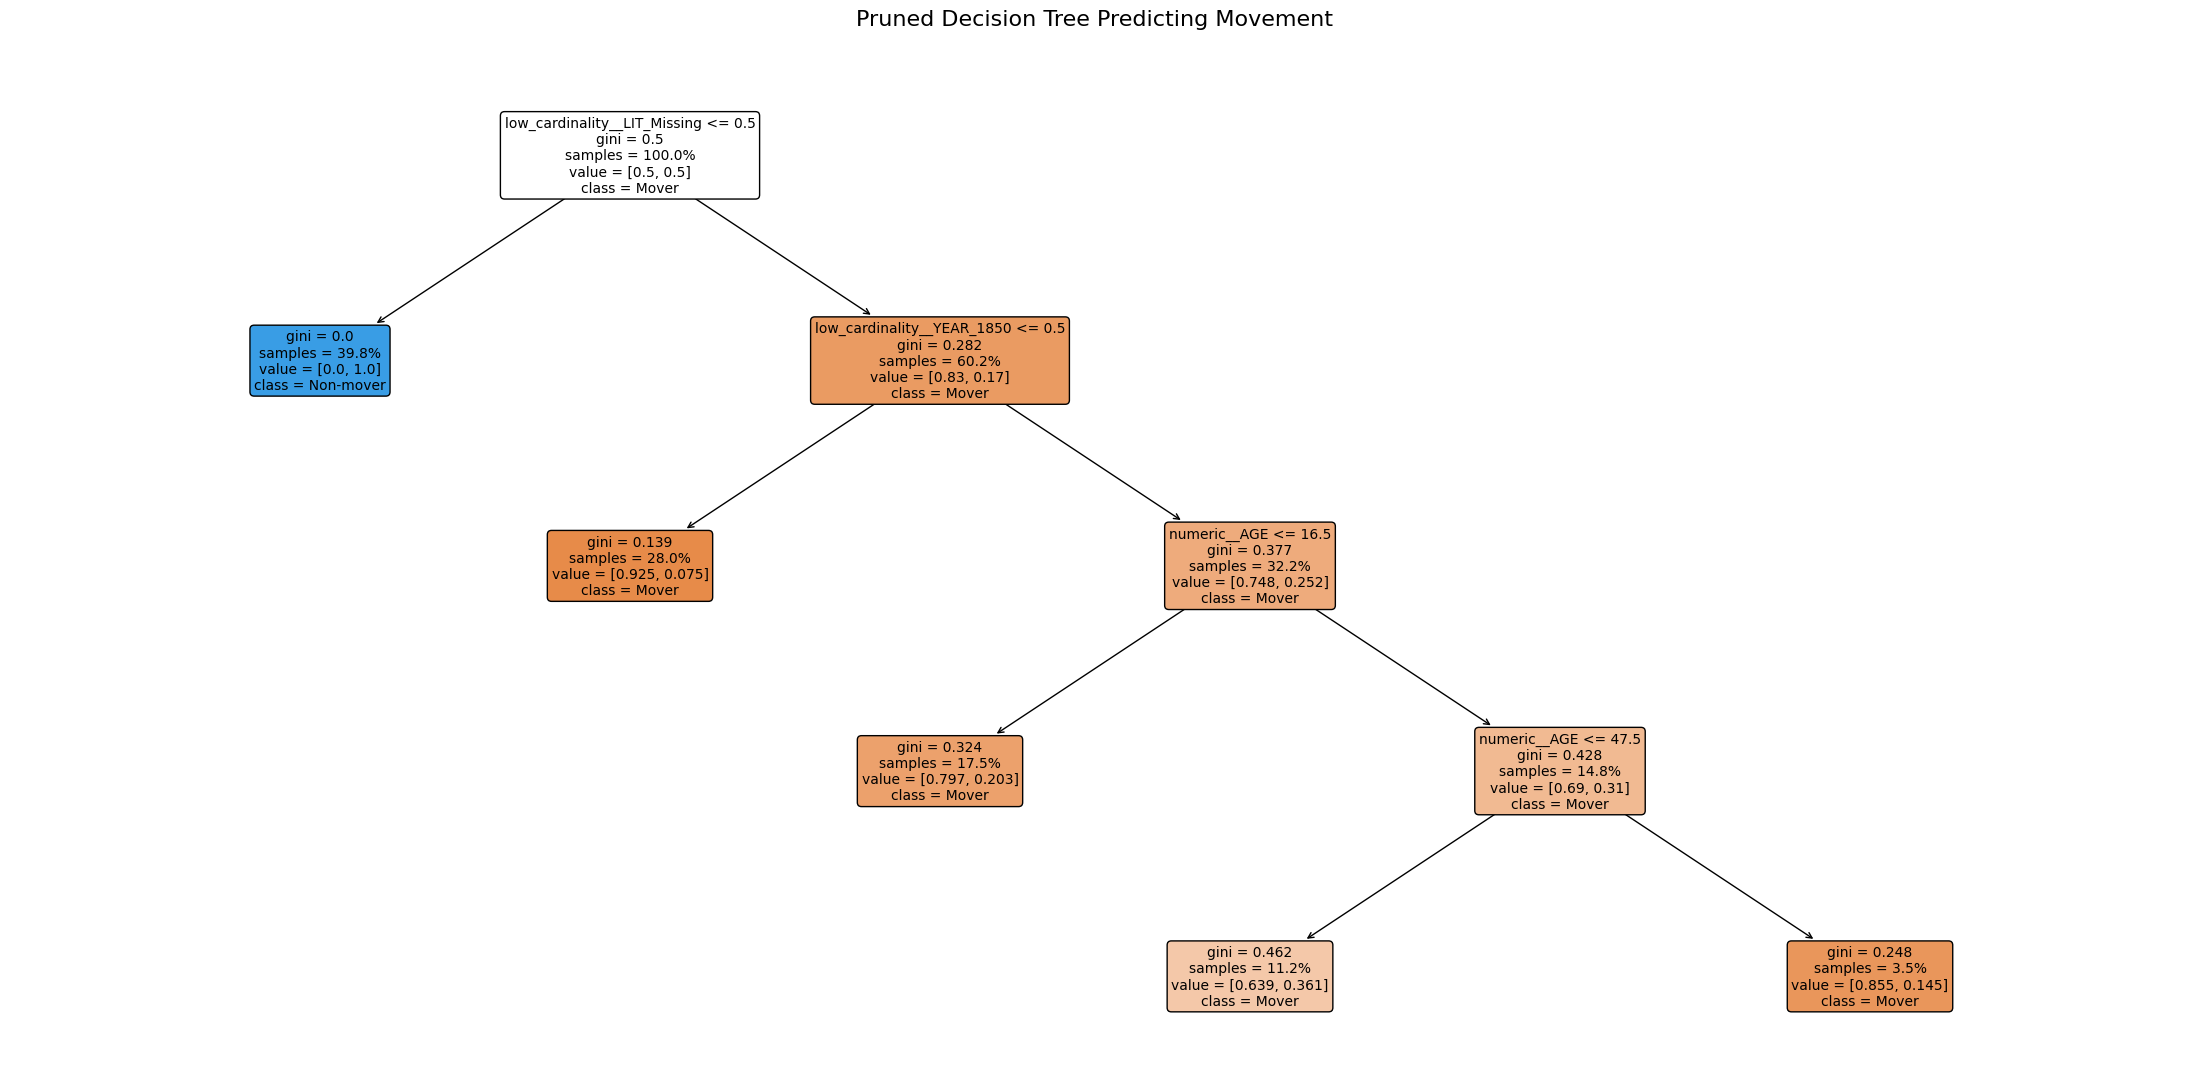

In [193]:
# ============================================================
# CREATE FULL PRUNED TREE VISUALIZATION
# ============================================================

plt.figure(
    figsize=(22, 11)
)


plot_tree(

    fitted_pruned_tree,


    # Display the real transformed feature names
    # rather than generic X[0], X[1], etc.

    feature_names=tree_feature_names,


    # IMPORTANT:
    #
    # sklearn's model classes remain numerically ordered:
    #
    #     0 = Mover
    #     1 = Non-mover
    #
    # Therefore, label them semantically in the figure.

    class_names=[
        "Mover",
        "Non-mover"
    ],


    # Color nodes using the dominant class.

    filled=True,


    # Rounded boxes improve readability.

    rounded=True,


    # Display proportions rather than only raw class counts.

    proportion=True,


    # Display impurity information.

    impurity=True,


    # Use sufficiently large text for the report.

    fontsize=10

)


plt.title(

    "Pruned Decision Tree Predicting Movement",

    fontsize=16,

    pad=20

)


plt.tight_layout()


# ------------------------------------------------------------
# SAVE HIGH-RESOLUTION TREE IMAGE
# ------------------------------------------------------------

plt.savefig(

    "pruned_decision_tree.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()

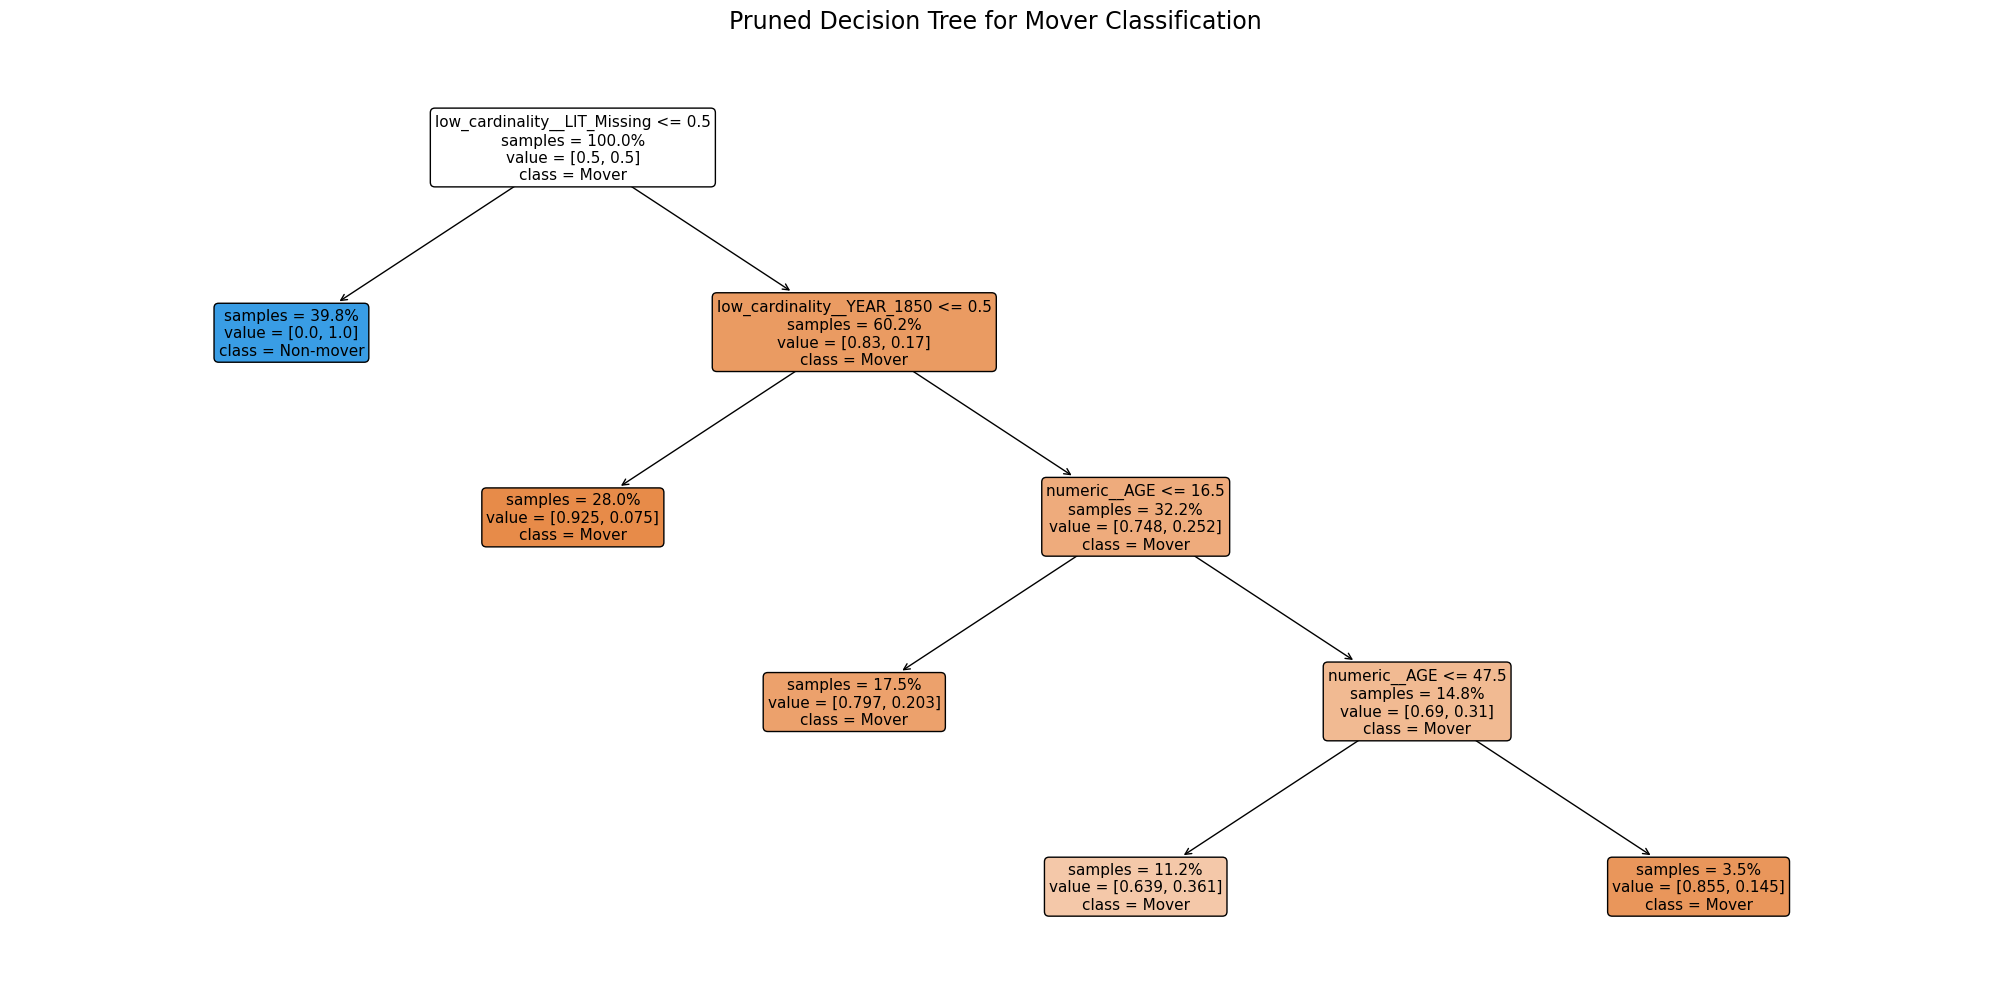

Saved simplified report figure: pruned_decision_tree_report.png


In [194]:
# ============================================================
# STEP 9S: CREATE SIMPLIFIED REPORT TREE
# ============================================================

plt.figure(
    figsize=(20, 10)
)


plot_tree(

    fitted_pruned_tree,

    feature_names=tree_feature_names,

    class_names=[
        "Mover",
        "Non-mover"
    ],

    filled=True,

    rounded=True,


    # Remove Gini impurity to make the figure easier
    # for a nontechnical reader to interpret.

    impurity=False,


    # Show proportions.

    proportion=True,

    fontsize=11

)


plt.title(

    "Pruned Decision Tree for Mover Classification",

    fontsize=17,

    pad=20

)


plt.tight_layout()


plt.savefig(

    "pruned_decision_tree_report.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


print(
    "Saved simplified report figure: "
    "pruned_decision_tree_report.png"
)

In [195]:
# ============================================================
# STEP 9T: PLOT PRUNED TREE FEATURE IMPORTANCE
# ============================================================

# Retrieve feature importance from the fitted pruned tree.

tree_importance = (

    fitted_pruned_tree
    .feature_importances_

)


# Build a DataFrame pairing importance values with the
# transformed feature names.

tree_importance_df = pd.DataFrame({

    "Feature":
        tree_feature_names,

    "Importance":
        tree_importance

})


# Keep only features actually used by the pruned tree.

tree_importance_df = (

    tree_importance_df[

        tree_importance_df[
            "Importance"
        ] > 0

    ]

    .sort_values(

        "Importance",

        ascending=True

    )

)


print(
    tree_importance_df
)

                         Feature  Importance
0                   numeric__AGE    0.012552
1     low_cardinality__YEAR_1850    0.027269
32  low_cardinality__LIT_Missing    0.960179


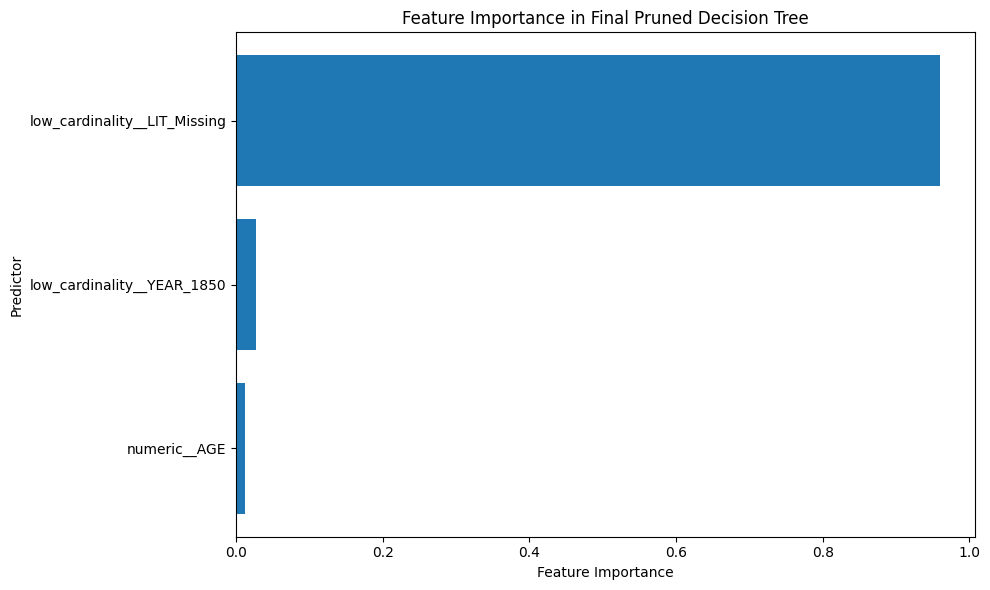

In [196]:
# ------------------------------------------------------------
# CREATE FEATURE IMPORTANCE CHART
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)


plt.barh(

    tree_importance_df[
        "Feature"
    ],

    tree_importance_df[
        "Importance"
    ]

)


plt.xlabel(
    "Feature Importance"
)


plt.ylabel(
    "Predictor"
)


plt.title(
    "Feature Importance in Final Pruned Decision Tree"
)


plt.tight_layout()


plt.savefig(

    "pruned_tree_feature_importance.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()

In [197]:
print(
    "Features actually used by tree:"
)

for index in used_feature_indices:
    print(
        tree_feature_names[index]
    )

Features actually used by tree:
numeric__AGE
low_cardinality__YEAR_1850
low_cardinality__LIT_Missing


In [200]:
# ============================================================
# CREATE COMPLETE DATASET FOR YEAR / LITERACY AUDIT
# ============================================================

# Step 3 created:
#
#     train_df = 800,000 observations
#     test_df  = 200,000 observations
#
# Recombine these two fixed datasets for DESCRIPTIVE auditing.
#
# This does NOT:
#
#     - create a new sample
#     - change the train/test split
#     - retrain a model
#     - alter the saved datasets
#
# It simply reconstructs the one-million-record final feature
# dataset so YEAR, LIT, and MOVED can be examined together.


movement_data = pd.concat(

    [
        train_df,
        test_df
    ],

    ignore_index=True

)


print(
    "Audit dataset shape:",
    movement_data.shape
)


print(
    "\nRequired columns present:"
)


for column in [
    "YEAR",
    "LIT",
    "MOVED"
]:

    print(
        column,
        column in movement_data.columns
    )

Audit dataset shape: (1000000, 15)

Required columns present:
YEAR True
LIT True
MOVED True


In [201]:
# ============================================================
# AUDIT 1: MOVEMENT DISTRIBUTION BY YEAR
# ============================================================

# IMPORTANT:
#
# Current experiment coding:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# The first table shows raw counts.
#
# The second table shows the proportion of movers and
# non-movers WITHIN each census year.


year_movement_counts = pd.crosstab(

    movement_data["YEAR"],

    movement_data["MOVED"],

    margins=True

)


year_movement_rates = pd.crosstab(

    movement_data["YEAR"],

    movement_data["MOVED"],

    normalize="index"

)


print(
    "MOVEMENT COUNTS BY YEAR"
)


print(
    year_movement_counts
)


print(
    "\nMOVEMENT PROPORTIONS WITHIN YEAR"
)


print(
    year_movement_rates.round(4)
)

MOVEMENT COUNTS BY YEAR
MOVED       0       1      All
YEAR                          
1850   241493   81250   322743
1860   206211  169129   375340
1870    25856  149121   174977
1880    26440  100500   126940
All    500000  500000  1000000

MOVEMENT PROPORTIONS WITHIN YEAR
MOVED       0       1
YEAR                 
1850   0.7483  0.2517
1860   0.5494  0.4506
1870   0.1478  0.8522
1880   0.2083  0.7917


In [202]:
# ============================================================
# AUDIT 2: SEMANTIC MOVEMENT DISTRIBUTION BY YEAR
# ============================================================

MOVER_VALUE = 0

NONMOVER_VALUE = 1


year_audit = (

    movement_data

    .groupby(
        "YEAR",
        dropna=False
    )

    .agg(

        Total_Records=(
            "MOVED",
            "size"
        ),

        Movers=(

            "MOVED",

            lambda values:
                (
                    values == MOVER_VALUE
                ).sum()

        ),

        Non_Movers=(

            "MOVED",

            lambda values:
                (
                    values == NONMOVER_VALUE
                ).sum()

        )

    )

    .reset_index()

)


year_audit[
    "Mover_Rate"
] = (

    year_audit["Movers"]

    / year_audit["Total_Records"]

)


year_audit[
    "Non_Mover_Rate"
] = (

    year_audit["Non_Movers"]

    / year_audit["Total_Records"]

)


print(
    "\nMOVEMENT AUDIT BY YEAR"
)


print(

    year_audit

    .round(4)

    .to_string(
        index=False
    )

)


MOVEMENT AUDIT BY YEAR
 YEAR  Total_Records  Movers  Non_Movers  Mover_Rate  Non_Mover_Rate
 1850         322743  241493       81250      0.7483          0.2517
 1860         375340  206211      169129      0.5494          0.4506
 1870         174977   25856      149121      0.1478          0.8522
 1880         126940   26440      100500      0.2083          0.7917


In [203]:
# ============================================================
# AUDIT 3: LITERACY MISSINGNESS BY YEAR
# ============================================================

movement_data_audit = (
    movement_data.copy()
)


movement_data_audit[
    "LIT_Status"
] = np.where(

    movement_data_audit[
        "LIT"
    ].isna(),

    "Missing",

    "Recorded"

)


lit_year_counts = pd.crosstab(

    movement_data_audit[
        "YEAR"
    ],

    movement_data_audit[
        "LIT_Status"
    ],

    margins=True

)


lit_year_rates = pd.crosstab(

    movement_data_audit[
        "YEAR"
    ],

    movement_data_audit[
        "LIT_Status"
    ],

    normalize="index"

)


print(
    "LITERACY STATUS COUNTS BY YEAR"
)


print(
    lit_year_counts
)


print(
    "\nLITERACY STATUS PROPORTIONS BY YEAR"
)


print(
    lit_year_rates.round(4)
)

LITERACY STATUS COUNTS BY YEAR
LIT_Status  Missing  Recorded      All
YEAR                                  
1850         322743         0   322743
1860         218492    156848   375340
1870          29023    145954   174977
1880          32083     94857   126940
All          602341    397659  1000000

LITERACY STATUS PROPORTIONS BY YEAR
LIT_Status  Missing  Recorded
YEAR                         
1850         1.0000    0.0000
1860         0.5821    0.4179
1870         0.1659    0.8341
1880         0.2527    0.7473


In [204]:
# ============================================================
# AUDIT 4:
# YEAR x LITERACY STATUS x MOVEMENT
# ============================================================

year_lit_movement_audit = (

    movement_data_audit

    .groupby(

        [
            "YEAR",
            "LIT_Status"
        ],

        dropna=False

    )

    .agg(

        Total_Records=(
            "MOVED",
            "size"
        ),

        Movers=(

            "MOVED",

            lambda values:
                (
                    values == MOVER_VALUE
                ).sum()

        ),

        Non_Movers=(

            "MOVED",

            lambda values:
                (
                    values == NONMOVER_VALUE
                ).sum()

        )

    )

    .reset_index()

)


year_lit_movement_audit[
    "Mover_Rate"
] = (

    year_lit_movement_audit[
        "Movers"
    ]

    / year_lit_movement_audit[
        "Total_Records"
    ]

)


year_lit_movement_audit[
    "Non_Mover_Rate"
] = (

    year_lit_movement_audit[
        "Non_Movers"
    ]

    / year_lit_movement_audit[
        "Total_Records"
    ]

)


print(
    "\nYEAR x LITERACY STATUS x MOVEMENT"
)


print(

    year_lit_movement_audit

    .round(4)

    .to_string(
        index=False
    )

)


YEAR x LITERACY STATUS x MOVEMENT
 YEAR LIT_Status  Total_Records  Movers  Non_Movers  Mover_Rate  Non_Mover_Rate
 1850    Missing         322743  241493       81250      0.7483          0.2517
 1860    Missing         218492  206211       12281      0.9438          0.0562
 1860   Recorded         156848       0      156848      0.0000          1.0000
 1870    Missing          29023   25856        3167      0.8909          0.1091
 1870   Recorded         145954       0      145954      0.0000          1.0000
 1880    Missing          32083   26440        5643      0.8241          0.1759
 1880   Recorded          94857       0       94857      0.0000          1.0000


In [205]:
# ============================================================
# REVISED PRIMARY PREDICTORS
# EXCLUDE YEAR AND LIT
# ============================================================

REVISED_PREDICTORS = [

    "URBAN",
    "GQ",
    "SEX",
    "AGE",
    "RACE",
    "BPL",
    "NATIVITY",
    "OCC1950",
    "BLIND",
    "DEAF",
    "IDIOTIC",
    "INSANE"

]


print(
    "Revised predictor count:",
    len(REVISED_PREDICTORS)
)


print(
    "Revised predictors:"
)


for feature in REVISED_PREDICTORS:
    print(feature)

Revised predictor count: 12
Revised predictors:
URBAN
GQ
SEX
AGE
RACE
BPL
NATIVITY
OCC1950
BLIND
DEAF
IDIOTIC
INSANE


In [206]:
# ============================================================
# REVISED PRIMARY MODELING EXPERIMENT
# EXCLUDE YEAR AND LIT
# ============================================================

# PURPOSE:
#
# A post-model audit found that YEAR and LIT missingness were
# strongly associated with the MOVED target.
#
# In particular:
#
#     - Mover rates differed substantially by YEAR.
#     - Recorded LIT values occurred only among non-movers in
#       the audited sample.
#
# To prevent the models from relying on census-period and
# literacy-availability patterns, this revised experiment
# completely removes:
#
#     YEAR
#     LIT
#
# The same fixed observations remain in:
#
#     X_train / y_train = 800,000 records
#     X_test  / y_test  = 200,000 records
#
# This means the experiment changes only the predictor set.
#
# CURRENT TARGET CODING:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
# ============================================================


# ------------------------------------------------------------
# REVISED PREDICTOR SET
# ------------------------------------------------------------

REVISED_PREDICTORS = [

    "URBAN",
    "GQ",
    "SEX",
    "AGE",
    "RACE",
    "BPL",
    "NATIVITY",
    "OCC1950",
    "BLIND",
    "DEAF",
    "IDIOTIC",
    "INSANE"

]


REVISED_NUMERIC_FEATURES = [

    "AGE"

]


REVISED_LOW_CARDINALITY_FEATURES = [

    "URBAN",
    "GQ",
    "SEX",
    "RACE",
    "NATIVITY",
    "BLIND",
    "DEAF",
    "IDIOTIC",
    "INSANE"

]


REVISED_HIGH_CARDINALITY_FEATURES = [

    "BPL",
    "OCC1950"

]


print(
    "Revised predictor count:",
    len(REVISED_PREDICTORS)
)


print(
    "\nRevised predictors:"
)


for feature in REVISED_PREDICTORS:

    print(feature)

Revised predictor count: 12

Revised predictors:
URBAN
GQ
SEX
AGE
RACE
BPL
NATIVITY
OCC1950
BLIND
DEAF
IDIOTIC
INSANE


In [207]:
# ============================================================
# CREATE REVISED TRAINING AND TEST PREDICTORS
# ============================================================

# Select the revised predictors from the EXISTING fixed split.
#
# This preserves the exact same training and test observations
# used in the first experiment.


X_train_revised = (

    X_train[
        REVISED_PREDICTORS
    ]

    .copy()

)


X_test_revised = (

    X_test[
        REVISED_PREDICTORS
    ]

    .copy()

)


print(
    "Revised training shape:",
    X_train_revised.shape
)


print(
    "Revised test shape:",
    X_test_revised.shape
)


print(
    "\nTraining target shape:",
    y_train.shape
)


print(
    "Test target shape:",
    y_test.shape
)

Revised training shape: (800000, 12)
Revised test shape: (200000, 12)

Training target shape: (800000,)
Test target shape: (200000,)


In [208]:
# ------------------------------------------------------------
# VERIFY YEAR AND LIT ARE EXCLUDED
# ------------------------------------------------------------

assert "YEAR" not in X_train_revised.columns
assert "LIT" not in X_train_revised.columns

assert "YEAR" not in X_test_revised.columns
assert "LIT" not in X_test_revised.columns


print(
    "\nVerified: YEAR and LIT are excluded."
)


Verified: YEAR and LIT are excluded.


In [209]:
# ============================================================
# STANDARDIZE REVISED CATEGORICAL VALUES
# ============================================================

# Convert categorical predictors into consistent string
# representations.
#
# Missing categorical values become the explicit category:
#
#     "Missing"
#
# This treatment remains appropriate for predictors such as
# NATIVITY, BPL, and OCC1950.
#
# LIT is no longer present, so LIT_Missing cannot be generated.


for column in (

    REVISED_LOW_CARDINALITY_FEATURES

    + REVISED_HIGH_CARDINALITY_FEATURES

):

    X_train_revised[column] = (

        X_train_revised[column]

        .astype("object")

        .where(
            X_train_revised[column].notna(),
            "Missing"
        )

        .astype(str)

    )


    X_test_revised[column] = (

        X_test_revised[column]

        .astype("object")

        .where(
            X_test_revised[column].notna(),
            "Missing"
        )

        .astype(str)

    )


print(
    "Revised categorical conversion complete."
)

Revised categorical conversion complete.


In [210]:
# ============================================================
# IMPORT REQUIRED TOOLS
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    KBinsDiscretizer
)

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.naive_bayes import BernoulliNB

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from sklearn.model_selection import train_test_split

In [211]:
# ============================================================
# CREATE SPARSE ONE-HOT ENCODER
# ============================================================

# Different scikit-learn versions use either:
#
#     sparse_output=True
#
# or:
#
#     sparse=True
#
# This compatibility check allows either version.


try:

    revised_onehot_encoder = OneHotEncoder(

        handle_unknown="ignore",

        sparse_output=True

    )


except TypeError:

    revised_onehot_encoder = OneHotEncoder(

        handle_unknown="ignore",

        sparse=True

    )

In [212]:
# ============================================================
# REVISED LOW-CARDINALITY PIPELINE
# ============================================================

revised_low_cardinality_pipeline = Pipeline(

    steps=[

        (
            "onehot",

            revised_onehot_encoder

        )

    ]

)

In [213]:
# ============================================================
# REUSE HIGH-CARDINALITY PIPELINE
# ============================================================

# This pipeline should already perform:
#
#     rare-category grouping
#     one-hot encoding
#
# for BPL and OCC1950.


revised_high_cardinality_pipeline = (

    high_cardinality_pipeline

)

In [214]:
# ============================================================
# REVISED ZEROR BASELINE
# ============================================================

revised_zero_r = DummyClassifier(

    strategy="most_frequent",

    random_state=RANDOM_STATE

)


revised_zero_r.fit(

    X_train_revised,

    y_train

)


revised_zero_r_predictions = (

    revised_zero_r

    .predict(
        X_test_revised
    )

)


revised_zero_r_results = evaluate_model(

    model_name="ZeroR - Revised",

    y_true=y_test,

    y_pred=revised_zero_r_predictions

)


revised_zero_r_results[
    "Mover_ROC_AUC"
] = np.nan


revised_zero_r_results[
    "Mover_PR_AUC"
] = np.nan


MODEL EVALUATION: ZeroR - Revised
Accuracy:          0.5000
Balanced Accuracy: 0.5000
Mover Precision:   0.5000
Mover Recall:      1.0000
Mover F1:          0.6667

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[100000      0]
 [100000      0]]

Semantic Confusion Matrix:
Actual mover predicted mover:         100,000
Actual mover predicted non-mover:     0
Actual non-mover predicted mover:     100,000
Actual non-mover predicted non-mover: 0


In [215]:
# ============================================================
# REVISED LOGISTIC REGRESSION PREPROCESSOR
# ============================================================

revised_numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        ),

        (
            "scaler",

            StandardScaler()
        )

    ]

)


revised_logistic_preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            revised_numeric_pipeline,

            REVISED_NUMERIC_FEATURES

        ),

        (
            "low_cardinality",

            revised_low_cardinality_pipeline,

            REVISED_LOW_CARDINALITY_FEATURES

        ),

        (
            "high_cardinality",

            revised_high_cardinality_pipeline,

            REVISED_HIGH_CARDINALITY_FEATURES

        )

    ],

    remainder="drop"

)

In [216]:
# ============================================================
# FIT REVISED LOGISTIC REGRESSION
# ============================================================

revised_logistic_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            revised_logistic_preprocessor

        ),

        (
            "model",

            LogisticRegression(

                solver="saga",

                penalty="l2",

                C=1.0,

                max_iter=500,

                random_state=RANDOM_STATE,

                n_jobs=-1

            )

        )

    ]

)


revised_logistic_start = time.time()


revised_logistic_pipeline.fit(

    X_train_revised,

    y_train

)


revised_logistic_fit_seconds = (

    time.time()

    - revised_logistic_start

)


print(
    "\nRevised Logistic Regression complete."
)


print(
    f"Fitting time: "
    f"{revised_logistic_fit_seconds:.2f} seconds"
)


Revised Logistic Regression complete.
Fitting time: 18.80 seconds


In [217]:
revised_logistic_model = (

    revised_logistic_pipeline

    .named_steps["model"]

)


print(
    "Iterations used:",
    revised_logistic_model.n_iter_
)


print(
    "Maximum iterations:",
    revised_logistic_model.max_iter
)

Iterations used: [52]
Maximum iterations: 500


In [218]:
revised_logistic_predictions = (

    revised_logistic_pipeline

    .predict(
        X_test_revised
    )

)


revised_logistic_results = evaluate_model(

    model_name="Logistic Regression - Revised",

    y_true=y_test,

    y_pred=revised_logistic_predictions

)


MODEL EVALUATION: Logistic Regression - Revised
Accuracy:          0.8976
Balanced Accuracy: 0.8976
Mover Precision:   0.8300
Mover Recall:      1.0000
Mover F1:          0.9071

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[100000      0]
 [ 20477  79523]]

Semantic Confusion Matrix:
Actual mover predicted mover:         100,000
Actual mover predicted non-mover:     0
Actual non-mover predicted mover:     20,477
Actual non-mover predicted non-mover: 79,523


In [219]:
# ============================================================
# REVISED LOGISTIC PROBABILITY METRICS
# ============================================================

revised_logistic_classes = (

    revised_logistic_pipeline

    .named_steps["model"]

    .classes_

)


revised_logistic_mover_index = (

    list(
        revised_logistic_classes
    )

    .index(
        MOVER_VALUE
    )

)


revised_logistic_mover_probability = (

    revised_logistic_pipeline

    .predict_proba(
        X_test_revised
    )

    [:, revised_logistic_mover_index]

)


y_test_mover_binary = (

    y_test == MOVER_VALUE

).astype(int)


revised_logistic_roc_auc = roc_auc_score(

    y_test_mover_binary,

    revised_logistic_mover_probability

)


revised_logistic_pr_auc = average_precision_score(

    y_test_mover_binary,

    revised_logistic_mover_probability

)


revised_logistic_results[
    "Mover_ROC_AUC"
] = revised_logistic_roc_auc


revised_logistic_results[
    "Mover_PR_AUC"
] = revised_logistic_pr_auc


print(
    f"Revised Logistic Mover ROC-AUC: "
    f"{revised_logistic_roc_auc:.4f}"
)


print(
    f"Revised Logistic Mover PR-AUC:  "
    f"{revised_logistic_pr_auc:.4f}"
)

Revised Logistic Mover ROC-AUC: 0.9156
Revised Logistic Mover PR-AUC:  0.8693


In [220]:
# ============================================================
# REVISED BERNOULLI NAIVE BAYES PREPROCESSOR
# ============================================================

revised_age_bin_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        ),

        (
            "age_bins",

            KBinsDiscretizer(

                n_bins=10,

                encode="onehot",

                strategy="quantile"

            )

        )

    ]

)


revised_nb_preprocessor = ColumnTransformer(

    transformers=[

        (
            "age_bands",

            revised_age_bin_pipeline,

            REVISED_NUMERIC_FEATURES

        ),

        (
            "low_cardinality",

            revised_low_cardinality_pipeline,

            REVISED_LOW_CARDINALITY_FEATURES

        ),

        (
            "high_cardinality",

            revised_high_cardinality_pipeline,

            REVISED_HIGH_CARDINALITY_FEATURES

        )

    ],

    remainder="drop"

)

In [221]:
# ============================================================
# FIT REVISED BERNOULLI NAIVE BAYES
# ============================================================

revised_naive_bayes_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            revised_nb_preprocessor

        ),

        (
            "model",

            BernoulliNB(

                alpha=1.0,

                binarize=None

            )

        )

    ]

)


revised_nb_start = time.time()


revised_naive_bayes_pipeline.fit(

    X_train_revised,

    y_train

)


revised_nb_fit_seconds = (

    time.time()

    - revised_nb_start

)


print(
    "\nRevised Bernoulli Naive Bayes complete."
)


print(
    f"Fitting time: "
    f"{revised_nb_fit_seconds:.2f} seconds"
)

/usr/local/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:209: FutureWarning: In version 1.3 onwards, subsample=2e5 will be used by default. Set subsample explicitly to silence this warning in the mean time. Set subsample=None to disable subsampling explicitly.
  warnings.warn(



Revised Bernoulli Naive Bayes complete.
Fitting time: 1.95 seconds


In [222]:
revised_nb_predictions = (

    revised_naive_bayes_pipeline

    .predict(
        X_test_revised
    )

)


revised_nb_results = evaluate_model(

    model_name="Bernoulli Naive Bayes - Revised",

    y_true=y_test,

    y_pred=revised_nb_predictions

)


MODEL EVALUATION: Bernoulli Naive Bayes - Revised
Accuracy:          0.8773
Balanced Accuracy: 0.8773
Mover Precision:   0.8308
Mover Recall:      0.9476
Mover F1:          0.8854

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[94760  5240]
 [19297 80703]]

Semantic Confusion Matrix:
Actual mover predicted mover:         94,760
Actual mover predicted non-mover:     5,240
Actual non-mover predicted mover:     19,297
Actual non-mover predicted non-mover: 80,703


In [223]:
# ============================================================
# REVISED NAIVE BAYES PROBABILITY METRICS
# ============================================================

revised_nb_classes = (

    revised_naive_bayes_pipeline

    .named_steps["model"]

    .classes_

)


revised_nb_mover_index = (

    list(
        revised_nb_classes
    )

    .index(
        MOVER_VALUE
    )

)


revised_nb_mover_probability = (

    revised_naive_bayes_pipeline

    .predict_proba(
        X_test_revised
    )

    [:, revised_nb_mover_index]

)


revised_nb_roc_auc = roc_auc_score(

    y_test_mover_binary,

    revised_nb_mover_probability

)


revised_nb_pr_auc = average_precision_score(

    y_test_mover_binary,

    revised_nb_mover_probability

)


revised_nb_results[
    "Mover_ROC_AUC"
] = revised_nb_roc_auc


revised_nb_results[
    "Mover_PR_AUC"
] = revised_nb_pr_auc


print(
    f"Revised Naive Bayes Mover ROC-AUC: "
    f"{revised_nb_roc_auc:.4f}"
)


print(
    f"Revised Naive Bayes Mover PR-AUC:  "
    f"{revised_nb_pr_auc:.4f}"
)

Revised Naive Bayes Mover ROC-AUC: 0.9089
Revised Naive Bayes Mover PR-AUC:  0.8612


In [224]:
# ============================================================
# REVISED DECISION TREE PREPROCESSOR
# ============================================================

revised_tree_numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        )

    ]

)


revised_tree_preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            revised_tree_numeric_pipeline,

            REVISED_NUMERIC_FEATURES

        ),

        (
            "low_cardinality",

            revised_low_cardinality_pipeline,

            REVISED_LOW_CARDINALITY_FEATURES

        ),

        (
            "high_cardinality",

            revised_high_cardinality_pipeline,

            REVISED_HIGH_CARDINALITY_FEATURES

        )

    ],

    remainder="drop"

)

In [225]:
# ============================================================
# FIT REVISED UNPRUNED DECISION TREE
# ============================================================

revised_unpruned_tree_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            revised_tree_preprocessor

        ),

        (
            "model",

            DecisionTreeClassifier(

                criterion="gini",

                splitter="best",

                max_depth=None,

                min_samples_split=2,

                min_samples_leaf=1,

                ccp_alpha=0.0,

                random_state=RANDOM_STATE

            )

        )

    ]

)


revised_tree_start = time.time()


revised_unpruned_tree_pipeline.fit(

    X_train_revised,

    y_train

)


revised_tree_fit_seconds = (

    time.time()

    - revised_tree_start

)


print(
    "\nRevised Unpruned Decision Tree complete."
)


print(
    f"Fitting time: "
    f"{revised_tree_fit_seconds:.2f} seconds"
)


Revised Unpruned Decision Tree complete.
Fitting time: 18.25 seconds


In [226]:
revised_unpruned_tree_model = (

    revised_unpruned_tree_pipeline

    .named_steps["model"]

)


revised_unpruned_node_count = (

    revised_unpruned_tree_model

    .tree_

    .node_count

)


revised_unpruned_leaf_count = (

    revised_unpruned_tree_model

    .get_n_leaves()

)


revised_unpruned_depth = (

    revised_unpruned_tree_model

    .get_depth()

)


print(
    "Revised unpruned node count:",
    revised_unpruned_node_count
)


print(
    "Revised unpruned leaf count:",
    revised_unpruned_leaf_count
)


print(
    "Revised unpruned maximum depth:",
    revised_unpruned_depth
)

Revised unpruned node count: 23503
Revised unpruned leaf count: 11752
Revised unpruned maximum depth: 103


In [227]:
revised_unpruned_train_predictions = (

    revised_unpruned_tree_pipeline

    .predict(
        X_train_revised
    )

)


revised_unpruned_train_accuracy = accuracy_score(

    y_train,

    revised_unpruned_train_predictions

)


print(
    f"Revised unpruned training accuracy: "
    f"{revised_unpruned_train_accuracy:.4f}"
)

Revised unpruned training accuracy: 0.9004


In [228]:
revised_unpruned_predictions = (

    revised_unpruned_tree_pipeline

    .predict(
        X_test_revised
    )

)


revised_unpruned_results = evaluate_model(

    model_name="Decision Tree - Unpruned Revised",

    y_true=y_test,

    y_pred=revised_unpruned_predictions

)


revised_unpruned_test_accuracy = (

    revised_unpruned_results[
        "Accuracy"
    ]

)


revised_unpruned_gap = (

    revised_unpruned_train_accuracy

    - revised_unpruned_test_accuracy

)


print(
    f"Revised unpruned train-test gap: "
    f"{revised_unpruned_gap:.4f}"
)


MODEL EVALUATION: Decision Tree - Unpruned Revised
Accuracy:          0.8959
Balanced Accuracy: 0.8959
Mover Precision:   0.8308
Mover Recall:      0.9941
Mover F1:          0.9052

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[99415   585]
 [20241 79759]]

Semantic Confusion Matrix:
Actual mover predicted mover:         99,415
Actual mover predicted non-mover:     585
Actual non-mover predicted mover:     20,241
Actual non-mover predicted non-mover: 79,759
Revised unpruned train-test gap: 0.0045


In [229]:
revised_unpruned_classes = (

    revised_unpruned_tree_model

    .classes_

)


revised_unpruned_mover_index = (

    list(
        revised_unpruned_classes
    )

    .index(
        MOVER_VALUE
    )

)


revised_unpruned_mover_probability = (

    revised_unpruned_tree_pipeline

    .predict_proba(
        X_test_revised
    )

    [:, revised_unpruned_mover_index]

)


revised_unpruned_roc_auc = roc_auc_score(

    y_test_mover_binary,

    revised_unpruned_mover_probability

)


revised_unpruned_pr_auc = average_precision_score(

    y_test_mover_binary,

    revised_unpruned_mover_probability

)


revised_unpruned_results[
    "Mover_ROC_AUC"
] = revised_unpruned_roc_auc


revised_unpruned_results[
    "Mover_PR_AUC"
] = revised_unpruned_pr_auc


revised_unpruned_results[
    "Node_Count"
] = revised_unpruned_node_count


revised_unpruned_results[
    "Leaf_Count"
] = revised_unpruned_leaf_count


revised_unpruned_results[
    "Max_Depth"
] = revised_unpruned_depth


revised_unpruned_results[
    "Training_Accuracy"
] = revised_unpruned_train_accuracy


revised_unpruned_results[
    "Train_Test_Gap"
] = revised_unpruned_gap

In [230]:
# ============================================================
# REVISED PRUNING TRAIN / VALIDATION SPLIT
# ============================================================

(
    X_revised_tree_train,
    X_revised_tree_validation,
    y_revised_tree_train,
    y_revised_tree_validation

) = train_test_split(

    X_train_revised,

    y_train,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "Revised tuning training shape:",
    X_revised_tree_train.shape
)


print(
    "Revised validation shape:",
    X_revised_tree_validation.shape
)

Revised tuning training shape: (640000, 12)
Revised validation shape: (160000, 12)


In [231]:
# ============================================================
# REVISED COST-COMPLEXITY GRID
# ============================================================

revised_alpha_grid = [

    0.0,
    0.000001,
    0.000005,
    0.00001,
    0.000025,
    0.00005,
    0.0001,
    0.00025,
    0.0005,
    0.001,
    0.0013355,
    0.002

]

In [232]:
# ============================================================
# TEST REVISED PRUNING LEVELS
# ============================================================

revised_pruning_results = []


for alpha in revised_alpha_grid:

    print(
        "\nTesting revised ccp_alpha =",
        alpha
    )


    candidate_pipeline = Pipeline(

        steps=[

            (
                "preprocessing",

                revised_tree_preprocessor

            ),

            (
                "model",

                DecisionTreeClassifier(

                    criterion="gini",

                    splitter="best",

                    max_depth=None,

                    min_samples_split=2,

                    min_samples_leaf=1,

                    ccp_alpha=alpha,

                    random_state=RANDOM_STATE

                )

            )

        ]

    )


    started = time.time()


    candidate_pipeline.fit(

        X_revised_tree_train,

        y_revised_tree_train

    )


    fit_seconds = (

        time.time()

        - started

    )


    candidate_predictions = (

        candidate_pipeline

        .predict(
            X_revised_tree_validation
        )

    )


    candidate_accuracy = accuracy_score(

        y_revised_tree_validation,

        candidate_predictions

    )


    candidate_balanced_accuracy = balanced_accuracy_score(

        y_revised_tree_validation,

        candidate_predictions

    )


    candidate_mover_precision = precision_score(

        y_revised_tree_validation,

        candidate_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    candidate_mover_recall = recall_score(

        y_revised_tree_validation,

        candidate_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    candidate_mover_f1 = f1_score(

        y_revised_tree_validation,

        candidate_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    candidate_tree = (

        candidate_pipeline

        .named_steps["model"]

    )


    revised_pruning_results.append({

        "ccp_alpha":
            alpha,

        "Validation_Accuracy":
            candidate_accuracy,

        "Validation_Balanced_Accuracy":
            candidate_balanced_accuracy,

        "Mover_Precision":
            candidate_mover_precision,

        "Mover_Recall":
            candidate_mover_recall,

        "Mover_F1":
            candidate_mover_f1,

        "Node_Count":
            candidate_tree.tree_.node_count,

        "Leaf_Count":
            candidate_tree.get_n_leaves(),

        "Max_Depth":
            candidate_tree.get_depth(),

        "Fit_Seconds":
            fit_seconds

    })


    print(
        f"Balanced Accuracy: "
        f"{candidate_balanced_accuracy:.4f}"
    )


    print(
        f"Mover Recall: "
        f"{candidate_mover_recall:.4f}"
    )


    print(
        "Nodes:",
        candidate_tree.tree_.node_count
    )


Testing revised ccp_alpha = 0.0
Balanced Accuracy: 0.8948
Mover Recall: 0.9937
Nodes: 20791

Testing revised ccp_alpha = 1e-06
Balanced Accuracy: 0.8952
Mover Recall: 0.9946
Nodes: 5797

Testing revised ccp_alpha = 5e-06
Balanced Accuracy: 0.8969
Mover Recall: 0.9997
Nodes: 229

Testing revised ccp_alpha = 1e-05
Balanced Accuracy: 0.8970
Mover Recall: 0.9999
Nodes: 149

Testing revised ccp_alpha = 2.5e-05
Balanced Accuracy: 0.8970
Mover Recall: 0.9999
Nodes: 79

Testing revised ccp_alpha = 5e-05
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 49

Testing revised ccp_alpha = 0.0001
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 33

Testing revised ccp_alpha = 0.00025
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 15

Testing revised ccp_alpha = 0.0005
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 15

Testing revised ccp_alpha = 0.001
Balanced Accuracy: 0.8969
Mover Recall: 1.0000
Nodes: 9

Testing revised ccp_alpha = 0.0013355
Balanced Accuracy: 0.8969
Mover

In [233]:
revised_pruning_results_df = pd.DataFrame(

    revised_pruning_results

)


revised_pruning_results_df = (

    revised_pruning_results_df

    .sort_values(
        "ccp_alpha"
    )

    .reset_index(
        drop=True
    )

)


print(
    "\nREVISED PRUNING RESULTS"
)


print(

    revised_pruning_results_df

    .round(6)

    .to_string(
        index=False
    )

)


revised_pruning_results_df.to_csv(

    "revised_tree_pruning_grid_no_year_no_lit.csv",

    index=False

)


REVISED PRUNING RESULTS
 ccp_alpha  Validation_Accuracy  Validation_Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Node_Count  Leaf_Count  Max_Depth  Fit_Seconds
  0.000000             0.894844                      0.894844         0.829658      0.993712  0.904305       20791       10396         98    15.073268
  0.000001             0.895188                      0.895188         0.829646      0.994600  0.904665        5797        2899         86    14.736931
  0.000005             0.896931                      0.896931         0.829263      0.999688  0.906535         229         115         26    14.736292
  0.000010             0.896981                      0.896981         0.829216      0.999900  0.906594         149          75         21    14.749466
  0.000025             0.896962                      0.896962         0.829184      0.999912  0.906580          79          40         20    14.751256
  0.000050             0.896881                      0.896881        

In [234]:
# ============================================================
# SELECT REVISED ALPHA
# ============================================================

best_revised_validation_score = (

    revised_pruning_results_df[
        "Validation_Balanced_Accuracy"
    ]

    .max()

)


acceptable_revised_score = (

    best_revised_validation_score

    - 0.005

)


acceptable_revised_trees = (

    revised_pruning_results_df[

        revised_pruning_results_df[
            "Validation_Balanced_Accuracy"
        ] >= acceptable_revised_score

    ]

    .sort_values(

        by=[

            "Node_Count",

            "Validation_Balanced_Accuracy"

        ],

        ascending=[

            True,

            False

        ]

    )

)


selected_revised_row = (

    acceptable_revised_trees

    .iloc[0]

)


REVISED_FINAL_CCP_ALPHA = float(

    selected_revised_row[
        "ccp_alpha"
    ]

)


print(
    "Best revised validation balanced accuracy:",
    round(
        best_revised_validation_score,
        6
    )
)


print(
    "Selected revised ccp_alpha:",
    REVISED_FINAL_CCP_ALPHA
)


print(
    "\nSelected validation candidate:"
)


print(
    selected_revised_row
)

Best revised validation balanced accuracy: 0.896981
Selected revised ccp_alpha: 0.002

Selected validation candidate:
ccp_alpha                        0.002000
Validation_Accuracy              0.896881
Validation_Balanced_Accuracy     0.896881
Mover_Precision                  0.829024
Mover_Recall                     1.000000
Mover_F1                         0.906521
Node_Count                       3.000000
Leaf_Count                       2.000000
Max_Depth                        1.000000
Fit_Seconds                     14.776359
Name: 11, dtype: float64


In [235]:
# ============================================================
# FINAL REVISED PRUNED TREE
# ============================================================

revised_pruned_tree_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            revised_tree_preprocessor

        ),

        (
            "model",

            DecisionTreeClassifier(

                criterion="gini",

                splitter="best",

                max_depth=None,

                min_samples_split=2,

                min_samples_leaf=1,

                ccp_alpha=REVISED_FINAL_CCP_ALPHA,

                random_state=RANDOM_STATE

            )

        )

    ]

)


revised_pruned_start = time.time()


revised_pruned_tree_pipeline.fit(

    X_train_revised,

    y_train

)


print(
    "\nRevised final pruned tree complete."
)


print(
    f"Fitting time: "
    f"{time.time() - revised_pruned_start:.2f} seconds"
)


Revised final pruned tree complete.
Fitting time: 19.13 seconds


In [236]:
revised_pruned_tree_model = (

    revised_pruned_tree_pipeline

    .named_steps["model"]

)


revised_pruned_node_count = (

    revised_pruned_tree_model

    .tree_

    .node_count

)


revised_pruned_leaf_count = (

    revised_pruned_tree_model

    .get_n_leaves()

)


revised_pruned_depth = (

    revised_pruned_tree_model

    .get_depth()

)


print(
    "Revised pruned node count:",
    revised_pruned_node_count
)


print(
    "Revised pruned leaf count:",
    revised_pruned_leaf_count
)


print(
    "Revised pruned maximum depth:",
    revised_pruned_depth
)

Revised pruned node count: 3
Revised pruned leaf count: 2
Revised pruned maximum depth: 1


In [238]:
revised_pruned_train_predictions = (

    revised_pruned_tree_pipeline

    .predict(
        X_train_revised
    )

)


revised_pruned_train_accuracy = accuracy_score(

    y_train,

    revised_pruned_train_predictions

)


revised_pruned_predictions = (

    revised_pruned_tree_pipeline

    .predict(
        X_test_revised
    )

)


revised_pruned_results = evaluate_model(

    model_name="Decision Tree - Pruned Revised",

    y_true=y_test,

    y_pred=revised_pruned_predictions

)


revised_pruned_test_accuracy = (

    revised_pruned_results[
        "Accuracy"
    ]

)


revised_pruned_gap = (

    revised_pruned_train_accuracy

    - revised_pruned_test_accuracy

)


print(
    f"Revised pruned training accuracy: "
    f"{revised_pruned_train_accuracy:.4f}"
)


print(
    f"Revised pruned test accuracy:     "
    f"{revised_pruned_test_accuracy:.4f}"
)


print(
    f"Revised pruned train-test gap:    "
    f"{revised_pruned_gap:.4f}"
)


MODEL EVALUATION: Decision Tree - Pruned Revised
Accuracy:          0.8976
Balanced Accuracy: 0.8976
Mover Precision:   0.8300
Mover Recall:      1.0000
Mover F1:          0.9071

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[100000      0]
 [ 20477  79523]]

Semantic Confusion Matrix:
Actual mover predicted mover:         100,000
Actual mover predicted non-mover:     0
Actual non-mover predicted mover:     20,477
Actual non-mover predicted non-mover: 79,523
Revised pruned training accuracy: 0.8977
Revised pruned test accuracy:     0.8976
Revised pruned train-test gap:    0.0001


In [239]:
revised_pruned_classes = (

    revised_pruned_tree_model

    .classes_

)


revised_pruned_mover_index = (

    list(
        revised_pruned_classes
    )

    .index(
        MOVER_VALUE
    )

)


revised_pruned_mover_probability = (

    revised_pruned_tree_pipeline

    .predict_proba(
        X_test_revised
    )

    [:, revised_pruned_mover_index]

)


revised_pruned_roc_auc = roc_auc_score(

    y_test_mover_binary,

    revised_pruned_mover_probability

)


revised_pruned_pr_auc = average_precision_score(

    y_test_mover_binary,

    revised_pruned_mover_probability

)


revised_pruned_results[
    "Mover_ROC_AUC"
] = revised_pruned_roc_auc


revised_pruned_results[
    "Mover_PR_AUC"
] = revised_pruned_pr_auc


revised_pruned_results[
    "Node_Count"
] = revised_pruned_node_count


revised_pruned_results[
    "Leaf_Count"
] = revised_pruned_leaf_count


revised_pruned_results[
    "Max_Depth"
] = revised_pruned_depth


revised_pruned_results[
    "Training_Accuracy"
] = revised_pruned_train_accuracy


revised_pruned_results[
    "Train_Test_Gap"
] = revised_pruned_gap


revised_pruned_results[
    "ccp_alpha"
] = REVISED_FINAL_CCP_ALPHA

In [240]:
# ============================================================
# REVISED MODEL COMPARISON
# ============================================================

revised_model_results = [

    revised_zero_r_results,

    revised_logistic_results,

    revised_nb_results,

    revised_unpruned_results,

    revised_pruned_results

]


revised_model_comparison = pd.DataFrame(

    revised_model_results

)


revised_comparison_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nREVISED MODEL COMPARISON"
)


print(

    revised_model_comparison[

        revised_comparison_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


REVISED MODEL COMPARISON
                           Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
                 ZeroR - Revised    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN
   Logistic Regression - Revised    0.8976             0.8976           0.8300        1.0000    0.9071         0.9156        0.8693
 Bernoulli Naive Bayes - Revised    0.8773             0.8773           0.8308        0.9476    0.8854         0.9089        0.8612
Decision Tree - Unpruned Revised    0.8959             0.8959           0.8308        0.9942    0.9052         0.9279        0.8885
  Decision Tree - Pruned Revised    0.8976             0.8976           0.8300        1.0000    0.9071         0.8976        0.8300


In [241]:
revised_model_comparison.to_csv(

    "revised_model_comparison_no_year_no_lit.csv",

    index=False

)


print(
    "\nSaved:"
    " revised_model_comparison_no_year_no_lit.csv"
)


Saved: revised_model_comparison_no_year_no_lit.csv


In [242]:
# ============================================================
# ORIGINAL VS REVISED PERFORMANCE
# ============================================================

original_vs_revised = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Bernoulli Naive Bayes",

        "Decision Tree - Unpruned",

        "Decision Tree - Pruned"

    ],

    "Original_Balanced_Accuracy": [

        logistic_results[
            "Balanced_Accuracy"
        ],

        naive_bayes_results[
            "Balanced_Accuracy"
        ],

        unpruned_tree_results[
            "Balanced_Accuracy"
        ],

        pruned_tree_results[
            "Balanced_Accuracy"
        ]

    ],

    "Revised_Balanced_Accuracy": [

        revised_logistic_results[
            "Balanced_Accuracy"
        ],

        revised_nb_results[
            "Balanced_Accuracy"
        ],

        revised_unpruned_results[
            "Balanced_Accuracy"
        ],

        revised_pruned_results[
            "Balanced_Accuracy"
        ]

    ]

})


original_vs_revised[
    "Accuracy_Change"
] = (

    original_vs_revised[
        "Revised_Balanced_Accuracy"
    ]

    - original_vs_revised[
        "Original_Balanced_Accuracy"
    ]

)


print(
    "\nORIGINAL VS REVISED BALANCED ACCURACY"
)


print(

    original_vs_revised

    .round(4)

    .to_string(
        index=False
    )

)


ORIGINAL VS REVISED BALANCED ACCURACY
                   Model  Original_Balanced_Accuracy  Revised_Balanced_Accuracy  Accuracy_Change
     Logistic Regression                      0.8976                     0.8976            0.000
   Bernoulli Naive Bayes                      0.8773                     0.8773           -0.000
Decision Tree - Unpruned                      0.8949                     0.8959            0.001
  Decision Tree - Pruned                      0.8976                     0.8976            0.000


In [243]:
# ============================================================
# VISUALIZE REVISED PRUNED TREE
# ============================================================

revised_fitted_preprocessor = (

    revised_pruned_tree_pipeline

    .named_steps["preprocessing"]

)


revised_tree_feature_names = (

    revised_fitted_preprocessor

    .get_feature_names_out()

)


revised_used_feature_indices = sorted(

    set(

        revised_pruned_tree_model

        .tree_

        .feature[

            revised_pruned_tree_model
            .tree_
            .feature >= 0

        ]

    )

)


print(
    "\nFeatures used by revised pruned tree:"
)


for index in revised_used_feature_indices:

    print(
        revised_tree_feature_names[index]
    )


Features used by revised pruned tree:
high_cardinality__BPL_Missing


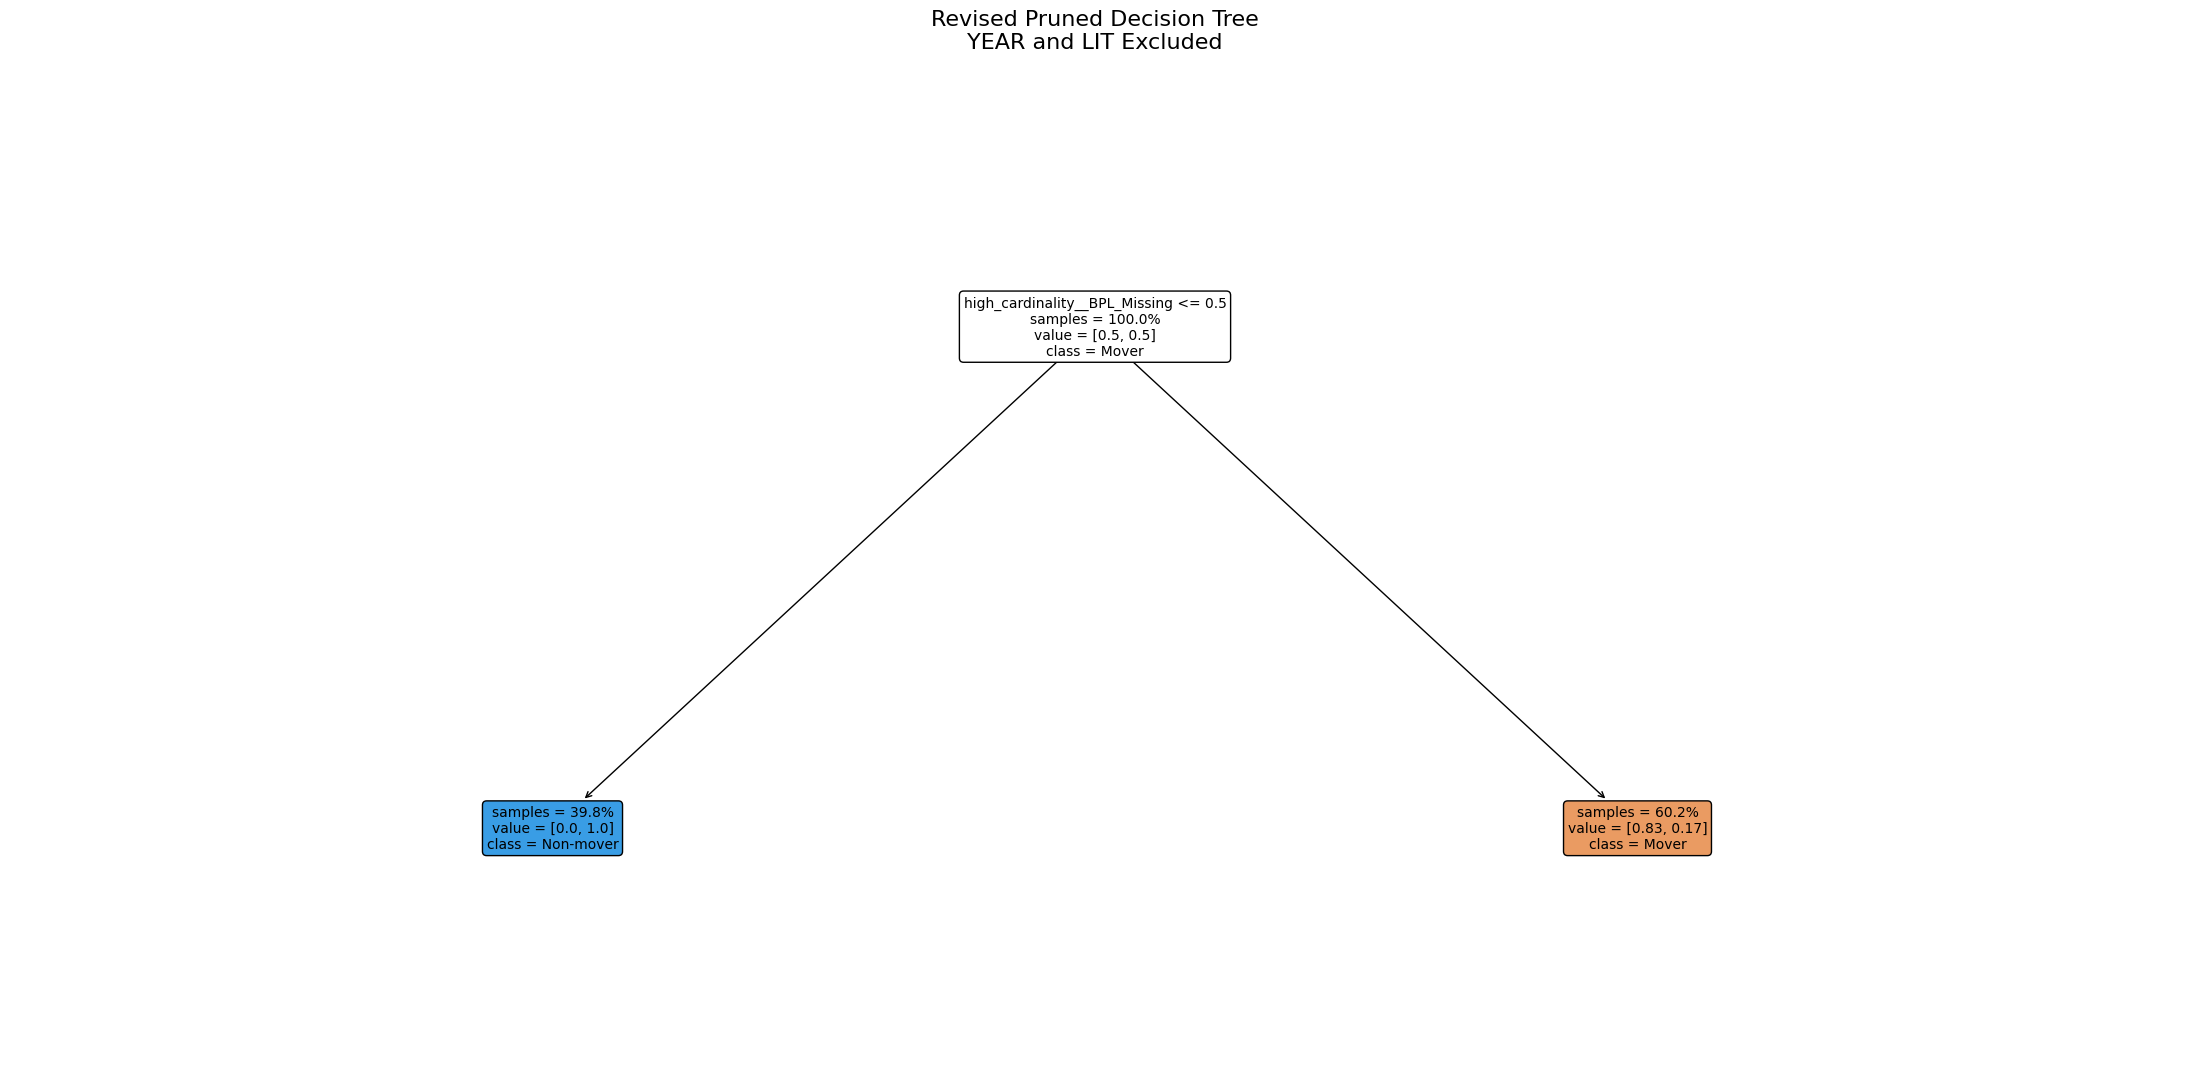

In [244]:
plt.figure(
    figsize=(22, 11)
)


plot_tree(

    revised_pruned_tree_model,

    feature_names=revised_tree_feature_names,

    class_names=[

        "Mover",

        "Non-mover"

    ],

    filled=True,

    rounded=True,

    proportion=True,

    impurity=False,

    fontsize=10

)


plt.title(

    "Revised Pruned Decision Tree\n"
    "YEAR and LIT Excluded",

    fontsize=16,

    pad=20

)


plt.tight_layout()


plt.savefig(

    "revised_pruned_tree_no_year_no_lit.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()

In [246]:
# ============================================================
# FINAL CHECK:
# FEATURES USED BY REVISED PRUNED DECISION TREE
# ============================================================

# PURPOSE:
#
# YEAR and LIT were removed from the revised experiment because
# the audit showed problematic relationships between those
# variables and the movement target.
#
# The final revised pruned tree has now been fitted using the
# remaining 12 predictors.
#
# This code identifies exactly which transformed predictor
# variables are actually used as decision splits in the final
# revised pruned tree.
#
# A predictor can exist in the modeling dataset without appearing
# in the final tree.
#
# Cost-complexity pruning retains only the splits that provide
# enough predictive value to survive the selected pruning level.
# ============================================================


# ------------------------------------------------------------
# GET FITTED PREPROCESSOR
# ------------------------------------------------------------

revised_fitted_preprocessor = (

    revised_pruned_tree_pipeline

    .named_steps["preprocessing"]

)


# ------------------------------------------------------------
# GET FITTED DECISION TREE
# ------------------------------------------------------------

revised_fitted_tree = (

    revised_pruned_tree_pipeline

    .named_steps["model"]

)


# ------------------------------------------------------------
# GET TRANSFORMED FEATURE NAMES
# ------------------------------------------------------------

# These are the predictor names AFTER preprocessing.
#
# For example:
#
#     numeric__AGE
#
# or:
#
#     low_cardinality__NATIVITY_Missing
#
# or:
#
#     high_cardinality__BPL_...
#
# This lets us connect each tree split back to its original
# census variable.


revised_tree_feature_names = (

    revised_fitted_preprocessor

    .get_feature_names_out()

)


print(
    "Total transformed predictors available:",
    len(revised_tree_feature_names)
)


# ------------------------------------------------------------
# LOCATE FEATURES USED IN DECISION NODES
# ------------------------------------------------------------

# sklearn stores the feature index used at every tree node.
#
# Leaf nodes are represented by negative feature numbers.
#
# Therefore, keep only feature indices >= 0.


revised_used_feature_indices = sorted(

    set(

        revised_fitted_tree

        .tree_

        .feature[

            revised_fitted_tree
            .tree_
            .feature >= 0

        ]

    )

)


# ------------------------------------------------------------
# PRINT FEATURES USED BY FINAL TREE
# ------------------------------------------------------------

print(
    "\nFeatures used by revised pruned tree:"
)


for feature_index in revised_used_feature_indices:

    print(

        revised_tree_feature_names[
            feature_index
        ]

    )


# ------------------------------------------------------------
# COUNT NUMBER OF UNIQUE FEATURES USED
# ------------------------------------------------------------

print(
    "\nNumber of unique predictors used:",
    len(revised_used_feature_indices)
)

Total transformed predictors available: 189

Features used by revised pruned tree:
high_cardinality__BPL_Missing

Number of unique predictors used: 1


In [247]:
# ============================================================
# REVISED PRUNED TREE FEATURE IMPORTANCE
# ============================================================

revised_feature_importance = pd.DataFrame({

    "Feature":

        revised_tree_feature_names,

    "Importance":

        revised_fitted_tree
        .feature_importances_

})


# Keep only predictors actually used by the tree.

revised_feature_importance = (

    revised_feature_importance[

        revised_feature_importance[
            "Importance"
        ] > 0

    ]

    .sort_values(

        "Importance",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nREVISED PRUNED TREE FEATURE IMPORTANCE"
)


print(

    revised_feature_importance

    .round(6)

    .to_string(
        index=False
    )

)


REVISED PRUNED TREE FEATURE IMPORTANCE
                      Feature  Importance
high_cardinality__BPL_Missing         1.0


In [248]:
# ============================================================
# VERIFY YEAR AND LIT CANNOT APPEAR
# ============================================================

used_feature_text = " ".join(

    revised_feature_importance[
        "Feature"
    ]

    .astype(str)

    .tolist()

)


assert "YEAR" not in used_feature_text

assert "LIT" not in used_feature_text


print(
    "\nVerified: YEAR and LIT do not appear "
    "in the revised pruned tree."
)


Verified: YEAR and LIT do not appear in the revised pruned tree.


In [249]:
# ============================================================
# STEP 10: INTERPRETABLE DECISION TREE SEARCH
# ============================================================

# PURPOSE:
#
# The revised cost-complexity-pruned tree retained only one
# predictor:
#
#     BPL_Missing
#
# Although this tree performs well, a one-split model provides
# limited information about interactions among the remaining
# predictors.
#
# The goal of this experiment is NOT to build the largest
# possible tree.
#
# Instead, the goal is to find a moderately sized Decision Tree
# that:
#
#     1. Uses the revised predictor set.
#     2. Excludes YEAR and LIT.
#     3. Maintains reasonable predictive performance.
#     4. Contains enough splits to provide meaningful
#        interpretation.
#     5. Remains small enough to visualize in the report.
#
# Rather than relying primarily on ccp_alpha, this experiment
# controls tree complexity directly using maximum depth and
# minimum leaf size.
# ============================================================

In [250]:
# ============================================================
# STEP 10A: TRAIN / VALIDATION DATA
# ============================================================

# Use only the original 800,000-record training dataset for
# model selection.
#
# Keep the 200,000-row test set untouched.


(
    X_interpretable_train,
    X_interpretable_validation,
    y_interpretable_train,
    y_interpretable_validation

) = train_test_split(

    X_train_revised,

    y_train,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "Interpretable tree training shape:",
    X_interpretable_train.shape
)


print(
    "Interpretable tree validation shape:",
    X_interpretable_validation.shape
)

Interpretable tree training shape: (640000, 12)
Interpretable tree validation shape: (160000, 12)


In [251]:
# ============================================================
# STEP 10B: DEFINE TREE COMPLEXITY GRID
# ============================================================

# Test trees that remain small enough for interpretation.
#
# max_depth controls how many sequential decision levels the
# tree may contain.
#
# min_samples_leaf prevents the model from creating tiny
# branches describing only a small number of observations.


depth_values = [

    3,
    4,
    5,
    6,
    7,
    8

]


leaf_values = [

    500,
    1000,
    2500,
    5000

]

In [252]:
# ============================================================
# STEP 10C: FIT INTERPRETABLE TREE CANDIDATES
# ============================================================

interpretable_tree_results = []


for depth in depth_values:

    for minimum_leaf in leaf_values:

        print(
            f"\nTesting depth={depth}, "
            f"min_samples_leaf={minimum_leaf}"
        )


        candidate_pipeline = Pipeline(

            steps=[

                (
                    "preprocessing",

                    revised_tree_preprocessor

                ),

                (
                    "model",

                    DecisionTreeClassifier(

                        criterion="gini",

                        splitter="best",

                        # Directly limit tree depth.

                        max_depth=depth,

                        # Prevent narrow terminal groups.

                        min_samples_leaf=minimum_leaf,

                        # Require at least twice the leaf
                        # minimum before a node can split.

                        min_samples_split=(
                            minimum_leaf * 2
                        ),

                        # Do not apply additional pruning here.
                        #
                        # Complexity is already controlled using
                        # depth and leaf-size constraints.

                        ccp_alpha=0.0,

                        random_state=RANDOM_STATE

                    )

                )

            ]

        )


        # ----------------------------------------------------
        # FIT MODEL
        # ----------------------------------------------------

        start_time = time.time()


        candidate_pipeline.fit(

            X_interpretable_train,

            y_interpretable_train

        )


        fit_seconds = (

            time.time()

            - start_time

        )


        # ----------------------------------------------------
        # VALIDATION PREDICTIONS
        # ----------------------------------------------------

        validation_predictions = (

            candidate_pipeline

            .predict(
                X_interpretable_validation
            )

        )


        # ----------------------------------------------------
        # PERFORMANCE METRICS
        # ----------------------------------------------------

        validation_accuracy = accuracy_score(

            y_interpretable_validation,

            validation_predictions

        )


        validation_balanced_accuracy = (
            balanced_accuracy_score(

                y_interpretable_validation,

                validation_predictions

            )
        )


        mover_precision = precision_score(

            y_interpretable_validation,

            validation_predictions,

            pos_label=MOVER_VALUE,

            zero_division=0

        )


        mover_recall = recall_score(

            y_interpretable_validation,

            validation_predictions,

            pos_label=MOVER_VALUE,

            zero_division=0

        )


        mover_f1 = f1_score(

            y_interpretable_validation,

            validation_predictions,

            pos_label=MOVER_VALUE,

            zero_division=0

        )


        # ----------------------------------------------------
        # TREE COMPLEXITY
        # ----------------------------------------------------

        candidate_tree = (

            candidate_pipeline
            .named_steps["model"]

        )


        node_count = (
            candidate_tree
            .tree_
            .node_count
        )


        leaf_count = (
            candidate_tree
            .get_n_leaves()
        )


        actual_depth = (
            candidate_tree
            .get_depth()
        )


        # ----------------------------------------------------
        # COUNT UNIQUE FEATURES ACTUALLY USED
        # ----------------------------------------------------

        fitted_preprocessor = (

            candidate_pipeline

            .named_steps["preprocessing"]

        )


        candidate_feature_names = (

            fitted_preprocessor

            .get_feature_names_out()

        )


        used_indices = set(

            candidate_tree

            .tree_

            .feature[

                candidate_tree
                .tree_
                .feature >= 0

            ]

        )


        used_feature_count = len(
            used_indices
        )


        used_feature_names = [

            candidate_feature_names[index]

            for index in sorted(
                used_indices
            )

        ]


        # ----------------------------------------------------
        # SAVE RESULT
        # ----------------------------------------------------

        interpretable_tree_results.append({

            "Max_Depth_Set":
                depth,

            "Min_Samples_Leaf":
                minimum_leaf,

            "Validation_Accuracy":
                validation_accuracy,

            "Validation_Balanced_Accuracy":
                validation_balanced_accuracy,

            "Mover_Precision":
                mover_precision,

            "Mover_Recall":
                mover_recall,

            "Mover_F1":
                mover_f1,

            "Node_Count":
                node_count,

            "Leaf_Count":
                leaf_count,

            "Actual_Depth":
                actual_depth,

            "Unique_Features_Used":
                used_feature_count,

            "Features_Used":
                ", ".join(
                    used_feature_names
                ),

            "Fit_Seconds":
                fit_seconds

        })


Testing depth=3, min_samples_leaf=500

Testing depth=3, min_samples_leaf=1000

Testing depth=3, min_samples_leaf=2500

Testing depth=3, min_samples_leaf=5000

Testing depth=4, min_samples_leaf=500

Testing depth=4, min_samples_leaf=1000

Testing depth=4, min_samples_leaf=2500

Testing depth=4, min_samples_leaf=5000

Testing depth=5, min_samples_leaf=500

Testing depth=5, min_samples_leaf=1000

Testing depth=5, min_samples_leaf=2500

Testing depth=5, min_samples_leaf=5000

Testing depth=6, min_samples_leaf=500

Testing depth=6, min_samples_leaf=1000

Testing depth=6, min_samples_leaf=2500

Testing depth=6, min_samples_leaf=5000

Testing depth=7, min_samples_leaf=500

Testing depth=7, min_samples_leaf=1000

Testing depth=7, min_samples_leaf=2500

Testing depth=7, min_samples_leaf=5000

Testing depth=8, min_samples_leaf=500

Testing depth=8, min_samples_leaf=1000

Testing depth=8, min_samples_leaf=2500

Testing depth=8, min_samples_leaf=5000


In [253]:
# ============================================================
# STEP 10D: REVIEW INTERPRETABLE TREE RESULTS
# ============================================================

interpretable_tree_results_df = pd.DataFrame(

    interpretable_tree_results

)


# Sort primarily by balanced accuracy, then prefer
# smaller trees when performance ties.

interpretable_tree_results_df = (

    interpretable_tree_results_df

    .sort_values(

        by=[

            "Validation_Balanced_Accuracy",

            "Node_Count"

        ],

        ascending=[

            False,

            True

        ]

    )

    .reset_index(
        drop=True
    )

)


display_columns = [

    "Max_Depth_Set",

    "Min_Samples_Leaf",

    "Validation_Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Node_Count",

    "Leaf_Count",

    "Actual_Depth",

    "Unique_Features_Used",

    "Features_Used"

]


print(
    "\nINTERPRETABLE TREE CANDIDATES"
)


print(

    interpretable_tree_results_df[
        display_columns
    ]

    .round(4)

    .to_string(
        index=False
    )

)


INTERPRETABLE TREE CANDIDATES
 Max_Depth_Set  Min_Samples_Leaf  Validation_Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Node_Count  Leaf_Count  Actual_Depth  Unique_Features_Used                                                                                                                                                                                                                                                                                                                                                              Features_Used
             3               500                        0.8969            0.829           1.0    0.9065           9           5             3                     3                                                                                                                                                                                                                                                                                       

In [254]:
# ============================================================
# AUDIT BPL MISSINGNESS AGAINST MOVEMENT
# ============================================================

bpl_audit = movement_data.copy()


bpl_audit[
    "BPL_Status"
] = np.where(

    bpl_audit[
        "BPL"
    ].isna(),

    "Missing",

    "Recorded"

)


bpl_movement_audit = (

    bpl_audit

    .groupby(
        "BPL_Status"
    )

    .agg(

        Total_Records=(
            "MOVED",
            "size"
        ),

        Movers=(

            "MOVED",

            lambda values:
                (
                    values == MOVER_VALUE
                ).sum()

        ),

        Non_Movers=(

            "MOVED",

            lambda values:
                (
                    values == NONMOVER_VALUE
                ).sum()

        )

    )

    .reset_index()

)


bpl_movement_audit[
    "Mover_Rate"
] = (

    bpl_movement_audit[
        "Movers"
    ]

    / bpl_movement_audit[
        "Total_Records"
    ]

)


print(

    bpl_movement_audit

    .round(4)

    .to_string(
        index=False
    )

)

BPL_Status  Total_Records  Movers  Non_Movers  Mover_Rate
   Missing         602341  500000      102341      0.8301
  Recorded         397659       0      397659      0.0000


In [255]:
# ============================================================
# AUDIT ALL REMAINING PREDICTORS FOR MISSINGNESS LEAKAGE
# ============================================================

# PURPOSE:
#
# YEAR and LIT were removed after identifying structural
# relationships with MOVED.
#
# BPL now shows another extremely strong missingness pattern:
#
#     All 500,000 movers have missing BPL.
#
# Before removing one variable at a time and repeatedly
# rebuilding the models, audit missingness for ALL remaining
# candidate predictors.
#
# We want to determine whether missingness in any other field
# nearly separates movers from non-movers.
# ============================================================


MISSINGNESS_AUDIT_FEATURES = [

    "URBAN",
    "GQ",
    "SEX",
    "AGE",
    "RACE",
    "BPL",
    "NATIVITY",
    "OCC1950",
    "BLIND",
    "DEAF",
    "IDIOTIC",
    "INSANE"

]


missingness_results = []


for feature in MISSINGNESS_AUDIT_FEATURES:

    # --------------------------------------------------------
    # MISSING OBSERVATIONS
    # --------------------------------------------------------

    missing_mask = (
        movement_data[feature]
        .isna()
    )


    missing_total = int(
        missing_mask.sum()
    )


    missing_movers = int(

        (
            missing_mask

            & (
                movement_data["MOVED"]
                == MOVER_VALUE
            )

        ).sum()

    )


    missing_nonmovers = int(

        (
            missing_mask

            & (
                movement_data["MOVED"]
                == NONMOVER_VALUE
            )

        ).sum()

    )


    if missing_total > 0:

        missing_mover_rate = (

            missing_movers

            / missing_total

        )

    else:

        missing_mover_rate = np.nan


    # --------------------------------------------------------
    # RECORDED OBSERVATIONS
    # --------------------------------------------------------

    recorded_mask = (
        ~missing_mask
    )


    recorded_total = int(
        recorded_mask.sum()
    )


    recorded_movers = int(

        (
            recorded_mask

            & (
                movement_data["MOVED"]
                == MOVER_VALUE
            )

        ).sum()

    )


    recorded_nonmovers = int(

        (
            recorded_mask

            & (
                movement_data["MOVED"]
                == NONMOVER_VALUE
            )

        ).sum()

    )


    if recorded_total > 0:

        recorded_mover_rate = (

            recorded_movers

            / recorded_total

        )

    else:

        recorded_mover_rate = np.nan


    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    missingness_results.append({

        "Feature":
            feature,

        "Missing_Total":
            missing_total,

        "Missing_Movers":
            missing_movers,

        "Missing_NonMovers":
            missing_nonmovers,

        "Missing_Mover_Rate":
            missing_mover_rate,

        "Recorded_Total":
            recorded_total,

        "Recorded_Movers":
            recorded_movers,

        "Recorded_NonMovers":
            recorded_nonmovers,

        "Recorded_Mover_Rate":
            recorded_mover_rate

    })

In [256]:
# ============================================================
# DISPLAY MISSINGNESS AUDIT
# ============================================================

missingness_audit_df = pd.DataFrame(

    missingness_results

)


# Calculate how strongly mover rates differ depending only
# on whether the variable is missing.

missingness_audit_df[
    "Mover_Rate_Difference"
] = (

    missingness_audit_df[
        "Missing_Mover_Rate"
    ]

    - missingness_audit_df[
        "Recorded_Mover_Rate"
    ]

)


# Sort by absolute difference so the most suspicious
# missingness patterns appear first.

missingness_audit_df[
    "Absolute_Rate_Difference"
] = (

    missingness_audit_df[
        "Mover_Rate_Difference"
    ]

    .abs()

)


missingness_audit_df = (

    missingness_audit_df

    .sort_values(

        "Absolute_Rate_Difference",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nMISSINGNESS VS MOVEMENT AUDIT"
)


print(

    missingness_audit_df[

        [
            "Feature",

            "Missing_Total",

            "Missing_Movers",

            "Missing_NonMovers",

            "Missing_Mover_Rate",

            "Recorded_Total",

            "Recorded_Movers",

            "Recorded_NonMovers",

            "Recorded_Mover_Rate",

            "Mover_Rate_Difference"

        ]

    ]

    .round(4)

    .to_string(
        index=False
    )

)


MISSINGNESS VS MOVEMENT AUDIT
 Feature  Missing_Total  Missing_Movers  Missing_NonMovers  Missing_Mover_Rate  Recorded_Total  Recorded_Movers  Recorded_NonMovers  Recorded_Mover_Rate  Mover_Rate_Difference
     BPL         602341          500000             102341              0.8301          397659                0              397659               0.0000                 0.8301
NATIVITY         759189          500000             259189              0.6586          240811                0              240811               0.0000                 0.6586
   BLIND         126940           26440             100500              0.2083          873060           473560              399500               0.5424                -0.3341
    DEAF         126940           26440             100500              0.2083          873060           473560              399500               0.5424                -0.3341
 IDIOTIC         126940           26440             100500              0.2083          8

In [257]:
# ============================================================
# FLAG STRONG MISSINGNESS-TARGET RELATIONSHIPS
# ============================================================

MISSINGNESS_DIFFERENCE_THRESHOLD = 0.20


suspicious_missingness = (

    missingness_audit_df[

        missingness_audit_df[
            "Absolute_Rate_Difference"
        ]

        >= MISSINGNESS_DIFFERENCE_THRESHOLD

    ]

)


print(
    "\nVARIABLES FLAGGED FOR MISSINGNESS REVIEW"
)


print(

    suspicious_missingness[

        [
            "Feature",

            "Missing_Mover_Rate",

            "Recorded_Mover_Rate",

            "Mover_Rate_Difference"

        ]

    ]

    .round(4)

    .to_string(
        index=False
    )

)


VARIABLES FLAGGED FOR MISSINGNESS REVIEW
 Feature  Missing_Mover_Rate  Recorded_Mover_Rate  Mover_Rate_Difference
     BPL              0.8301               0.0000                 0.8301
NATIVITY              0.6586               0.0000                 0.6586
   BLIND              0.2083               0.5424                -0.3341
    DEAF              0.2083               0.5424                -0.3341
 IDIOTIC              0.2083               0.5424                -0.3341
  INSANE              0.2083               0.5424                -0.3341


In [258]:
# ============================================================
# FINAL SUBSTANTIVE FEATURE SET
# REMOVE YEAR, LIT, AND BPL
# ============================================================

# PURPOSE:
#
# Data auditing identified three variables that should not be
# included in the primary substantive model:
#
#     YEAR
#     LIT
#     BPL
#
# YEAR was strongly associated with movement rates across
# census periods.
#
# LIT missingness strongly separated movers from non-movers.
#
# BPL missingness showed an even clearer relationship:
#
#     Missing BPL:
#         500,000 movers
#         102,341 non-movers
#
#     Recorded BPL:
#         0 movers
#         397,659 non-movers
#
# Because BPL availability nearly identifies the movement
# class, BPL is removed from the primary substantive model.
#
# NATIVITY and the disability variables are retained for the
# next model because they remain substantively relevant to the
# research question.
# ============================================================


FINAL_SUBSTANTIVE_PREDICTORS = [

    "URBAN",

    "GQ",

    "SEX",

    "AGE",

    "RACE",

    "NATIVITY",

    "OCC1950",

    "BLIND",

    "DEAF",

    "IDIOTIC",

    "INSANE"

]


print(
    "Final substantive predictor count:",
    len(FINAL_SUBSTANTIVE_PREDICTORS)
)


print(
    "\nFinal substantive predictors:"
)


for feature in FINAL_SUBSTANTIVE_PREDICTORS:

    print(
        " ",
        feature
    )

Final substantive predictor count: 11

Final substantive predictors:
  URBAN
  GQ
  SEX
  AGE
  RACE
  NATIVITY
  OCC1950
  BLIND
  DEAF
  IDIOTIC
  INSANE


In [259]:
# ============================================================
# CREATE FINAL SUBSTANTIVE TRAIN / TEST MATRICES
# ============================================================

# Preserve EXACTLY the same 800,000 training observations and
# 200,000 test observations.
#
# Only the predictor columns are changing.


X_train_substantive = (

    X_train[
        FINAL_SUBSTANTIVE_PREDICTORS
    ]

    .copy()

)


X_test_substantive = (

    X_test[
        FINAL_SUBSTANTIVE_PREDICTORS
    ]

    .copy()

)


print(
    "\nTraining shape:",
    X_train_substantive.shape
)


print(
    "Test shape:",
    X_test_substantive.shape
)


Training shape: (800000, 11)
Test shape: (200000, 11)


In [261]:
# ------------------------------------------------------------
# VERIFY STRUCTURAL VARIABLES ARE REMOVED
# ------------------------------------------------------------

for excluded_feature in [

    "YEAR",

    "LIT",

    "BPL"

]:

    assert (
        excluded_feature
        not in X_train_substantive.columns
    )

    assert (
        excluded_feature
        not in X_test_substantive.columns
    )


print(
    "\nVerified:"
    " YEAR, LIT, and BPL are excluded."
)


Verified: YEAR, LIT, and BPL are excluded.


In [262]:
# ============================================================
# FINAL SUBSTANTIVE PREPROCESSING GROUPS
# ============================================================

SUBSTANTIVE_NUMERIC_FEATURES = [

    "AGE"

]


SUBSTANTIVE_LOW_CARDINALITY_FEATURES = [

    "URBAN",

    "GQ",

    "SEX",

    "RACE",

    "NATIVITY",

    "BLIND",

    "DEAF",

    "IDIOTIC",

    "INSANE"

]


SUBSTANTIVE_HIGH_CARDINALITY_FEATURES = [

    "OCC1950"

]

In [263]:
# ============================================================
# PREPARE CATEGORICAL VARIABLES
# ============================================================

SUBSTANTIVE_CATEGORICAL_FEATURES = (

    SUBSTANTIVE_LOW_CARDINALITY_FEATURES

    + SUBSTANTIVE_HIGH_CARDINALITY_FEATURES

)


for column in SUBSTANTIVE_CATEGORICAL_FEATURES:

    X_train_substantive[column] = (

        X_train_substantive[column]

        .where(
            X_train_substantive[column].notna(),
            "Missing"
        )

        .astype(str)

    )


    X_test_substantive[column] = (

        X_test_substantive[column]

        .where(
            X_test_substantive[column].notna(),
            "Missing"
        )

        .astype(str)

    )

In [264]:
# ============================================================
# SUBSTANTIVE DECISION TREE PREPROCESSING
# ============================================================

substantive_tree_numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        )

    ]

)


substantive_tree_preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            substantive_tree_numeric_pipeline,

            SUBSTANTIVE_NUMERIC_FEATURES

        ),

        (
            "low_cardinality",

            revised_low_cardinality_pipeline,

            SUBSTANTIVE_LOW_CARDINALITY_FEATURES

        ),

        (
            "high_cardinality",

            revised_high_cardinality_pipeline,

            SUBSTANTIVE_HIGH_CARDINALITY_FEATURES

        )

    ],

    remainder="drop"

)

In [265]:
# ============================================================
# SEARCH FOR AN INTERPRETABLE SUBSTANTIVE TREE
# ============================================================

(
    X_sub_tree_train,
    X_sub_tree_validation,
    y_sub_tree_train,
    y_sub_tree_validation

) = train_test_split(

    X_train_substantive,

    y_train,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y_train

)


depth_values = [

    3,

    4,

    5,

    6,

    7

]


minimum_leaf_values = [

    500,

    1000,

    2500,

    5000

]


substantive_tree_search_results = []

In [266]:
for depth in depth_values:

    for minimum_leaf in minimum_leaf_values:

        candidate = Pipeline(

            steps=[

                (
                    "preprocessing",

                    substantive_tree_preprocessor

                ),

                (
                    "model",

                    DecisionTreeClassifier(

                        criterion="gini",

                        max_depth=depth,

                        min_samples_leaf=minimum_leaf,

                        min_samples_split=(
                            minimum_leaf * 2
                        ),

                        ccp_alpha=0.0,

                        random_state=RANDOM_STATE

                    )

                )

            ]

        )


        candidate.fit(

            X_sub_tree_train,

            y_sub_tree_train

        )


        validation_predictions = (

            candidate

            .predict(
                X_sub_tree_validation
            )

        )


        balanced_acc = balanced_accuracy_score(

            y_sub_tree_validation,

            validation_predictions

        )


        precision = precision_score(

            y_sub_tree_validation,

            validation_predictions,

            pos_label=MOVER_VALUE,

            zero_division=0

        )


        recall = recall_score(

            y_sub_tree_validation,

            validation_predictions,

            pos_label=MOVER_VALUE,

            zero_division=0

        )


        score_f1 = f1_score(

            y_sub_tree_validation,

            validation_predictions,

            pos_label=MOVER_VALUE,

            zero_division=0

        )


        tree_model = (

            candidate

            .named_steps["model"]

        )


        fitted_preprocessor = (

            candidate

            .named_steps["preprocessing"]

        )


        feature_names = (

            fitted_preprocessor

            .get_feature_names_out()

        )


        used_indices = sorted(

            set(

                tree_model

                .tree_

                .feature[

                    tree_model
                    .tree_
                    .feature >= 0

                ]

            )

        )


        used_names = [

            feature_names[index]

            for index in used_indices

        ]


        substantive_tree_search_results.append({

            "Depth_Set":
                depth,

            "Min_Leaf":
                minimum_leaf,

            "Balanced_Accuracy":
                balanced_acc,

            "Mover_Precision":
                precision,

            "Mover_Recall":
                recall,

            "Mover_F1":
                score_f1,

            "Nodes":
                tree_model.tree_.node_count,

            "Leaves":
                tree_model.get_n_leaves(),

            "Actual_Depth":
                tree_model.get_depth(),

            "Features_Used":
                len(used_names),

            "Feature_Names":
                ", ".join(
                    used_names
                )

        })

In [267]:
# ============================================================
# REVIEW SUBSTANTIVE TREE CANDIDATES
# ============================================================

substantive_tree_search_df = pd.DataFrame(

    substantive_tree_search_results

)


substantive_tree_search_df = (

    substantive_tree_search_df

    .sort_values(

        [
            "Balanced_Accuracy",

            "Nodes"

        ],

        ascending=[

            False,

            True

        ]

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nSUBSTANTIVE INTERPRETABLE TREE SEARCH"
)


print(

    substantive_tree_search_df

    .round(4)

    .to_string(
        index=False
    )

)


SUBSTANTIVE INTERPRETABLE TREE SEARCH
 Depth_Set  Min_Leaf  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Nodes  Leaves  Actual_Depth  Features_Used                                                                                                                                                                                                                                                                                                                                                                                                                   Feature_Names
         7      1000             0.7475           0.6742        0.9578    0.7914     95      48             7             11                                                                                                                     numeric__AGE, low_cardinality__URBAN_1, low_cardinality__URBAN_2, low_cardinality__SEX_1, low_cardinality__SEX_2, low_cardinality__NATIVITY_Missing, low_cardinality__DEAF_Missing,

In [268]:
# ============================================================
# FINAL INTERPRETABLE SUBSTANTIVE DECISION TREE
# ============================================================

# MODEL SELECTION:
#
# The constrained-tree search showed that a tree with:
#
#     max_depth = 5
#     min_samples_leaf = 5000
#
# provides a useful balance between predictive performance
# and interpretability.
#
# Validation performance:
#
#     Balanced Accuracy = 0.7468
#     Mover Precision   = 0.6768
#     Mover Recall      = 0.9448
#     Mover F1          = 0.7886
#
# Complexity:
#
#     31 nodes
#     16 leaves
#     depth 5
#
# The improvement from substantially deeper trees is very
# small, while tree complexity increases considerably.
#
# Therefore, this model is selected as the final
# INTERPRETABILITY tree.
#
# IMPORTANT:
#
# Logistic Regression remains the stronger model for pure
# prediction.
#
# This Decision Tree serves a different purpose:
#
# explaining understandable relationships among predictors.
# ============================================================


FINAL_INTERPRETABLE_DEPTH = 5

FINAL_INTERPRETABLE_MIN_LEAF = 5000

In [269]:
# ------------------------------------------------------------
# BUILD FINAL INTERPRETABLE TREE
# ------------------------------------------------------------

final_interpretable_tree_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            substantive_tree_preprocessor

        ),

        (
            "model",

            DecisionTreeClassifier(

                criterion="gini",

                splitter="best",

                max_depth=FINAL_INTERPRETABLE_DEPTH,

                min_samples_leaf=(
                    FINAL_INTERPRETABLE_MIN_LEAF
                ),

                min_samples_split=(
                    FINAL_INTERPRETABLE_MIN_LEAF * 2
                ),

                ccp_alpha=0.0,

                random_state=RANDOM_STATE

            )

        )

    ]

)

In [270]:
# ------------------------------------------------------------
# FIT ALL 800,000 TRAINING OBSERVATIONS
# ------------------------------------------------------------

import time


interpretable_start = time.time()


final_interpretable_tree_pipeline.fit(

    X_train_substantive,

    y_train

)


interpretable_fit_seconds = (

    time.time()

    - interpretable_start

)


print(
    "Final interpretable Decision Tree fitted."
)


print(
    f"Fitting time: "
    f"{interpretable_fit_seconds:.2f} seconds"
)

Final interpretable Decision Tree fitted.
Fitting time: 2.48 seconds


In [271]:
# ============================================================
# FINAL TREE COMPLEXITY
# ============================================================

final_interpretable_tree_model = (

    final_interpretable_tree_pipeline

    .named_steps["model"]

)


print(
    "Node count:",
    final_interpretable_tree_model
    .tree_
    .node_count
)


print(
    "Leaf count:",
    final_interpretable_tree_model
    .get_n_leaves()
)


print(
    "Maximum depth:",
    final_interpretable_tree_model
    .get_depth()
)

Node count: 33
Leaf count: 17
Maximum depth: 5


In [272]:
# ============================================================
# EVALUATE FINAL INTERPRETABLE TREE
# ============================================================

final_interpretable_predictions = (

    final_interpretable_tree_pipeline

    .predict(
        X_test_substantive
    )

)


final_interpretable_results = evaluate_model(

    model_name=(
        "Decision Tree - Final Interpretable"
    ),

    y_true=y_test,

    y_pred=final_interpretable_predictions

)


MODEL EVALUATION: Decision Tree - Final Interpretable
Accuracy:          0.7452
Balanced Accuracy: 0.7452
Mover Precision:   0.6755
Mover Recall:      0.9438
Mover F1:          0.7874

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[94377  5623]
 [45339 54661]]

Semantic Confusion Matrix:
Actual mover predicted mover:         94,377
Actual mover predicted non-mover:     5,623
Actual non-mover predicted mover:     45,339
Actual non-mover predicted non-mover: 54,661


In [273]:
# ============================================================
# FEATURES USED BY FINAL INTERPRETABLE TREE
# ============================================================

final_interpretable_preprocessor = (

    final_interpretable_tree_pipeline

    .named_steps["preprocessing"]

)


final_interpretable_feature_names = (

    final_interpretable_preprocessor

    .get_feature_names_out()

)


used_indices = sorted(

    set(

        final_interpretable_tree_model

        .tree_

        .feature[

            final_interpretable_tree_model
            .tree_
            .feature >= 0

        ]

    )

)


print(
    "\nFeatures used by final interpretable tree:"
)


for index in used_indices:

    print(

        final_interpretable_feature_names[
            index
        ]

    )


Features used by final interpretable tree:
numeric__AGE
low_cardinality__URBAN_2
low_cardinality__SEX_1
low_cardinality__SEX_2
low_cardinality__NATIVITY_Missing
low_cardinality__IDIOTIC_1.0


In [274]:
# ============================================================
# FINAL INTERPRETABLE TREE FEATURE IMPORTANCE
# ============================================================

final_interpretable_importance = pd.DataFrame({

    "Feature":

        final_interpretable_feature_names,

    "Importance":

        final_interpretable_tree_model
        .feature_importances_

})


final_interpretable_importance = (

    final_interpretable_importance[

        final_interpretable_importance[
            "Importance"
        ] > 0

    ]

    .sort_values(

        "Importance",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nFINAL INTERPRETABLE TREE FEATURE IMPORTANCE"
)


print(

    final_interpretable_importance

    .round(4)

    .to_string(
        index=False
    )

)


FINAL INTERPRETABLE TREE FEATURE IMPORTANCE
                          Feature  Importance
low_cardinality__NATIVITY_Missing      0.8896
                     numeric__AGE      0.0918
     low_cardinality__IDIOTIC_1.0      0.0113
           low_cardinality__SEX_1      0.0060
         low_cardinality__URBAN_2      0.0011
           low_cardinality__SEX_2      0.0000


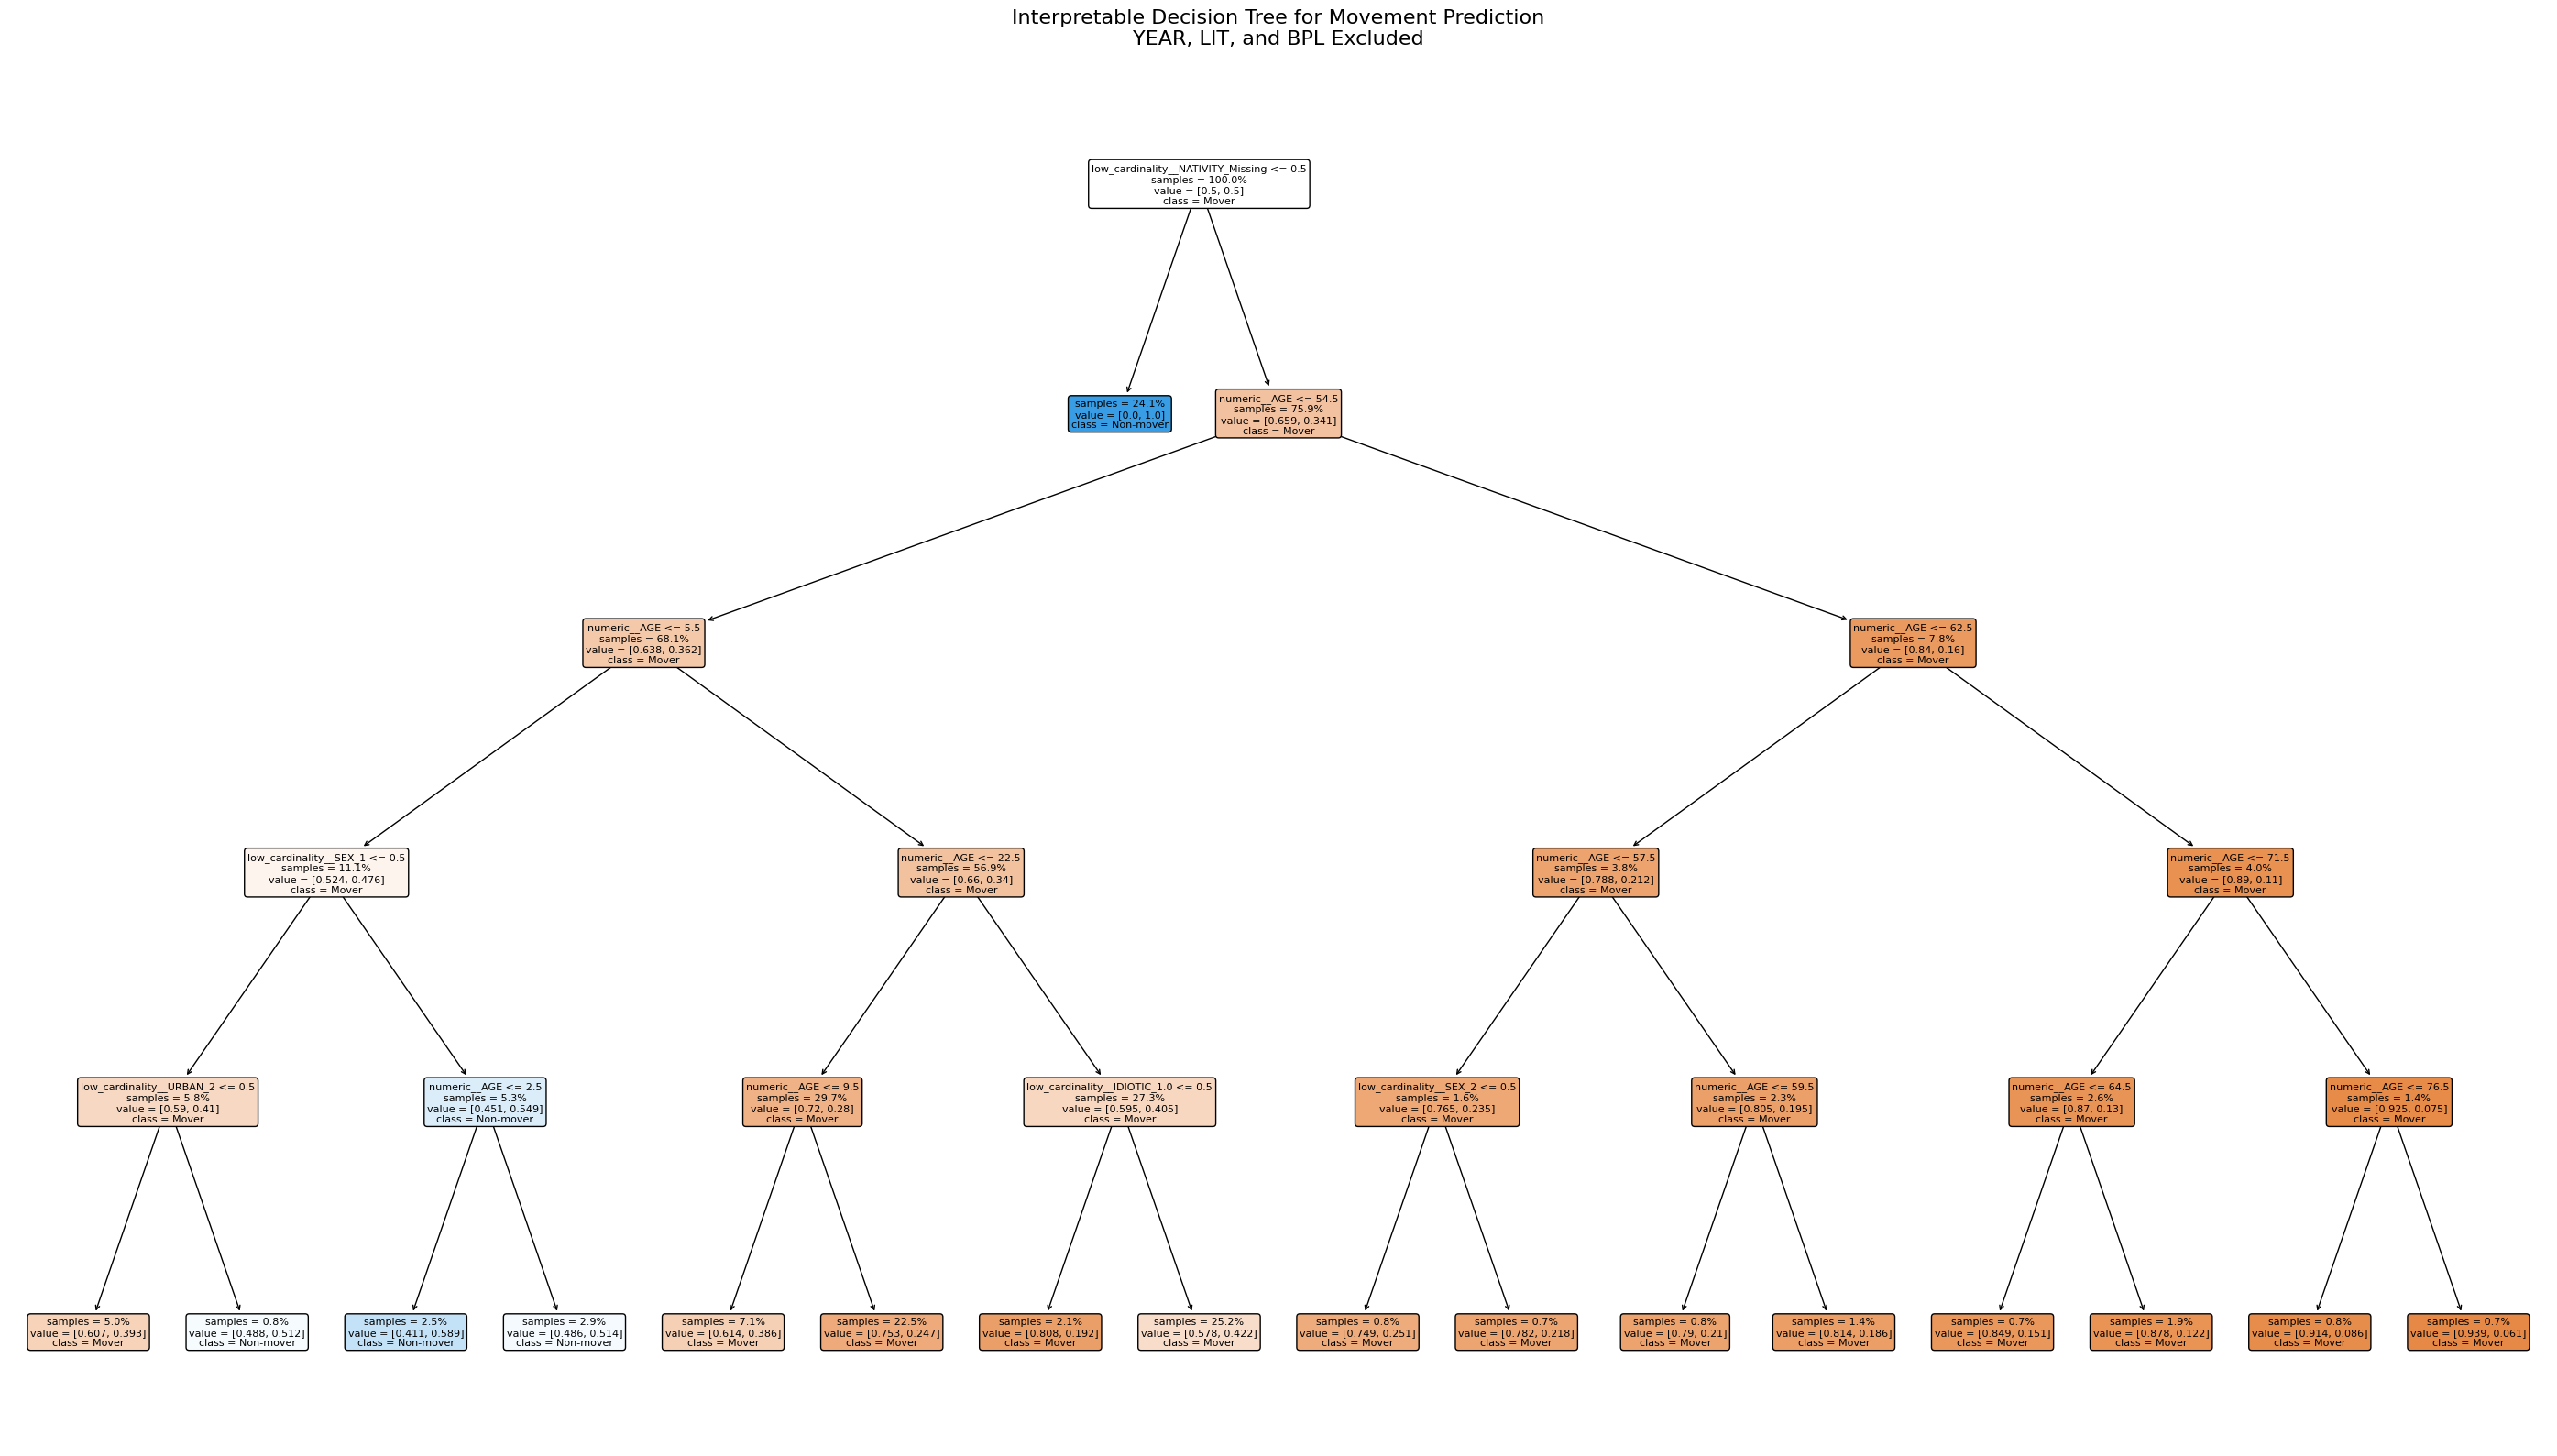

In [275]:
# ============================================================
# VISUALIZE FINAL INTERPRETABLE TREE
# ============================================================

import matplotlib.pyplot as plt

from sklearn.tree import plot_tree


plt.figure(

    figsize=(28, 16)

)


plot_tree(

    final_interpretable_tree_model,

    feature_names=(
        final_interpretable_feature_names
    ),

    class_names=[

        "Mover",

        "Non-mover"

    ],

    filled=True,

    rounded=True,

    proportion=True,

    impurity=False,

    fontsize=8

)


plt.title(

    "Interpretable Decision Tree for Movement Prediction\n"
    "YEAR, LIT, and BPL Excluded",

    fontsize=16,

    pad=20

)


plt.tight_layout()


plt.savefig(

    "final_interpretable_decision_tree.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()

In [276]:
# ============================================================
# FINAL MODEL COMPARISON
# YEAR, LIT, AND BPL EXCLUDED
# ============================================================

# Final raw predictors:
#
# URBAN, GQ, SEX, AGE, RACE, NATIVITY, OCC1950,
# BLIND, DEAF, IDIOTIC, INSANE
#
# Every model below uses the same:
#
#     800,000 training observations
#     200,000 test observations
#     target coding
#     final feature set
#
# This creates a fair apples-to-apples comparison.

In [277]:
FINAL_NUMERIC_FEATURES = [
    "AGE"
]


FINAL_LOW_CARDINALITY_FEATURES = [

    "URBAN",
    "GQ",
    "SEX",
    "RACE",
    "NATIVITY",
    "BLIND",
    "DEAF",
    "IDIOTIC",
    "INSANE"

]


FINAL_HIGH_CARDINALITY_FEATURES = [
    "OCC1950"
]

In [278]:
print(
    "Final training shape:",
    X_train_substantive.shape
)

print(
    "Final test shape:",
    X_test_substantive.shape
)


assert list(
    X_train_substantive.columns
) == FINAL_SUBSTANTIVE_PREDICTORS


for excluded in [
    "YEAR",
    "LIT",
    "BPL"
]:

    assert excluded not in X_train_substantive.columns


print(
    "Verified: YEAR, LIT, and BPL are excluded."
)

Final training shape: (800000, 11)
Final test shape: (200000, 11)
Verified: YEAR, LIT, and BPL are excluded.


In [279]:
# ============================================================
# FINAL LOGISTIC REGRESSION PREPROCESSOR
# ============================================================

final_logistic_numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )

    ]

)


final_logistic_preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",
            final_logistic_numeric_pipeline,
            FINAL_NUMERIC_FEATURES
        ),

        (
            "low_cardinality",
            revised_low_cardinality_pipeline,
            FINAL_LOW_CARDINALITY_FEATURES
        ),

        (
            "high_cardinality",
            revised_high_cardinality_pipeline,
            FINAL_HIGH_CARDINALITY_FEATURES
        )

    ],

    remainder="drop"

)

In [280]:
# ============================================================
# FIT FINAL LOGISTIC REGRESSION
# ============================================================

final_logistic_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",
            final_logistic_preprocessor
        ),

        (
            "model",
            LogisticRegression(

                solver="saga",
                penalty="l2",
                C=1.0,
                max_iter=500,
                random_state=RANDOM_STATE,
                n_jobs=-1

            )
        )

    ]

)


final_logistic_pipeline.fit(

    X_train_substantive,
    y_train

)


final_logistic_predictions = (

    final_logistic_pipeline

    .predict(
        X_test_substantive
    )

)


final_logistic_results = evaluate_model(

    model_name=(
        "Logistic Regression - Final Substantive"
    ),

    y_true=y_test,

    y_pred=final_logistic_predictions

)


MODEL EVALUATION: Logistic Regression - Final Substantive
Accuracy:          0.7403
Balanced Accuracy: 0.7403
Mover Precision:   0.6584
Mover Recall:      0.9991
Mover F1:          0.7937

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[99906    94]
 [51838 48162]]

Semantic Confusion Matrix:
Actual mover predicted mover:         99,906
Actual mover predicted non-mover:     94
Actual non-mover predicted mover:     51,838
Actual non-mover predicted non-mover: 48,162


In [281]:
final_logistic_classes = (

    final_logistic_pipeline

    .named_steps["model"]

    .classes_

)


final_logistic_mover_index = (

    list(
        final_logistic_classes
    )

    .index(
        MOVER_VALUE
    )

)


final_logistic_mover_probability = (

    final_logistic_pipeline

    .predict_proba(
        X_test_substantive
    )

    [:, final_logistic_mover_index]

)


final_logistic_results[
    "Mover_ROC_AUC"
] = roc_auc_score(

    y_test_mover_binary,

    final_logistic_mover_probability

)


final_logistic_results[
    "Mover_PR_AUC"
] = average_precision_score(

    y_test_mover_binary,

    final_logistic_mover_probability

)

In [282]:
# ============================================================
# FINAL BERNOULLI NAIVE BAYES PREPROCESSOR
# ============================================================

final_nb_age_pipeline = Pipeline(

    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "age_bins",
            KBinsDiscretizer(

                n_bins=10,
                encode="onehot",
                strategy="quantile"

            )
        )

    ]

)


final_nb_preprocessor = ColumnTransformer(

    transformers=[

        (
            "age_bands",
            final_nb_age_pipeline,
            FINAL_NUMERIC_FEATURES
        ),

        (
            "low_cardinality",
            revised_low_cardinality_pipeline,
            FINAL_LOW_CARDINALITY_FEATURES
        ),

        (
            "high_cardinality",
            revised_high_cardinality_pipeline,
            FINAL_HIGH_CARDINALITY_FEATURES
        )

    ],

    remainder="drop"

)

In [283]:
# ============================================================
# FIT FINAL BERNOULLI NAIVE BAYES
# ============================================================

final_nb_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",
            final_nb_preprocessor
        ),

        (
            "model",
            BernoulliNB(

                alpha=1.0,
                binarize=None

            )
        )

    ]

)


final_nb_pipeline.fit(

    X_train_substantive,
    y_train

)


final_nb_predictions = (

    final_nb_pipeline

    .predict(
        X_test_substantive
    )

)


final_nb_results = evaluate_model(

    model_name=(
        "Bernoulli Naive Bayes - Final Substantive"
    ),

    y_true=y_test,

    y_pred=final_nb_predictions

)

/usr/local/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:209: FutureWarning: In version 1.3 onwards, subsample=2e5 will be used by default. Set subsample explicitly to silence this warning in the mean time. Set subsample=None to disable subsampling explicitly.
  warnings.warn(



MODEL EVALUATION: Bernoulli Naive Bayes - Final Substantive
Accuracy:          0.7196
Balanced Accuracy: 0.7195
Mover Precision:   0.6511
Mover Recall:      0.9460
Mover F1:          0.7713

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[94605  5395]
 [50695 49305]]

Semantic Confusion Matrix:
Actual mover predicted mover:         94,605
Actual mover predicted non-mover:     5,395
Actual non-mover predicted mover:     50,695
Actual non-mover predicted non-mover: 49,305


In [284]:
final_nb_classes = (

    final_nb_pipeline

    .named_steps["model"]

    .classes_

)


final_nb_mover_index = (

    list(
        final_nb_classes
    )

    .index(
        MOVER_VALUE
    )

)


final_nb_mover_probability = (

    final_nb_pipeline

    .predict_proba(
        X_test_substantive
    )

    [:, final_nb_mover_index]

)


final_nb_results[
    "Mover_ROC_AUC"
] = roc_auc_score(

    y_test_mover_binary,

    final_nb_mover_probability

)


final_nb_results[
    "Mover_PR_AUC"
] = average_precision_score(

    y_test_mover_binary,

    final_nb_mover_probability

)

In [285]:
# ============================================================
# FINAL UNPRUNED SUBSTANTIVE DECISION TREE
# ============================================================

final_unpruned_substantive_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",
            substantive_tree_preprocessor
        ),

        (
            "model",
            DecisionTreeClassifier(

                criterion="gini",
                splitter="best",
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                ccp_alpha=0.0,
                random_state=RANDOM_STATE

            )
        )

    ]

)


final_unpruned_substantive_pipeline.fit(

    X_train_substantive,
    y_train

)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['AGE']),
                                                 ('low_cardinality',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['URBAN', 'GQ', 'SEX', 'RACE',
                                                   'NATIVITY', 'BLIND', 'DEAF',
                                                   'IDIOTIC', 'INSANE']),
                                                 ('high_cardinality',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=100))]),
                                                  ['OCC1950'])])),
                ('model', DecisionTreeClassifier(random_state=6480))])

In [286]:
final_unpruned_substantive_model = (

    final_unpruned_substantive_pipeline

    .named_steps["model"]

)


final_unpruned_substantive_predictions = (

    final_unpruned_substantive_pipeline

    .predict(
        X_test_substantive
    )

)


final_unpruned_substantive_results = evaluate_model(

    model_name=(
        "Decision Tree - Unpruned Final Substantive"
    ),

    y_true=y_test,

    y_pred=(
        final_unpruned_substantive_predictions
    )

)


MODEL EVALUATION: Decision Tree - Unpruned Final Substantive
Accuracy:          0.7453
Balanced Accuracy: 0.7453
Mover Precision:   0.6893
Mover Recall:      0.8933
Mover F1:          0.7781

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[89332 10668]
 [40270 59730]]

Semantic Confusion Matrix:
Actual mover predicted mover:         89,332
Actual mover predicted non-mover:     10,668
Actual non-mover predicted mover:     40,270
Actual non-mover predicted non-mover: 59,730


In [287]:
final_unpruned_substantive_results[
    "Node_Count"
] = (

    final_unpruned_substantive_model

    .tree_

    .node_count

)


final_unpruned_substantive_results[
    "Leaf_Count"
] = (

    final_unpruned_substantive_model

    .get_n_leaves()

)


final_unpruned_substantive_results[
    "Max_Depth"
] = (

    final_unpruned_substantive_model

    .get_depth()

)

In [288]:
# ============================================================
# INTERPRETABLE TREE PROBABILITY METRICS
# ============================================================

final_interpretable_classes = (

    final_interpretable_tree_model

    .classes_

)


final_interpretable_mover_index = (

    list(
        final_interpretable_classes
    )

    .index(
        MOVER_VALUE
    )

)


final_interpretable_mover_probability = (

    final_interpretable_tree_pipeline

    .predict_proba(
        X_test_substantive
    )

    [:, final_interpretable_mover_index]

)


final_interpretable_results[
    "Mover_ROC_AUC"
] = roc_auc_score(

    y_test_mover_binary,

    final_interpretable_mover_probability

)


final_interpretable_results[
    "Mover_PR_AUC"
] = average_precision_score(

    y_test_mover_binary,

    final_interpretable_mover_probability

)


final_interpretable_results[
    "Node_Count"
] = 33


final_interpretable_results[
    "Leaf_Count"
] = 17


final_interpretable_results[
    "Max_Depth"
] = 5

In [289]:
# ============================================================
# FINAL SUBSTANTIVE MODEL COMPARISON
# ============================================================

final_substantive_model_results = [

    revised_zero_r_results,

    final_logistic_results,

    final_nb_results,

    final_unpruned_substantive_results,

    final_interpretable_results

]


final_substantive_comparison = pd.DataFrame(

    final_substantive_model_results

)


final_display_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nFINAL SUBSTANTIVE MODEL COMPARISON"
)


print(

    final_substantive_comparison[

        final_display_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


FINAL SUBSTANTIVE MODEL COMPARISON
                                     Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
                           ZeroR - Revised    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN
   Logistic Regression - Final Substantive    0.7403             0.7403           0.6584        0.9991    0.7937         0.7833        0.7251
 Bernoulli Naive Bayes - Final Substantive    0.7196             0.7195           0.6511        0.9460    0.7713         0.7563        0.6997
Decision Tree - Unpruned Final Substantive    0.7453             0.7453           0.6893        0.8933    0.7781            NaN           NaN
       Decision Tree - Final Interpretable    0.7452             0.7452           0.6755        0.9438    0.7874         0.8096        0.7497


In [290]:
final_substantive_comparison.to_csv(

    "final_substantive_model_comparison.csv",

    index=False

)

In [291]:
# ============================================================
# COMPLETE FINAL UNPRUNED TREE PROBABILITY METRICS
# ============================================================

final_unpruned_classes = (

    final_unpruned_substantive_pipeline

    .named_steps["model"]

    .classes_

)


final_unpruned_mover_index = (

    list(
        final_unpruned_classes
    )

    .index(
        MOVER_VALUE
    )

)


final_unpruned_mover_probability = (

    final_unpruned_substantive_pipeline

    .predict_proba(
        X_test_substantive
    )

    [:, final_unpruned_mover_index]

)


final_unpruned_roc_auc = roc_auc_score(

    y_test_mover_binary,

    final_unpruned_mover_probability

)


final_unpruned_pr_auc = average_precision_score(

    y_test_mover_binary,

    final_unpruned_mover_probability

)


print(
    f"Final Unpruned Tree Mover ROC-AUC: "
    f"{final_unpruned_roc_auc:.4f}"
)


print(
    f"Final Unpruned Tree Mover PR-AUC: "
    f"{final_unpruned_pr_auc:.4f}"
)

Final Unpruned Tree Mover ROC-AUC: 0.8197
Final Unpruned Tree Mover PR-AUC: 0.7693


In [292]:
final_unpruned_substantive_results[
    "Mover_ROC_AUC"
] = final_unpruned_roc_auc


final_unpruned_substantive_results[
    "Mover_PR_AUC"
] = final_unpruned_pr_auc

In [293]:
# ============================================================
# STEP 11: LINEAR SUPPORT VECTOR MACHINE
# ============================================================

# PURPOSE:
#
# The assignment requires evaluation of a Support Vector
# Machine model.
#
# The final substantive experiment uses the same 11 predictors:
#
#     URBAN
#     GQ
#     SEX
#     AGE
#     RACE
#     NATIVITY
#     OCC1950
#     BLIND
#     DEAF
#     IDIOTIC
#     INSANE
#
# YEAR, LIT, and BPL remain excluded because the previous
# data-quality audit showed that their availability patterns
# were strongly associated with the target.
#
# TARGET CODING:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# The SVM will use the SAME:
#
#     800,000 training observations
#     200,000 test observations
#
# as the other final substantive models.
#
# ------------------------------------------------------------
# WHY LINEARSVC?
# ------------------------------------------------------------
#
# A Support Vector Machine can use either linear or nonlinear
# decision boundaries.
#
# For this experiment, the data become high-dimensional after
# one-hot encoding and contain hundreds of thousands of
# training observations.
#
# We will therefore use LinearSVC for the primary SVM test.
#
# The model will be tuned using several C values.
#
# C controls the regularization tradeoff:
#
#     Smaller C
#         -> stronger regularization
#         -> simpler / wider-margin solution
#
#     Larger C
#         -> weaker regularization
#         -> greater emphasis on fitting training observations
#
# We will choose C using TRAINING / VALIDATION data only.
#
# The final 200,000-row test set remains untouched until the
# selected SVM is fitted on all 800,000 training observations.
# ============================================================

In [294]:
# ============================================================
# STEP 11A: IMPORT SVM TOOLS
# ============================================================

import time

import numpy as np
import pandas as pd

from sklearn.svm import LinearSVC

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [295]:
# ============================================================
# STEP 11B: VERIFY FINAL SUBSTANTIVE DATA
# ============================================================

print(
    "SVM training shape:",
    X_train_substantive.shape
)


print(
    "SVM test shape:",
    X_test_substantive.shape
)


print(
    "\nTraining target distribution:"
)


print(

    y_train

    .value_counts()

    .sort_index()

)


print(
    "\nTest target distribution:"
)


print(

    y_test

    .value_counts()

    .sort_index()

)

SVM training shape: (800000, 11)
SVM test shape: (200000, 11)

Training target distribution:
0    400000
1    400000
Name: MOVED, dtype: int64

Test target distribution:
0    100000
1    100000
Name: MOVED, dtype: int64


In [296]:
# ------------------------------------------------------------
# VERIFY EXCLUDED VARIABLES
# ------------------------------------------------------------

for excluded_feature in [

    "YEAR",

    "LIT",

    "BPL"

]:

    assert (
        excluded_feature
        not in X_train_substantive.columns
    )

    assert (
        excluded_feature
        not in X_test_substantive.columns
    )


print(
    "\nVerified:"
    " YEAR, LIT, and BPL are not available to the SVM."
)


Verified: YEAR, LIT, and BPL are not available to the SVM.


In [297]:
# ============================================================
# STEP 11C: BUILD SVM PREPROCESSOR
# ============================================================

# AGE is quantitative and should be scaled.
#
# The categorical predictors are already represented as
# categorical string values in X_train_substantive and
# X_test_substantive.
#
# We reuse the working one-hot preprocessing from the final
# substantive experiment.


svm_numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        ),

        (
            "scaler",

            StandardScaler()
        )

    ]

)

In [298]:
svm_preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            svm_numeric_pipeline,

            [
                "AGE"
            ]

        ),

        (
            "low_cardinality",

            revised_low_cardinality_pipeline,

            [

                "URBAN",

                "GQ",

                "SEX",

                "RACE",

                "NATIVITY",

                "BLIND",

                "DEAF",

                "IDIOTIC",

                "INSANE"

            ]

        ),

        (
            "high_cardinality",

            revised_high_cardinality_pipeline,

            [
                "OCC1950"
            ]

        )

    ],

    remainder="drop"

)

In [299]:
# ============================================================
# STEP 11D: CREATE SVM TUNING SAMPLE
# ============================================================

# Use 200,000 observations from the TRAINING dataset only.
#
# This tuning sample contains:
#
#     100,000 movers
#     100,000 non-movers
#
# The final 200,000-row test dataset remains untouched.


X_svm_tune, _, y_svm_tune, _ = train_test_split(

    X_train_substantive,

    y_train,

    train_size=200_000,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "SVM tuning sample:",
    X_svm_tune.shape
)


print(
    "\nSVM tuning class counts:"
)


print(

    y_svm_tune

    .value_counts()

    .sort_index()

)

SVM tuning sample: (200000, 11)

SVM tuning class counts:
0    100000
1    100000
Name: MOVED, dtype: int64


In [300]:
# ============================================================
# STEP 11E: CREATE SVM TUNING TRAIN / VALIDATION SET
# ============================================================

(
    X_svm_train,
    X_svm_validation,
    y_svm_train,
    y_svm_validation

) = train_test_split(

    X_svm_tune,

    y_svm_tune,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y_svm_tune

)


print(
    "SVM tuning training shape:",
    X_svm_train.shape
)


print(
    "SVM validation shape:",
    X_svm_validation.shape
)

SVM tuning training shape: (160000, 11)
SVM validation shape: (40000, 11)


In [301]:
# ============================================================
# STEP 11F: DEFINE SVM REGULARIZATION GRID
# ============================================================

SVM_C_VALUES = [

    0.01,

    0.1,

    1.0,

    10.0

]


print(
    "SVM C values:"
)


for c_value in SVM_C_VALUES:

    print(
        c_value
    )

SVM C values:
0.01
0.1
1.0
10.0


In [305]:
# ============================================================
# STEP 11G: TUNE LINEAR SVM
# COMPLETE CORRECTED CELL
# ============================================================

# PURPOSE:
#
# Test several regularization values for LinearSVC using only
# the SVM training / validation subset.
#
# The final 200,000-row test set remains untouched.
#
# CURRENT TARGET CODING:
#
#     MOVED = 0 -> MOVER
#     MOVED = 1 -> NON-MOVER
#
# IMPORTANT:
#
# LinearSVC's decision_function produces positive scores for
# class 1 by default.
#
# Because MOVERS are class 0 in this experiment, the decision
# scores are multiplied by -1 when calculating mover ROC-AUC
# and PR-AUC.


svm_tuning_results = []


for c_value in SVM_C_VALUES:

    print(
        "\n" + "=" * 60
    )

    print(
        f"Testing LinearSVC C = {c_value}"
    )

    print(
        "=" * 60
    )


    # --------------------------------------------------------
    # CREATE CANDIDATE PIPELINE
    # --------------------------------------------------------

    svm_candidate = Pipeline(

        steps=[

            (
                "preprocessing",

                svm_preprocessor

            ),

            (
                "model",

                LinearSVC(

                    C=c_value,

                    class_weight=None,

                    max_iter=5000,

                    random_state=RANDOM_STATE

                )

            )

        ]

    )


    # --------------------------------------------------------
    # FIT CANDIDATE MODEL
    # --------------------------------------------------------

    start_time = time.time()


    svm_candidate.fit(

        X_svm_train,

        y_svm_train

    )


    fit_seconds = (

        time.time()

        - start_time

    )


    # --------------------------------------------------------
    # CREATE VALIDATION CLASS PREDICTIONS
    # --------------------------------------------------------

    svm_validation_predictions = (

        svm_candidate

        .predict(
            X_svm_validation
        )

    )


    # --------------------------------------------------------
    # BASIC VALIDATION METRICS
    # --------------------------------------------------------

    validation_accuracy = accuracy_score(

        y_svm_validation,

        svm_validation_predictions

    )


    validation_balanced_accuracy = balanced_accuracy_score(

        y_svm_validation,

        svm_validation_predictions

    )


    # --------------------------------------------------------
    # MOVER PRECISION
    # --------------------------------------------------------

    validation_mover_precision = precision_score(

        y_svm_validation,

        svm_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    # --------------------------------------------------------
    # MOVER RECALL
    # --------------------------------------------------------

    validation_mover_recall = recall_score(

        y_svm_validation,

        svm_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    # --------------------------------------------------------
    # MOVER F1
    # --------------------------------------------------------

    validation_mover_f1 = f1_score(

        y_svm_validation,

        svm_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    # --------------------------------------------------------
    # OBTAIN SVM DECISION SCORES
    # --------------------------------------------------------

    # LinearSVC does not provide predict_proba().
    #
    # decision_function() gives the signed distance from
    # the separating hyperplane.
    #
    # Positive values correspond to class 1.
    #
    # In THIS experiment:
    #
    #     class 0 = Mover
    #     class 1 = Non-mover
    #
    # Therefore multiply by -1 so HIGHER values correspond
    # to stronger mover predictions.

    raw_decision_scores = (

        svm_candidate

        .decision_function(
            X_svm_validation
        )

    )


    mover_decision_scores = (

        -raw_decision_scores

    )


    # --------------------------------------------------------
    # CREATE BINARY EVALUATION TARGET
    # --------------------------------------------------------

    # For ROC-AUC / PR-AUC:
    #
    #     1 = Mover
    #     0 = Non-mover
    #
    # This is only an evaluation representation.
    #
    # It does NOT modify y_svm_validation.

    y_svm_validation_mover = (

        y_svm_validation
        == MOVER_VALUE

    ).astype(int)


    # --------------------------------------------------------
    # MOVER ROC-AUC
    # --------------------------------------------------------

    validation_roc_auc = roc_auc_score(

        y_svm_validation_mover,

        mover_decision_scores

    )


    # --------------------------------------------------------
    # MOVER PR-AUC
    # --------------------------------------------------------

    validation_pr_auc = average_precision_score(

        y_svm_validation_mover,

        mover_decision_scores

    )


    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    svm_tuning_results.append({

        "C":
            c_value,

        "Accuracy":
            validation_accuracy,

        "Balanced_Accuracy":
            validation_balanced_accuracy,

        "Mover_Precision":
            validation_mover_precision,

        "Mover_Recall":
            validation_mover_recall,

        "Mover_F1":
            validation_mover_f1,

        "Mover_ROC_AUC":
            validation_roc_auc,

        "Mover_PR_AUC":
            validation_pr_auc,

        "Fit_Seconds":
            fit_seconds

    })


    # --------------------------------------------------------
    # DISPLAY CURRENT RESULT
    # --------------------------------------------------------

    print(
        f"Accuracy:          "
        f"{validation_accuracy:.4f}"
    )


    print(
        f"Balanced Accuracy: "
        f"{validation_balanced_accuracy:.4f}"
    )


    print(
        f"Mover Precision:   "
        f"{validation_mover_precision:.4f}"
    )


    print(
        f"Mover Recall:      "
        f"{validation_mover_recall:.4f}"
    )


    print(
        f"Mover F1:          "
        f"{validation_mover_f1:.4f}"
    )


    print(
        f"Mover ROC-AUC:     "
        f"{validation_roc_auc:.4f}"
    )


    print(
        f"Mover PR-AUC:      "
        f"{validation_pr_auc:.4f}"
    )


    print(
        f"Fit time:          "
        f"{fit_seconds:.2f} seconds"
    )


# ============================================================
# STEP 11G COMPLETE
# ============================================================

print(
    "\nCompleted all LinearSVC tuning candidates."
)


Testing LinearSVC C = 0.01
Accuracy:          0.7388
Balanced Accuracy: 0.7388
Mover Precision:   0.6569
Mover Recall:      0.9998
Mover F1:          0.7929
Mover ROC-AUC:     0.7813
Mover PR-AUC:      0.7251
Fit time:          0.80 seconds

Testing LinearSVC C = 0.1
Accuracy:          0.7389
Balanced Accuracy: 0.7389
Mover Precision:   0.6571
Mover Recall:      0.9993
Mover F1:          0.7928
Mover ROC-AUC:     0.7814
Mover PR-AUC:      0.7252
Fit time:          1.26 seconds

Testing LinearSVC C = 1.0
Accuracy:          0.7388
Balanced Accuracy: 0.7388
Mover Precision:   0.6570
Mover Recall:      0.9990
Mover F1:          0.7927
Mover ROC-AUC:     0.7814
Mover PR-AUC:      0.7253
Fit time:          5.56 seconds

Testing LinearSVC C = 10.0


/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:1225: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Accuracy:          0.7388
Balanced Accuracy: 0.7388
Mover Precision:   0.6570
Mover Recall:      0.9990
Mover F1:          0.7927
Mover ROC-AUC:     0.7814
Mover PR-AUC:      0.7253
Fit time:          53.05 seconds

Completed all LinearSVC tuning candidates.


In [306]:
# ============================================================
# STEP 11H: REVIEW SVM TUNING RESULTS
# ============================================================

svm_tuning_df = pd.DataFrame(

    svm_tuning_results

)


svm_tuning_df = (

    svm_tuning_df

    .sort_values(

        by=[

            "Balanced_Accuracy",

            "Mover_F1"

        ],

        ascending=[

            False,

            False

        ]

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nLINEAR SVM TUNING RESULTS"
)


print(

    svm_tuning_df

    .round(4)

    .to_string(
        index=False
    )

)


LINEAR SVM TUNING RESULTS
    C  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC  Fit_Seconds
 0.10    0.7389             0.7389           0.6571        0.9993    0.7928         0.7814        0.7252       1.2589
 0.01    0.7388             0.7388           0.6569        0.9998    0.7929         0.7813        0.7251       0.7984
 1.00    0.7388             0.7388           0.6570        0.9990    0.7927         0.7814        0.7253       5.5608
10.00    0.7388             0.7388           0.6570        0.9990    0.7927         0.7814        0.7253      53.0529


In [307]:
# ============================================================
# STEP 11I: SELECT FINAL LINEAR SVM
# ============================================================

# Four C values were tested:
#
#     0.01
#     0.10
#     1.00
#     10.00
#
# Validation results were essentially identical.
#
# C = 0.10 technically produced the highest balanced accuracy:
#
#     0.7389
#
# compared with:
#
#     0.7388 for C = 0.01
#
# However, C = 0.01 produced:
#
#     Mover Recall = 0.9998
#     Mover F1     = 0.7929
#
# and required substantially less fitting time.
#
# C = 10 also generated a convergence warning while providing
# no meaningful performance improvement.
#
# Because missed movers are the higher-cost error in this
# research problem, C = 0.01 is selected as the final SVM
# regularization setting.


FINAL_SVM_C = 0.01


print(
    "Selected final LinearSVC C:",
    FINAL_SVM_C
)

Selected final LinearSVC C: 0.01


In [308]:
# ============================================================
# STEP 11J: BUILD FINAL LINEAR SVM PIPELINE
# ============================================================

# Create a fresh model.
#
# The tuning models were fitted only on the development sample.
#
# The final model is now fitted using all:
#
#     800,000 training records
#
# and will then be evaluated once on:
#
#     200,000 untouched test records.


final_svm_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            svm_preprocessor

        ),

        (
            "model",

            LinearSVC(

                C=FINAL_SVM_C,

                class_weight=None,

                max_iter=5000,

                random_state=RANDOM_STATE

            )

        )

    ]

)

In [309]:
# ============================================================
# STEP 11K: FIT FINAL LINEAR SVM
# ============================================================

final_svm_start = time.time()


final_svm_pipeline.fit(

    X_train_substantive,

    y_train

)


final_svm_fit_seconds = (

    time.time()

    - final_svm_start

)


print(
    "\nFinal Linear SVM fitting complete."
)


print(
    f"Fitting time: "
    f"{final_svm_fit_seconds:.2f} seconds"
)


Final Linear SVM fitting complete.
Fitting time: 3.79 seconds


In [310]:
# ============================================================
# STEP 11L: FINAL SVM TEST PREDICTIONS
# ============================================================

final_svm_predictions = (

    final_svm_pipeline

    .predict(
        X_test_substantive
    )

)


print(
    "Final SVM prediction counts:"
)


print(

    pd.Series(
        final_svm_predictions
    )

    .value_counts()

    .sort_index()

)

Final SVM prediction counts:
0    151850
1     48150
dtype: int64


In [311]:
# ============================================================
# STEP 11M: EVALUATE FINAL LINEAR SVM
# ============================================================

final_svm_results = evaluate_model(

    model_name="Linear SVM - Final Substantive",

    y_true=y_test,

    y_pred=final_svm_predictions

)


MODEL EVALUATION: Linear SVM - Final Substantive
Accuracy:          0.7404
Balanced Accuracy: 0.7404
Mover Precision:   0.6583
Mover Recall:      0.9996
Mover F1:          0.7938

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[99961    39]
 [51889 48111]]

Semantic Confusion Matrix:
Actual mover predicted mover:         99,961
Actual mover predicted non-mover:     39
Actual non-mover predicted mover:     51,889
Actual non-mover predicted non-mover: 48,111


In [312]:
# ============================================================
# STEP 11N: FINAL SVM DECISION-SCORE METRICS
# ============================================================

# LinearSVC assigns positive decision scores toward class 1.
#
# Current coding:
#
#     0 = Mover
#     1 = Non-mover
#
# Therefore reverse the sign so higher values indicate
# stronger evidence for MOVER.


final_svm_raw_scores = (

    final_svm_pipeline

    .decision_function(
        X_test_substantive
    )

)


final_svm_mover_scores = (

    -final_svm_raw_scores

)


final_svm_roc_auc = roc_auc_score(

    y_test_mover_binary,

    final_svm_mover_scores

)


final_svm_pr_auc = average_precision_score(

    y_test_mover_binary,

    final_svm_mover_scores

)


print(
    f"Mover ROC-AUC: "
    f"{final_svm_roc_auc:.4f}"
)


print(
    f"Mover PR-AUC:  "
    f"{final_svm_pr_auc:.4f}"
)

Mover ROC-AUC: 0.7831
Mover PR-AUC:  0.7249


In [313]:
final_svm_results[
    "Mover_ROC_AUC"
] = final_svm_roc_auc


final_svm_results[
    "Mover_PR_AUC"
] = final_svm_pr_auc

In [314]:
# ============================================================
# STEP 11O: ADD LINEAR SVM TO MODEL COMPARISON
# ============================================================

model_comparison_with_svm = pd.DataFrame(

    [

        revised_zero_r_results,

        final_logistic_results,

        final_nb_results,

        final_svm_results,

        final_unpruned_substantive_results,

        final_interpretable_results

    ]

)


comparison_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nFINAL MODEL COMPARISON INCLUDING SVM"
)


print(

    model_comparison_with_svm[

        comparison_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


FINAL MODEL COMPARISON INCLUDING SVM
                                     Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
                           ZeroR - Revised    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN
   Logistic Regression - Final Substantive    0.7403             0.7403           0.6584        0.9991    0.7937         0.7833        0.7251
 Bernoulli Naive Bayes - Final Substantive    0.7196             0.7195           0.6511        0.9460    0.7713         0.7563        0.6997
            Linear SVM - Final Substantive    0.7404             0.7404           0.6583        0.9996    0.7938         0.7831        0.7249
Decision Tree - Unpruned Final Substantive    0.7453             0.7453           0.6893        0.8933    0.7781         0.8197        0.7693
       Decision Tree - Final Interpretable    0.7452             0.7452           0.6755        0.9438    0.78

In [315]:
model_comparison_with_svm.to_csv(

    "final_model_comparison_with_svm.csv",

    index=False

)


print(
    "\nSaved:"
    " final_model_comparison_with_svm.csv"
)


Saved: final_model_comparison_with_svm.csv


In [316]:
# ============================================================
# STEP 12: RANDOM FOREST ENSEMBLE
# ============================================================

# PURPOSE:
#
# The assignment requires an ensemble classifier.
#
# A Random Forest combines many Decision Trees. Each tree is
# trained on a bootstrap sample and considers a randomized
# subset of predictors at each split.
#
# Predictions are then aggregated across the trees.
#
# This can reduce the instability and variance associated with
# one unrestricted Decision Tree.
#
# The Random Forest will use the same final substantive data:
#
#     URBAN
#     GQ
#     SEX
#     AGE
#     RACE
#     NATIVITY
#     OCC1950
#     BLIND
#     DEAF
#     IDIOTIC
#     INSANE
#
# YEAR, LIT, and BPL remain excluded.
#
# TARGET CODING:
#
#     0 = Mover
#     1 = Non-mover
#
# The model will first be tuned on training/validation data.
#
# The 200,000-row test set remains untouched until one final
# Random Forest configuration has been selected.
# ============================================================

In [317]:
# ============================================================
# STEP 12A: IMPORT RANDOM FOREST
# ============================================================

import time

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [318]:
# ============================================================
# STEP 12B: VERIFY FINAL RANDOM FOREST DATA
# ============================================================

print(
    "Random Forest training shape:",
    X_train_substantive.shape
)


print(
    "Random Forest test shape:",
    X_test_substantive.shape
)


print(
    "\nTraining target counts:"
)


print(

    y_train

    .value_counts()

    .sort_index()

)


print(
    "\nTest target counts:"
)


print(

    y_test

    .value_counts()

    .sort_index()

)

Random Forest training shape: (800000, 11)
Random Forest test shape: (200000, 11)

Training target counts:
0    400000
1    400000
Name: MOVED, dtype: int64

Test target counts:
0    100000
1    100000
Name: MOVED, dtype: int64


In [319]:
for excluded_feature in [

    "YEAR",

    "LIT",

    "BPL"

]:

    assert (
        excluded_feature
        not in X_train_substantive.columns
    )

    assert (
        excluded_feature
        not in X_test_substantive.columns
    )


print(
    "\nVerified:"
    " YEAR, LIT, and BPL are excluded."
)


Verified: YEAR, LIT, and BPL are excluded.


In [320]:
# ============================================================
# STEP 12C: RANDOM FOREST PREPROCESSOR
# ============================================================

# Random Forest does not require StandardScaler.
#
# Reuse the final substantive tree preprocessor:
#
#     AGE -> median imputation
#
#     low-cardinality variables -> imputation and one-hot
#
#     OCC1950 -> imputation and rare-category one-hot treatment


random_forest_preprocessor = (

    substantive_tree_preprocessor

)


print(
    "Random Forest preprocessor assigned."
)

Random Forest preprocessor assigned.


In [321]:
# ============================================================
# STEP 12D: CREATE RANDOM FOREST TUNING SAMPLE
# ============================================================

X_rf_tune, _, y_rf_tune, _ = train_test_split(

    X_train_substantive,

    y_train,

    train_size=200_000,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "Random Forest tuning sample:",
    X_rf_tune.shape
)


print(
    "\nRandom Forest tuning class counts:"
)


print(

    y_rf_tune

    .value_counts()

    .sort_index()

)

Random Forest tuning sample: (200000, 11)

Random Forest tuning class counts:
0    100000
1    100000
Name: MOVED, dtype: int64


In [322]:
# ============================================================
# STEP 12E: RANDOM FOREST TRAIN / VALIDATION SPLIT
# ============================================================

(
    X_rf_train,
    X_rf_validation,
    y_rf_train,
    y_rf_validation

) = train_test_split(

    X_rf_tune,

    y_rf_tune,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y_rf_tune

)


print(
    "Random Forest tuning training shape:",
    X_rf_train.shape
)


print(
    "Random Forest validation shape:",
    X_rf_validation.shape
)

Random Forest tuning training shape: (160000, 11)
Random Forest validation shape: (40000, 11)


In [323]:
# ============================================================
# STEP 12F: DEFINE RANDOM FOREST CANDIDATES
# ============================================================

# Each dictionary defines one complete candidate.
#
# Candidate progression:
#
#     1. Moderate depth, moderate leaf constraint
#     2. Deeper forest, moderate leaf constraint
#     3. Unrestricted depth, moderate leaf constraint
#     4. Deeper forest, smaller leaves
#     5. Deeper forest, larger leaves
#     6. More trees using the strongest moderate configuration
#
# The first five candidates use 100 trees for efficient tuning.
#
# The sixth candidate tests whether increasing the forest to
# 250 trees materially improves validation performance.


RANDOM_FOREST_CANDIDATES = [

    {
        "Candidate": "RF_1",

        "n_estimators": 100,

        "max_depth": 10,

        "min_samples_leaf": 100,

        "max_features": "sqrt"
    },

    {
        "Candidate": "RF_2",

        "n_estimators": 100,

        "max_depth": 20,

        "min_samples_leaf": 100,

        "max_features": "sqrt"
    },

    {
        "Candidate": "RF_3",

        "n_estimators": 100,

        "max_depth": None,

        "min_samples_leaf": 100,

        "max_features": "sqrt"
    },

    {
        "Candidate": "RF_4",

        "n_estimators": 100,

        "max_depth": 20,

        "min_samples_leaf": 25,

        "max_features": "sqrt"
    },

    {
        "Candidate": "RF_5",

        "n_estimators": 100,

        "max_depth": 20,

        "min_samples_leaf": 500,

        "max_features": "sqrt"
    },

    {
        "Candidate": "RF_6",

        "n_estimators": 250,

        "max_depth": 20,

        "min_samples_leaf": 100,

        "max_features": "sqrt"
    }

]


print(
    "Random Forest candidate count:",
    len(RANDOM_FOREST_CANDIDATES)
)


print(
    "\nRandom Forest candidate configurations:"
)


print(

    pd.DataFrame(
        RANDOM_FOREST_CANDIDATES
    )

    .to_string(
        index=False
    )

)

Random Forest candidate count: 6

Random Forest candidate configurations:
Candidate  n_estimators  max_depth  min_samples_leaf max_features
     RF_1           100       10.0               100         sqrt
     RF_2           100       20.0               100         sqrt
     RF_3           100        NaN               100         sqrt
     RF_4           100       20.0                25         sqrt
     RF_5           100       20.0               500         sqrt
     RF_6           250       20.0               100         sqrt


In [324]:
# ============================================================
# STEP 12G: TUNE RANDOM FOREST
# ============================================================

random_forest_tuning_results = []


for configuration in RANDOM_FOREST_CANDIDATES:

    candidate_name = configuration[
        "Candidate"
    ]


    number_of_trees = configuration[
        "n_estimators"
    ]


    maximum_depth = configuration[
        "max_depth"
    ]


    minimum_leaf = configuration[
        "min_samples_leaf"
    ]


    maximum_features = configuration[
        "max_features"
    ]


    print(
        "\n" + "=" * 70
    )


    print(
        f"Testing {candidate_name}: "
        f"trees={number_of_trees}, "
        f"depth={maximum_depth}, "
        f"min_leaf={minimum_leaf}, "
        f"max_features={maximum_features}"
    )


    print(
        "=" * 70
    )


    # --------------------------------------------------------
    # BUILD CANDIDATE
    # --------------------------------------------------------

    random_forest_candidate = Pipeline(

        steps=[

            (
                "preprocessing",

                random_forest_preprocessor

            ),

            (
                "model",

                RandomForestClassifier(

                    n_estimators=number_of_trees,

                    max_depth=maximum_depth,

                    min_samples_leaf=minimum_leaf,

                    min_samples_split=(
                        minimum_leaf * 2
                    ),

                    max_features=maximum_features,

                    bootstrap=True,

                    class_weight=None,

                    n_jobs=-1,

                    random_state=RANDOM_STATE

                )

            )

        ]

    )


    # --------------------------------------------------------
    # FIT CANDIDATE
    # --------------------------------------------------------

    start_time = time.time()


    random_forest_candidate.fit(

        X_rf_train,

        y_rf_train

    )


    fit_seconds = (

        time.time()

        - start_time

    )


    # --------------------------------------------------------
    # VALIDATION CLASS PREDICTIONS
    # --------------------------------------------------------

    rf_validation_predictions = (

        random_forest_candidate

        .predict(
            X_rf_validation
        )

    )


    # --------------------------------------------------------
    # VALIDATION PROBABILITIES
    # --------------------------------------------------------

    rf_model = (

        random_forest_candidate

        .named_steps["model"]

    )


    rf_classes = list(

        rf_model.classes_

    )


    rf_mover_index = (

        rf_classes

        .index(
            MOVER_VALUE
        )

    )


    rf_validation_mover_probability = (

        random_forest_candidate

        .predict_proba(
            X_rf_validation
        )

        [:, rf_mover_index]

    )


    # --------------------------------------------------------
    # BASIC METRICS
    # --------------------------------------------------------

    validation_accuracy = accuracy_score(

        y_rf_validation,

        rf_validation_predictions

    )


    validation_balanced_accuracy = balanced_accuracy_score(

        y_rf_validation,

        rf_validation_predictions

    )


    validation_mover_precision = precision_score(

        y_rf_validation,

        rf_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    validation_mover_recall = recall_score(

        y_rf_validation,

        rf_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    validation_mover_f1 = f1_score(

        y_rf_validation,

        rf_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    # --------------------------------------------------------
    # PROBABILITY METRICS
    # --------------------------------------------------------

    y_rf_validation_mover = (

        y_rf_validation
        == MOVER_VALUE

    ).astype(int)


    validation_roc_auc = roc_auc_score(

        y_rf_validation_mover,

        rf_validation_mover_probability

    )


    validation_pr_auc = average_precision_score(

        y_rf_validation_mover,

        rf_validation_mover_probability

    )


    # --------------------------------------------------------
    # FOREST STRUCTURE SUMMARY
    # --------------------------------------------------------

    individual_tree_depths = [

        estimator.get_depth()

        for estimator in rf_model.estimators_

    ]


    average_tree_depth = float(

        np.mean(
            individual_tree_depths
        )

    )


    maximum_observed_tree_depth = int(

        np.max(
            individual_tree_depths
        )

    )


    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    random_forest_tuning_results.append({

        "Candidate":
            candidate_name,

        "Trees":
            number_of_trees,

        "Max_Depth_Set":
            maximum_depth,

        "Min_Samples_Leaf":
            minimum_leaf,

        "Max_Features":
            maximum_features,

        "Accuracy":
            validation_accuracy,

        "Balanced_Accuracy":
            validation_balanced_accuracy,

        "Mover_Precision":
            validation_mover_precision,

        "Mover_Recall":
            validation_mover_recall,

        "Mover_F1":
            validation_mover_f1,

        "Mover_ROC_AUC":
            validation_roc_auc,

        "Mover_PR_AUC":
            validation_pr_auc,

        "Average_Tree_Depth":
            average_tree_depth,

        "Maximum_Observed_Depth":
            maximum_observed_tree_depth,

        "Fit_Seconds":
            fit_seconds

    })


    # --------------------------------------------------------
    # DISPLAY CURRENT RESULT
    # --------------------------------------------------------

    print(
        f"Balanced Accuracy: "
        f"{validation_balanced_accuracy:.4f}"
    )


    print(
        f"Mover Precision:   "
        f"{validation_mover_precision:.4f}"
    )


    print(
        f"Mover Recall:      "
        f"{validation_mover_recall:.4f}"
    )


    print(
        f"Mover F1:          "
        f"{validation_mover_f1:.4f}"
    )


    print(
        f"Mover ROC-AUC:     "
        f"{validation_roc_auc:.4f}"
    )


    print(
        f"Mover PR-AUC:      "
        f"{validation_pr_auc:.4f}"
    )


    print(
        f"Average tree depth:"
        f" {average_tree_depth:.2f}"
    )


    print(
        f"Fit time:          "
        f"{fit_seconds:.2f} seconds"
    )


print(
    "\nCompleted all Random Forest candidates."
)


Testing RF_1: trees=100, depth=10, min_leaf=100, max_features=sqrt
Balanced Accuracy: 0.7387
Mover Precision:   0.6568
Mover Recall:      0.9997
Mover F1:          0.7928
Mover ROC-AUC:     0.7887
Mover PR-AUC:      0.7393
Average tree depth: 9.90
Fit time:          1.06 seconds

Testing RF_2: trees=100, depth=20, min_leaf=100, max_features=sqrt
Balanced Accuracy: 0.7386
Mover Precision:   0.6568
Mover Recall:      0.9995
Mover F1:          0.7927
Mover ROC-AUC:     0.7947
Mover PR-AUC:      0.7472
Average tree depth: 15.49
Fit time:          1.08 seconds

Testing RF_3: trees=100, depth=None, min_leaf=100, max_features=sqrt
Balanced Accuracy: 0.7386
Mover Precision:   0.6568
Mover Recall:      0.9993
Mover F1:          0.7926
Mover ROC-AUC:     0.7942
Mover PR-AUC:      0.7470
Average tree depth: 15.86
Fit time:          1.01 seconds

Testing RF_4: trees=100, depth=20, min_leaf=25, max_features=sqrt
Balanced Accuracy: 0.7389
Mover Precision:   0.6569
Mover Recall:      1.0000
Mover F1

In [325]:
# ============================================================
# STEP 12H: REVIEW RANDOM FOREST TUNING RESULTS
# ============================================================

random_forest_tuning_df = pd.DataFrame(

    random_forest_tuning_results

)


random_forest_tuning_df = (

    random_forest_tuning_df

    .sort_values(

        by=[

            "Balanced_Accuracy",

            "Mover_ROC_AUC",

            "Mover_F1"

        ],

        ascending=[

            False,

            False,

            False

        ]

    )

    .reset_index(
        drop=True
    )

)


rf_display_columns = [

    "Candidate",

    "Trees",

    "Max_Depth_Set",

    "Min_Samples_Leaf",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC",

    "Average_Tree_Depth",

    "Fit_Seconds"

]


print(
    "\nRANDOM FOREST TUNING RESULTS"
)


print(

    random_forest_tuning_df[

        rf_display_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


RANDOM FOREST TUNING RESULTS
Candidate  Trees  Max_Depth_Set  Min_Samples_Leaf  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC  Average_Tree_Depth  Fit_Seconds
     RF_4    100           20.0                25             0.7388           0.6569        1.0000    0.7929         0.8102        0.7663               19.89       1.2225
     RF_6    250           20.0               100             0.7388           0.6569        1.0000    0.7929         0.7983        0.7506               15.26       1.6102
     RF_1    100           10.0               100             0.7387           0.6568        0.9996    0.7928         0.7887        0.7393                9.90       1.0625
     RF_2    100           20.0               100             0.7386           0.6568        0.9995    0.7927         0.7947        0.7472               15.49       1.0834
     RF_3    100            NaN               100             0.7386           0.6568        0.9993    0.7926 

In [326]:
# ============================================================
# STEP 12I: SELECT FINAL RANDOM FOREST CONFIGURATION
# ============================================================

# Candidate RF_4 is selected.
#
# Validation performance:
#
#     Balanced Accuracy = 0.7388
#     Mover Precision   = 0.6569
#     Mover Recall      = 1.0000
#     Mover F1          = 0.7929
#     Mover ROC-AUC     = 0.8102
#     Mover PR-AUC      = 0.7663
#
# Parameters:
#
#     n_estimators     = 100
#     max_depth        = 20
#     min_samples_leaf = 25
#     min_samples_split= 50
#     max_features     = "sqrt"
#
# RF_6 produced the same threshold classification metrics
# with 250 trees, but weaker ROC-AUC and PR-AUC.
#
# RF_4 is therefore selected as the final ensemble model.


FINAL_RF_TREES = 100

FINAL_RF_MAX_DEPTH = 20

FINAL_RF_MIN_LEAF = 25

FINAL_RF_MIN_SPLIT = 50

FINAL_RF_MAX_FEATURES = "sqrt"


print(
    "Final Random Forest configuration:"
)

print(
    "Trees:",
    FINAL_RF_TREES
)

print(
    "Maximum depth:",
    FINAL_RF_MAX_DEPTH
)

print(
    "Minimum leaf size:",
    FINAL_RF_MIN_LEAF
)

print(
    "Minimum split size:",
    FINAL_RF_MIN_SPLIT
)

print(
    "Maximum features:",
    FINAL_RF_MAX_FEATURES
)

Final Random Forest configuration:
Trees: 100
Maximum depth: 20
Minimum leaf size: 25
Minimum split size: 50
Maximum features: sqrt


In [327]:
# ============================================================
# STEP 12J: BUILD FINAL RANDOM FOREST
# ============================================================

# Create a FRESH forest.
#
# The tuning forests were trained on only the development
# dataset.
#
# This final model will be fit on all:
#
#     800,000 training observations
#
# before being evaluated on the untouched 200,000-row test set.


final_random_forest_pipeline = Pipeline(

    steps=[

        (
            "preprocessing",

            random_forest_preprocessor

        ),

        (
            "model",

            RandomForestClassifier(

                n_estimators=FINAL_RF_TREES,

                max_depth=FINAL_RF_MAX_DEPTH,

                min_samples_leaf=FINAL_RF_MIN_LEAF,

                min_samples_split=FINAL_RF_MIN_SPLIT,

                max_features=FINAL_RF_MAX_FEATURES,

                bootstrap=True,

                class_weight=None,

                n_jobs=-1,

                random_state=RANDOM_STATE

            )

        )

    ]

)

In [328]:
# ============================================================
# STEP 12K: FIT FINAL RANDOM FOREST
# ============================================================

final_rf_start = time.time()


final_random_forest_pipeline.fit(

    X_train_substantive,

    y_train

)


final_rf_fit_seconds = (

    time.time()

    - final_rf_start

)


print(
    "\nFinal Random Forest fitting complete."
)


print(
    f"Fitting time: "
    f"{final_rf_fit_seconds:.2f} seconds"
)


Final Random Forest fitting complete.
Fitting time: 6.24 seconds


In [329]:
# ============================================================
# STEP 12L: RANDOM FOREST TEST PREDICTIONS
# ============================================================

final_rf_predictions = (

    final_random_forest_pipeline

    .predict(
        X_test_substantive
    )

)


print(
    "\nRandom Forest prediction counts:"
)


print(

    pd.Series(
        final_rf_predictions
    )

    .value_counts()

    .sort_index()

)


Random Forest prediction counts:
0    151889
1     48111
dtype: int64


In [330]:
# ============================================================
# STEP 12M: EVALUATE FINAL RANDOM FOREST
# ============================================================

final_random_forest_results = evaluate_model(

    model_name="Random Forest - Final Substantive",

    y_true=y_test,

    y_pred=final_rf_predictions

)


MODEL EVALUATION: Random Forest - Final Substantive
Accuracy:          0.7404
Balanced Accuracy: 0.7404
Mover Precision:   0.6582
Mover Recall:      0.9998
Mover F1:          0.7938

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[99980    20]
 [51909 48091]]

Semantic Confusion Matrix:
Actual mover predicted mover:         99,980
Actual mover predicted non-mover:     20
Actual non-mover predicted mover:     51,909
Actual non-mover predicted non-mover: 48,091


In [331]:
# ============================================================
# STEP 12N: RANDOM FOREST PROBABILITY METRICS
# ============================================================

final_rf_model = (

    final_random_forest_pipeline

    .named_steps["model"]

)


final_rf_classes = (

    final_rf_model

    .classes_

)


print(
    "Random Forest class order:",
    final_rf_classes
)


final_rf_mover_index = (

    list(
        final_rf_classes
    )

    .index(
        MOVER_VALUE
    )

)


final_rf_mover_probability = (

    final_random_forest_pipeline

    .predict_proba(
        X_test_substantive
    )

    [:, final_rf_mover_index]

)

Random Forest class order: [0 1]


In [332]:
final_rf_roc_auc = roc_auc_score(

    y_test_mover_binary,

    final_rf_mover_probability

)


final_rf_pr_auc = average_precision_score(

    y_test_mover_binary,

    final_rf_mover_probability

)


print(
    f"Mover ROC-AUC: "
    f"{final_rf_roc_auc:.4f}"
)


print(
    f"Mover PR-AUC:  "
    f"{final_rf_pr_auc:.4f}"
)


final_random_forest_results[
    "Mover_ROC_AUC"
] = final_rf_roc_auc


final_random_forest_results[
    "Mover_PR_AUC"
] = final_rf_pr_auc

Mover ROC-AUC: 0.8163
Mover PR-AUC:  0.7697


In [333]:
# ============================================================
# STEP 12O: RANDOM FOREST STRUCTURE SUMMARY
# ============================================================

final_rf_tree_depths = [

    estimator.get_depth()

    for estimator in final_rf_model.estimators_

]


final_rf_tree_nodes = [

    estimator.tree_.node_count

    for estimator in final_rf_model.estimators_

]


final_rf_average_depth = float(

    np.mean(
        final_rf_tree_depths
    )

)


final_rf_average_nodes = float(

    np.mean(
        final_rf_tree_nodes
    )

)


print(
    "Number of trees:",
    len(
        final_rf_model.estimators_
    )
)


print(
    f"Average tree depth: "
    f"{final_rf_average_depth:.2f}"
)


print(
    f"Average nodes per tree: "
    f"{final_rf_average_nodes:.2f}"
)


print(
    "Maximum observed tree depth:",
    max(
        final_rf_tree_depths
    )
)

Number of trees: 100
Average tree depth: 20.00
Average nodes per tree: 339.64
Maximum observed tree depth: 20


In [334]:
# ============================================================
# STEP 12P: RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

final_rf_preprocessor = (

    final_random_forest_pipeline

    .named_steps["preprocessing"]

)


final_rf_feature_names = (

    final_rf_preprocessor

    .get_feature_names_out()

)


final_rf_feature_importance = pd.DataFrame({

    "Feature":
        final_rf_feature_names,

    "Importance":
        final_rf_model.feature_importances_

})


final_rf_feature_importance = (

    final_rf_feature_importance

    .sort_values(

        "Importance",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nTOP 20 RANDOM FOREST FEATURES"
)


print(

    final_rf_feature_importance

    .head(20)

    .round(6)

    .to_string(
        index=False
    )

)


TOP 20 RANDOM FOREST FEATURES
                          Feature  Importance
low_cardinality__NATIVITY_Missing    0.451803
    low_cardinality__NATIVITY_1.0    0.237574
                     numeric__AGE    0.058250
    high_cardinality__OCC1950_999    0.033607
    low_cardinality__NATIVITY_5.0    0.029095
    low_cardinality__NATIVITY_4.0    0.021649
    high_cardinality__OCC1950_980    0.019414
  low_cardinality__INSANE_Missing    0.018174
   low_cardinality__BLIND_Missing    0.015348
    low_cardinality__DEAF_Missing    0.013410
        low_cardinality__DEAF_1.0    0.012670
 low_cardinality__IDIOTIC_Missing    0.011636
      low_cardinality__INSANE_1.0    0.011455
       low_cardinality__BLIND_1.0    0.010952
     low_cardinality__IDIOTIC_1.0    0.010543
           low_cardinality__SEX_2    0.006582
           low_cardinality__SEX_1    0.006381
    high_cardinality__OCC1950_995    0.006122
    high_cardinality__OCC1950_983    0.004545
    low_cardinality__NATIVITY_2.0    0.004503


In [335]:
# ============================================================
# STEP 12Q: FINAL MODEL COMPARISON WITH RANDOM FOREST
# ============================================================

model_comparison_with_rf = pd.DataFrame(

    [

        revised_zero_r_results,

        final_logistic_results,

        final_nb_results,

        final_svm_results,

        final_random_forest_results,

        final_unpruned_substantive_results,

        final_interpretable_results

    ]

)


comparison_columns = [

    "Model",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


print(
    "\nFINAL MODEL COMPARISON INCLUDING RANDOM FOREST"
)


print(

    model_comparison_with_rf[

        comparison_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


FINAL MODEL COMPARISON INCLUDING RANDOM FOREST
                                     Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC
                           ZeroR - Revised    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN
   Logistic Regression - Final Substantive    0.7403             0.7403           0.6584        0.9991    0.7937         0.7833        0.7251
 Bernoulli Naive Bayes - Final Substantive    0.7196             0.7195           0.6511        0.9460    0.7713         0.7563        0.6997
            Linear SVM - Final Substantive    0.7404             0.7404           0.6583        0.9996    0.7938         0.7831        0.7249
         Random Forest - Final Substantive    0.7404             0.7404           0.6582        0.9998    0.7938         0.8163        0.7697
Decision Tree - Unpruned Final Substantive    0.7453             0.7453           0.6893        0.89

In [336]:
model_comparison_with_rf.to_csv(

    "final_model_comparison_with_random_forest.csv",

    index=False

)


final_rf_feature_importance.to_csv(

    "final_random_forest_feature_importance.csv",

    index=False

)


print(
    "\nSaved:"
)

print(
    "final_model_comparison_with_random_forest.csv"
)

print(
    "final_random_forest_feature_importance.csv"
)


Saved:
final_model_comparison_with_random_forest.csv
final_random_forest_feature_importance.csv


In [337]:
# ============================================================
# STEP 12R: AGGREGATE RANDOM FOREST IMPORTANCE
# BY ORIGINAL PREDICTOR
# ============================================================

def original_predictor(feature_name):

    clean_name = (

        feature_name

        .replace(
            "numeric__",
            ""
        )

        .replace(
            "low_cardinality__",
            ""
        )

        .replace(
            "high_cardinality__",
            ""
        )

    )


    original_variables = [

        "OCC1950",

        "NATIVITY",

        "IDIOTIC",

        "INSANE",

        "URBAN",

        "BLIND",

        "DEAF",

        "RACE",

        "SEX",

        "GQ",

        "AGE"

    ]


    for variable in original_variables:

        if (
            clean_name == variable
            or clean_name.startswith(
                variable + "_"
            )
        ):

            return variable


    return clean_name


final_rf_feature_importance[
    "Original_Predictor"
] = (

    final_rf_feature_importance[
        "Feature"
    ]

    .apply(
        original_predictor
    )

)


final_rf_grouped_importance = (

    final_rf_feature_importance

    .groupby(
        "Original_Predictor",
        as_index=False
    )["Importance"]

    .sum()

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )

)


print(
    "\nRANDOM FOREST IMPORTANCE BY ORIGINAL PREDICTOR"
)


print(

    final_rf_grouped_importance

    .round(6)

    .to_string(
        index=False
    )

)


RANDOM FOREST IMPORTANCE BY ORIGINAL PREDICTOR
Original_Predictor  Importance
          NATIVITY    0.746736
           OCC1950    0.071320
               AGE    0.058250
            INSANE    0.029690
             BLIND    0.026330
              DEAF    0.026089
           IDIOTIC    0.022316
               SEX    0.012963
             URBAN    0.003478
              RACE    0.002156
                GQ    0.000672


In [338]:
final_rf_grouped_importance.to_csv(

    "final_random_forest_grouped_importance.csv",

    index=False

)

In [339]:
# ============================================================
# STEP 13: K-NEAREST NEIGHBORS
# ============================================================

# PURPOSE:
#
# k-Nearest Neighbors, or KNN, predicts a class based on the
# classes of the k most similar training observations.
#
# Unlike Logistic Regression, SVM, Decision Tree, and Random
# Forest, KNN does not estimate a conventional fitted model.
#
# Instead, KNN:
#
#     1. Stores the transformed training observations.
#     2. Calculates distances at prediction time.
#     3. Finds the k nearest stored observations.
#     4. Assigns a class using their votes.
#
# This makes prediction much more computationally expensive
# for this experiment.
#
# CURRENT DATA:
#
#     Full training set = 800,000 rows
#     Full test set     = 200,000 rows
#
# A brute-force comparison of every test observation with
# every training observation would require an extremely large
# number of distance calculations.
#
# Therefore:
#
#     Tuning training sample = 50,000
#     Tuning validation set  = 10,000
#     Final KNN training set = 100,000
#     Final KNN test set     = 20,000
#
# All samples will be stratified and reproducible.
#
# KNN will still use the same 11 substantive predictors:
#
#     URBAN
#     GQ
#     SEX
#     AGE
#     RACE
#     NATIVITY
#     OCC1950
#     BLIND
#     DEAF
#     IDIOTIC
#     INSANE
#
# YEAR, LIT, and BPL remain excluded.
#
# TARGET:
#
#     0 = Mover
#     1 = Non-mover
# ============================================================


In [340]:
# ============================================================
# STEP 13A: IMPORT KNN TOOLS
# ============================================================

import time

import numpy as np
import pandas as pd

from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    Normalizer
)

from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [341]:
# ============================================================
# STEP 13B: VERIFY KNN INPUT DATA
# ============================================================

print(
    "Full substantive training shape:",
    X_train_substantive.shape
)


print(
    "Full substantive test shape:",
    X_test_substantive.shape
)


print(
    "\nTraining target counts:"
)


print(

    y_train

    .value_counts()

    .sort_index()

)


print(
    "\nTest target counts:"
)


print(

    y_test

    .value_counts()

    .sort_index()

)

Full substantive training shape: (800000, 11)
Full substantive test shape: (200000, 11)

Training target counts:
0    400000
1    400000
Name: MOVED, dtype: int64

Test target counts:
0    100000
1    100000
Name: MOVED, dtype: int64


In [342]:
for excluded_feature in [

    "YEAR",

    "LIT",

    "BPL"

]:

    assert (
        excluded_feature
        not in X_train_substantive.columns
    )

    assert (
        excluded_feature
        not in X_test_substantive.columns
    )


print(
    "\nVerified:"
    " YEAR, LIT, and BPL are excluded from KNN."
)


Verified: YEAR, LIT, and BPL are excluded from KNN.


In [343]:
# ============================================================
# STEP 13C: BUILD KNN PREPROCESSOR
# ============================================================

knn_numeric_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        ),

        (
            "scaler",

            StandardScaler()
        )

    ]

)

In [344]:
knn_preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",

            knn_numeric_pipeline,

            [
                "AGE"
            ]

        ),

        (
            "low_cardinality",

            revised_low_cardinality_pipeline,

            [

                "URBAN",

                "GQ",

                "SEX",

                "RACE",

                "NATIVITY",

                "BLIND",

                "DEAF",

                "IDIOTIC",

                "INSANE"

            ]

        ),

        (
            "high_cardinality",

            revised_high_cardinality_pipeline,

            [
                "OCC1950"
            ]

        )

    ],

    remainder="drop"

)

In [345]:
# ============================================================
# STEP 13D: CREATE BALANCED KNN TUNING SAMPLE
# ============================================================

X_knn_tune, _, y_knn_tune, _ = train_test_split(

    X_train_substantive,

    y_train,

    train_size=60_000,

    random_state=RANDOM_STATE,

    stratify=y_train

)


print(
    "KNN tuning sample shape:",
    X_knn_tune.shape
)


print(
    "\nKNN tuning class counts:"
)


print(

    y_knn_tune

    .value_counts()

    .sort_index()

)

KNN tuning sample shape: (60000, 11)

KNN tuning class counts:
0    30000
1    30000
Name: MOVED, dtype: int64


In [346]:
# ============================================================
# STEP 13E: KNN TRAIN / VALIDATION SPLIT
# ============================================================

(
    X_knn_train,
    X_knn_validation,
    y_knn_train,
    y_knn_validation

) = train_test_split(

    X_knn_tune,

    y_knn_tune,

    test_size=10_000,

    random_state=RANDOM_STATE,

    stratify=y_knn_tune

)


print(
    "KNN tuning training shape:",
    X_knn_train.shape
)


print(
    "KNN validation shape:",
    X_knn_validation.shape
)


print(
    "\nKNN tuning-training class counts:"
)


print(

    y_knn_train

    .value_counts()

    .sort_index()

)


print(
    "\nKNN validation class counts:"
)


print(

    y_knn_validation

    .value_counts()

    .sort_index()

)

KNN tuning training shape: (50000, 11)
KNN validation shape: (10000, 11)

KNN tuning-training class counts:
0    25000
1    25000
Name: MOVED, dtype: int64

KNN validation class counts:
0    5000
1    5000
Name: MOVED, dtype: int64


In [347]:
# ============================================================
# STEP 13F: DEFINE KNN CANDIDATES
# ============================================================

KNN_CANDIDATES = [

    {
        "Candidate": "KNN_1",
        "n_neighbors": 5,
        "weights": "uniform"
    },

    {
        "Candidate": "KNN_2",
        "n_neighbors": 11,
        "weights": "uniform"
    },

    {
        "Candidate": "KNN_3",
        "n_neighbors": 21,
        "weights": "uniform"
    },

    {
        "Candidate": "KNN_4",
        "n_neighbors": 51,
        "weights": "uniform"
    },

    {
        "Candidate": "KNN_5",
        "n_neighbors": 101,
        "weights": "uniform"
    },

    {
        "Candidate": "KNN_6",
        "n_neighbors": 21,
        "weights": "distance"
    },

    {
        "Candidate": "KNN_7",
        "n_neighbors": 51,
        "weights": "distance"
    }

]


print(
    "Number of KNN candidates:",
    len(KNN_CANDIDATES)
)


print(

    pd.DataFrame(
        KNN_CANDIDATES
    )

    .to_string(
        index=False
    )

)

Number of KNN candidates: 7
Candidate  n_neighbors  weights
    KNN_1            5  uniform
    KNN_2           11  uniform
    KNN_3           21  uniform
    KNN_4           51  uniform
    KNN_5          101  uniform
    KNN_6           21 distance
    KNN_7           51 distance


In [348]:
# ============================================================
# STEP 13G: PREPROCESS KNN TUNING DATA ONCE
# ============================================================

knn_preprocessing_start = time.time()


X_knn_train_transformed = (

    knn_preprocessor

    .fit_transform(
        X_knn_train
    )

)


X_knn_validation_transformed = (

    knn_preprocessor

    .transform(
        X_knn_validation
    )

)


knn_preprocessing_seconds = (

    time.time()

    - knn_preprocessing_start

)


print(
    "KNN transformed training shape:",
    X_knn_train_transformed.shape
)


print(
    "KNN transformed validation shape:",
    X_knn_validation_transformed.shape
)


print(
    f"Preprocessing time: "
    f"{knn_preprocessing_seconds:.2f} seconds"
)

KNN transformed training shape: (50000, 58)
KNN transformed validation shape: (10000, 58)
Preprocessing time: 0.26 seconds


In [349]:
# ------------------------------------------------------------
# NORMALIZE TRANSFORMED ROWS
# ------------------------------------------------------------

knn_normalizer = Normalizer(
    norm="l2"
)


X_knn_train_normalized = (

    knn_normalizer

    .fit_transform(
        X_knn_train_transformed
    )

)


X_knn_validation_normalized = (

    knn_normalizer

    .transform(
        X_knn_validation_transformed
    )

)


print(
    "\nKNN row normalization complete."
)


KNN row normalization complete.


In [350]:
print(
    "Training matrix type:",
    type(
        X_knn_train_normalized
    )
)


print(
    "Validation matrix type:",
    type(
        X_knn_validation_normalized
    )
)


print(
    "Training matrix shape:",
    X_knn_train_normalized.shape
)


print(
    "Validation matrix shape:",
    X_knn_validation_normalized.shape
)

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Validation matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Training matrix shape: (50000, 58)
Validation matrix shape: (10000, 58)


In [351]:
# ============================================================
# STEP 13H: TUNE KNN
# ============================================================

KNN_PREDICTION_BATCH_SIZE = 1_000


knn_tuning_results = []


for configuration in KNN_CANDIDATES:

    candidate_name = configuration[
        "Candidate"
    ]


    neighbor_count = configuration[
        "n_neighbors"
    ]


    voting_weights = configuration[
        "weights"
    ]


    print(
        "\n" + "=" * 70
    )


    print(
        f"Testing {candidate_name}: "
        f"k={neighbor_count}, "
        f"weights={voting_weights}"
    )


    print(
        "=" * 70
    )


    # --------------------------------------------------------
    # BUILD KNN
    # --------------------------------------------------------

    knn_candidate = KNeighborsClassifier(

        n_neighbors=neighbor_count,

        weights=voting_weights,

        algorithm="brute",

        metric="euclidean",

        n_jobs=-1

    )


    # --------------------------------------------------------
    # FIT
    # --------------------------------------------------------

    fit_start = time.time()


    knn_candidate.fit(

        X_knn_train_normalized,

        y_knn_train

    )


    fit_seconds = (

        time.time()

        - fit_start

    )


    # --------------------------------------------------------
    # IDENTIFY MOVER PROBABILITY COLUMN
    # --------------------------------------------------------

    knn_classes = list(

        knn_candidate.classes_

    )


    knn_mover_index = (

        knn_classes

        .index(
            MOVER_VALUE
        )

    )


    # --------------------------------------------------------
    # PREDICT VALIDATION DATA IN BATCHES
    # --------------------------------------------------------

    prediction_start = time.time()


    validation_prediction_batches = []

    validation_probability_batches = []


    validation_row_count = (

        X_knn_validation_normalized.shape[0]

    )


    for batch_start in range(

        0,

        validation_row_count,

        KNN_PREDICTION_BATCH_SIZE

    ):

        batch_end = min(

            batch_start
            + KNN_PREDICTION_BATCH_SIZE,

            validation_row_count

        )


        X_validation_batch = (

            X_knn_validation_normalized[

                batch_start:batch_end

            ]

        )


        batch_predictions = (

            knn_candidate

            .predict(
                X_validation_batch
            )

        )


        batch_probabilities = (

            knn_candidate

            .predict_proba(
                X_validation_batch
            )

            [:, knn_mover_index]

        )


        validation_prediction_batches.append(

            batch_predictions

        )


        validation_probability_batches.append(

            batch_probabilities

        )


    knn_validation_predictions = np.concatenate(

        validation_prediction_batches

    )


    knn_validation_mover_probability = np.concatenate(

        validation_probability_batches

    )


    prediction_seconds = (

        time.time()

        - prediction_start

    )


    # --------------------------------------------------------
    # THRESHOLD METRICS
    # --------------------------------------------------------

    validation_accuracy = accuracy_score(

        y_knn_validation,

        knn_validation_predictions

    )


    validation_balanced_accuracy = balanced_accuracy_score(

        y_knn_validation,

        knn_validation_predictions

    )


    validation_mover_precision = precision_score(

        y_knn_validation,

        knn_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    validation_mover_recall = recall_score(

        y_knn_validation,

        knn_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    validation_mover_f1 = f1_score(

        y_knn_validation,

        knn_validation_predictions,

        pos_label=MOVER_VALUE,

        zero_division=0

    )


    # --------------------------------------------------------
    # PROBABILITY METRICS
    # --------------------------------------------------------

    y_knn_validation_mover = (

        y_knn_validation
        == MOVER_VALUE

    ).astype(int)


    validation_roc_auc = roc_auc_score(

        y_knn_validation_mover,

        knn_validation_mover_probability

    )


    validation_pr_auc = average_precision_score(

        y_knn_validation_mover,

        knn_validation_mover_probability

    )


    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    knn_tuning_results.append({

        "Candidate":
            candidate_name,

        "K":
            neighbor_count,

        "Weights":
            voting_weights,

        "Accuracy":
            validation_accuracy,

        "Balanced_Accuracy":
            validation_balanced_accuracy,

        "Mover_Precision":
            validation_mover_precision,

        "Mover_Recall":
            validation_mover_recall,

        "Mover_F1":
            validation_mover_f1,

        "Mover_ROC_AUC":
            validation_roc_auc,

        "Mover_PR_AUC":
            validation_pr_auc,

        "Fit_Seconds":
            fit_seconds,

        "Prediction_Seconds":
            prediction_seconds

    })


    print(
        f"Balanced Accuracy: "
        f"{validation_balanced_accuracy:.4f}"
    )


    print(
        f"Mover Precision:   "
        f"{validation_mover_precision:.4f}"
    )


    print(
        f"Mover Recall:      "
        f"{validation_mover_recall:.4f}"
    )


    print(
        f"Mover F1:          "
        f"{validation_mover_f1:.4f}"
    )


    print(
        f"Mover ROC-AUC:     "
        f"{validation_roc_auc:.4f}"
    )


    print(
        f"Mover PR-AUC:      "
        f"{validation_pr_auc:.4f}"
    )


    print(
        f"Fit time:          "
        f"{fit_seconds:.2f} seconds"
    )


    print(
        f"Prediction time:   "
        f"{prediction_seconds:.2f} seconds"
    )


print(
    "\nCompleted all KNN tuning candidates."
)


Testing KNN_1: k=5, weights=uniform
Balanced Accuracy: 0.7222
Mover Precision:   0.6932
Mover Recall:      0.7972
Mover F1:          0.7416
Mover ROC-AUC:     0.7883
Mover PR-AUC:      0.7165
Fit time:          0.00 seconds
Prediction time:   14.00 seconds

Testing KNN_2: k=11, weights=uniform
Balanced Accuracy: 0.7301
Mover Precision:   0.6993
Mover Recall:      0.8074
Mover F1:          0.7495
Mover ROC-AUC:     0.8071
Mover PR-AUC:      0.7478
Fit time:          0.00 seconds
Prediction time:   13.46 seconds

Testing KNN_3: k=21, weights=uniform
Balanced Accuracy: 0.7372
Mover Precision:   0.6944
Mover Recall:      0.8472
Mover F1:          0.7632
Mover ROC-AUC:     0.8114
Mover PR-AUC:      0.7590
Fit time:          0.00 seconds
Prediction time:   13.31 seconds

Testing KNN_4: k=51, weights=uniform
Balanced Accuracy: 0.7427
Mover Precision:   0.6928
Mover Recall:      0.8722
Mover F1:          0.7722
Mover ROC-AUC:     0.8192
Mover PR-AUC:      0.7737
Fit time:          0.00 second

In [352]:
# ============================================================
# STEP 13I: REVIEW KNN TUNING RESULTS
# ============================================================

knn_tuning_df = pd.DataFrame(

    knn_tuning_results

)


knn_tuning_df = (

    knn_tuning_df

    .sort_values(

        by=[

            "Balanced_Accuracy",

            "Mover_ROC_AUC",

            "Mover_F1"

        ],

        ascending=[

            False,

            False,

            False

        ]

    )

    .reset_index(
        drop=True
    )

)


knn_display_columns = [

    "Candidate",

    "K",

    "Weights",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC",

    "Prediction_Seconds"

]


print(
    "\nKNN TUNING RESULTS"
)


print(

    knn_tuning_df[

        knn_display_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


KNN TUNING RESULTS
Candidate   K  Weights  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC  Prediction_Seconds
    KNN_5 101  uniform             0.7436           0.6888        0.8888    0.7761         0.8188        0.7735             13.4235
    KNN_4  51  uniform             0.7427           0.6928        0.8722    0.7722         0.8192        0.7737             13.4196
    KNN_7  51 distance             0.7402           0.6952        0.8556    0.7671         0.8087        0.7507             13.2902
    KNN_3  21  uniform             0.7372           0.6944        0.8472    0.7632         0.8114        0.7590             13.3091
    KNN_6  21 distance             0.7362           0.6974        0.8346    0.7598         0.8039        0.7456             13.2766
    KNN_2  11  uniform             0.7301           0.6993        0.8074    0.7495         0.8071        0.7478             13.4570
    KNN_1   5  uniform             0.7222           0.69

In [353]:
# ============================================================
# STEP 13J: SELECT FINAL KNN
# ============================================================

# Selected candidate:
#
#     KNN_5
#
# Parameters:
#
#     k       = 101
#     weights = uniform
#
# Validation performance:
#
#     Balanced Accuracy = 0.7436
#     Mover Precision   = 0.6888
#     Mover Recall      = 0.8888
#     Mover F1          = 0.7761
#     Mover ROC-AUC     = 0.8188
#     Mover PR-AUC      = 0.7735
#
# K=51 had marginally higher ROC-AUC and PR-AUC, but the
# differences were extremely small.
#
# K=101 produced higher balanced accuracy, mover recall,
# and mover F1.
#
# Because false negatives are the more costly error for this
# research question, k=101 is selected.


FINAL_KNN_K = 101

FINAL_KNN_WEIGHTS = "uniform"


print(
    "Selected final KNN:"
)


print(
    "k:",
    FINAL_KNN_K
)


print(
    "weights:",
    FINAL_KNN_WEIGHTS
)

Selected final KNN:
k: 101
weights: uniform


In [354]:
# ============================================================
# STEP 13K: CREATE FINAL KNN TRAINING SAMPLE
# ============================================================

X_knn_final_train, _, y_knn_final_train, _ = (

    train_test_split(

        X_train_substantive,

        y_train,

        train_size=100_000,

        random_state=RANDOM_STATE,

        stratify=y_train

    )

)


print(
    "Final KNN training shape:",
    X_knn_final_train.shape
)


print(
    "\nFinal KNN training class counts:"
)


print(

    y_knn_final_train

    .value_counts()

    .sort_index()

)

Final KNN training shape: (100000, 11)

Final KNN training class counts:
0    50000
1    50000
Name: MOVED, dtype: int64


In [355]:
# ============================================================
# CREATE FINAL KNN TEST SAMPLE
# ============================================================

X_knn_final_test, _, y_knn_final_test, _ = (

    train_test_split(

        X_test_substantive,

        y_test,

        train_size=20_000,

        random_state=RANDOM_STATE,

        stratify=y_test

    )

)


print(
    "\nFinal KNN test shape:",
    X_knn_final_test.shape
)


print(
    "\nFinal KNN test class counts:"
)


print(

    y_knn_final_test

    .value_counts()

    .sort_index()

)


Final KNN test shape: (20000, 11)

Final KNN test class counts:
0    10000
1    10000
Name: MOVED, dtype: int64


In [356]:
# ============================================================
# STEP 13L: FINAL KNN PREPROCESSING
# ============================================================

from sklearn.base import clone


final_knn_preprocessor = clone(

    knn_preprocessor

)


final_knn_preprocessing_start = time.time()


X_knn_final_train_transformed = (

    final_knn_preprocessor

    .fit_transform(
        X_knn_final_train
    )

)


X_knn_final_test_transformed = (

    final_knn_preprocessor

    .transform(
        X_knn_final_test
    )

)


final_knn_preprocessing_seconds = (

    time.time()

    - final_knn_preprocessing_start

)


print(
    "Final KNN transformed training shape:",
    X_knn_final_train_transformed.shape
)


print(
    "Final KNN transformed test shape:",
    X_knn_final_test_transformed.shape
)


print(
    f"Preprocessing time: "
    f"{final_knn_preprocessing_seconds:.2f} seconds"
)

Final KNN transformed training shape: (100000, 68)
Final KNN transformed test shape: (20000, 68)
Preprocessing time: 0.43 seconds


In [357]:
final_knn_normalizer = Normalizer(
    norm="l2"
)


X_knn_final_train_normalized = (

    final_knn_normalizer

    .fit_transform(
        X_knn_final_train_transformed
    )

)


X_knn_final_test_normalized = (

    final_knn_normalizer

    .transform(
        X_knn_final_test_transformed
    )

)


print(
    "\nFinal KNN normalization complete."
)


Final KNN normalization complete.


In [358]:
# ============================================================
# STEP 13M: FIT FINAL KNN
# ============================================================

final_knn_model = KNeighborsClassifier(

    n_neighbors=FINAL_KNN_K,

    weights=FINAL_KNN_WEIGHTS,

    algorithm="brute",

    metric="euclidean",

    n_jobs=-1

)


final_knn_fit_start = time.time()


final_knn_model.fit(

    X_knn_final_train_normalized,

    y_knn_final_train

)


final_knn_fit_seconds = (

    time.time()

    - final_knn_fit_start

)


print(
    "Final KNN fitting complete."
)


print(
    f"Fit time: "
    f"{final_knn_fit_seconds:.2f} seconds"
)

Final KNN fitting complete.
Fit time: 0.01 seconds


In [359]:
# ============================================================
# STEP 13N: FINAL KNN PREDICTIONS
# ============================================================

FINAL_KNN_BATCH_SIZE = 1_000


final_knn_classes = list(

    final_knn_model.classes_

)


final_knn_mover_index = (

    final_knn_classes

    .index(
        MOVER_VALUE
    )

)


final_knn_prediction_batches = []

final_knn_probability_batches = []


final_knn_prediction_start = time.time()


final_knn_test_rows = (

    X_knn_final_test_normalized.shape[0]

)


for batch_start in range(

    0,

    final_knn_test_rows,

    FINAL_KNN_BATCH_SIZE

):

    batch_end = min(

        batch_start
        + FINAL_KNN_BATCH_SIZE,

        final_knn_test_rows

    )


    X_batch = (

        X_knn_final_test_normalized[

            batch_start:batch_end

        ]

    )


    batch_predictions = (

        final_knn_model

        .predict(
            X_batch
        )

    )


    batch_mover_probabilities = (

        final_knn_model

        .predict_proba(
            X_batch
        )

        [:, final_knn_mover_index]

    )


    final_knn_prediction_batches.append(

        batch_predictions

    )


    final_knn_probability_batches.append(

        batch_mover_probabilities

    )


final_knn_predictions = np.concatenate(

    final_knn_prediction_batches

)


final_knn_mover_probability = np.concatenate(

    final_knn_probability_batches

)


final_knn_prediction_seconds = (

    time.time()

    - final_knn_prediction_start

)


print(
    "Final KNN predictions complete."
)


print(
    f"Prediction time: "
    f"{final_knn_prediction_seconds:.2f} seconds"
)

Final KNN predictions complete.
Prediction time: 62.12 seconds


In [360]:
# ============================================================
# STEP 13O: EVALUATE FINAL KNN
# ============================================================

final_knn_results = evaluate_model(

    model_name=(
        "KNN k=101 - Final Substantive Sample"
    ),

    y_true=y_knn_final_test,

    y_pred=final_knn_predictions

)


MODEL EVALUATION: KNN k=101 - Final Substantive Sample
Accuracy:          0.7435
Balanced Accuracy: 0.7435
Mover Precision:   0.6788
Mover Recall:      0.9245
Mover F1:          0.7828

Confusion Matrix
Rows    = Actual
Columns = Predicted
Order   = [Mover, Non-mover]
[[9245  755]
 [4375 5625]]

Semantic Confusion Matrix:
Actual mover predicted mover:         9,245
Actual mover predicted non-mover:     755
Actual non-mover predicted mover:     4,375
Actual non-mover predicted non-mover: 5,625


In [361]:
# ============================================================
# STEP 13P: FINAL KNN AUC METRICS
# ============================================================

y_knn_final_test_mover_binary = (

    y_knn_final_test
    == MOVER_VALUE

).astype(int)


final_knn_roc_auc = roc_auc_score(

    y_knn_final_test_mover_binary,

    final_knn_mover_probability

)


final_knn_pr_auc = average_precision_score(

    y_knn_final_test_mover_binary,

    final_knn_mover_probability

)


print(
    f"Mover ROC-AUC: "
    f"{final_knn_roc_auc:.4f}"
)


print(
    f"Mover PR-AUC:  "
    f"{final_knn_pr_auc:.4f}"
)


final_knn_results[
    "Mover_ROC_AUC"
] = final_knn_roc_auc


final_knn_results[
    "Mover_PR_AUC"
] = final_knn_pr_auc

Mover ROC-AUC: 0.8223
Mover PR-AUC:  0.7810


In [362]:
# ============================================================
# STEP 13Q: DOCUMENT KNN SAMPLE SIZES
# ============================================================

final_knn_results[
    "Training_N"
] = len(
    y_knn_final_train
)


final_knn_results[
    "Test_N"
] = len(
    y_knn_final_test
)


final_knn_results[
    "Prediction_Seconds"
] = final_knn_prediction_seconds


print(
    "\nFINAL KNN RESULT"
)


print(

    pd.DataFrame(
        [final_knn_results]
    )

    .round(4)

    .to_string(
        index=False
    )

)


FINAL KNN RESULT
                               Model  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Actual_Mover_Predicted_Mover  Actual_Mover_Predicted_NonMover  Actual_NonMover_Predicted_Mover  Actual_NonMover_Predicted_NonMover  Mover_ROC_AUC  Mover_PR_AUC  Training_N  Test_N  Prediction_Seconds
KNN k=101 - Final Substantive Sample    0.7435             0.7435           0.6788        0.9245    0.7828                          9245                              755                             4375                                5625         0.8223         0.781      100000   20000             62.1233


In [363]:
# ============================================================
# STEP 14A: CONSOLIDATE FULL-EVALUATION MODELS
# ============================================================

# These models were evaluated using the common final design:
#
#     Training observations = 800,000
#     Test observations     = 200,000
#
# They can therefore be compared directly on the reported
# test metrics.
#
# KNN is excluded from this first table because it was trained
# and evaluated on smaller stratified samples.


full_evaluation_results = [

    revised_zero_r_results,

    final_logistic_results,

    final_nb_results,

    final_svm_results,

    final_random_forest_results,

    final_unpruned_substantive_results,

    final_interpretable_results

]


full_model_comparison = pd.DataFrame(

    full_evaluation_results

)

In [364]:
full_model_comparison[
    "Training_N"
] = 800_000


full_model_comparison[
    "Test_N"
] = 200_000


full_model_comparison[
    "Evaluation_Group"
] = "Full final evaluation"


In [365]:
comparison_columns_with_n = [

    "Model",

    "Training_N",

    "Test_N",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC",

    "Evaluation_Group"

]

In [366]:
print(
    "\nFULL FINAL-EVALUATION MODEL COMPARISON"
)


print(

    full_model_comparison[

        comparison_columns_with_n

    ]

    .round(4)

    .to_string(
        index=False
    )

)


FULL FINAL-EVALUATION MODEL COMPARISON
                                     Model  Training_N  Test_N  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC      Evaluation_Group
                           ZeroR - Revised      800000  200000    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN Full final evaluation
   Logistic Regression - Final Substantive      800000  200000    0.7403             0.7403           0.6584        0.9991    0.7937         0.7833        0.7251 Full final evaluation
 Bernoulli Naive Bayes - Final Substantive      800000  200000    0.7196             0.7195           0.6511        0.9460    0.7713         0.7563        0.6997 Full final evaluation
            Linear SVM - Final Substantive      800000  200000    0.7404             0.7404           0.6583        0.9996    0.7938         0.7831        0.7249 Full final evaluation
         Random Forest - Final Substanti

In [367]:
# ============================================================
# STEP 14B: DOCUMENT KNN AS A SAMPLED EVALUATION
# ============================================================

knn_comparison_row = pd.DataFrame(

    [
        final_knn_results
    ]

)


knn_comparison_row[
    "Evaluation_Group"
] = "Sampled KNN evaluation"


print(
    "\nSAMPLED KNN EVALUATION"
)


print(

    knn_comparison_row[

        comparison_columns_with_n

    ]

    .round(4)

    .to_string(
        index=False
    )

)


SAMPLED KNN EVALUATION
                               Model  Training_N  Test_N  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC       Evaluation_Group
KNN k=101 - Final Substantive Sample      100000   20000    0.7435             0.7435           0.6788        0.9245    0.7828         0.8223         0.781 Sampled KNN evaluation


In [368]:
# ============================================================
# STEP 14C: CREATE ANNOTATED MASTER MODEL TABLE
# ============================================================

full_model_comparison[
    "Directly_Comparable"
] = "Yes"


knn_comparison_row[
    "Directly_Comparable"
] = "No - smaller sampled evaluation"


master_model_comparison = pd.concat(

    [

        full_model_comparison,

        knn_comparison_row

    ],

    ignore_index=True,

    sort=False

)

In [369]:
master_model_comparison[
    "Evaluation_Note"
] = np.where(

    master_model_comparison[
        "Directly_Comparable"
    ].eq(
        "Yes"
    ),

    (
        "Evaluated on common 800,000-train / "
        "200,000-test final experiment"
    ),

    (
        "KNN evaluated separately on stratified "
        "100,000-train / 20,000-test samples"
    )

)

In [370]:
master_display_columns = [

    "Model",

    "Training_N",

    "Test_N",

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC",

    "Directly_Comparable"

]


print(
    "\nANNOTATED MASTER MODEL COMPARISON"
)


print(

    master_model_comparison[

        master_display_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


ANNOTATED MASTER MODEL COMPARISON
                                     Model  Training_N  Test_N  Accuracy  Balanced_Accuracy  Mover_Precision  Mover_Recall  Mover_F1  Mover_ROC_AUC  Mover_PR_AUC             Directly_Comparable
                           ZeroR - Revised      800000  200000    0.5000             0.5000           0.5000        1.0000    0.6667            NaN           NaN                             Yes
   Logistic Regression - Final Substantive      800000  200000    0.7403             0.7403           0.6584        0.9991    0.7937         0.7833        0.7251                             Yes
 Bernoulli Naive Bayes - Final Substantive      800000  200000    0.7196             0.7195           0.6511        0.9460    0.7713         0.7563        0.6997                             Yes
            Linear SVM - Final Substantive      800000  200000    0.7404             0.7404           0.6583        0.9996    0.7938         0.7831        0.7249                            

In [371]:
# ============================================================
# STEP 14D: RANK DIRECTLY COMPARABLE SUBSTANTIVE MODELS
# ============================================================

direct_model_ranking = (

    full_model_comparison

    .loc[

        full_model_comparison[
            "Model"
        ].ne(
            "ZeroR - Revised"
        )

    ]

    .copy()

)

In [372]:
direct_model_ranking[
    "Balanced_Accuracy_Rank"
] = (

    direct_model_ranking[
        "Balanced_Accuracy"
    ]

    .rank(
        method="min",
        ascending=False
    )

    .astype(int)

)


direct_model_ranking[
    "Mover_Recall_Rank"
] = (

    direct_model_ranking[
        "Mover_Recall"
    ]

    .rank(
        method="min",
        ascending=False
    )

    .astype(int)

)


direct_model_ranking[
    "Mover_F1_Rank"
] = (

    direct_model_ranking[
        "Mover_F1"
    ]

    .rank(
        method="min",
        ascending=False
    )

    .astype(int)

)


direct_model_ranking[
    "ROC_AUC_Rank"
] = (

    direct_model_ranking[
        "Mover_ROC_AUC"
    ]

    .rank(
        method="min",
        ascending=False
    )

    .astype(int)

)


direct_model_ranking[
    "PR_AUC_Rank"
] = (

    direct_model_ranking[
        "Mover_PR_AUC"
    ]

    .rank(
        method="min",
        ascending=False
    )

    .astype(int)

)

In [373]:
ranking_columns = [

    "Model",

    "Balanced_Accuracy_Rank",

    "Mover_Recall_Rank",

    "Mover_F1_Rank",

    "ROC_AUC_Rank",

    "PR_AUC_Rank"

]


print(
    "\nDIRECTLY COMPARABLE MODEL RANKS"
)


print(

    direct_model_ranking[

        ranking_columns

    ]

    .sort_values(

        by=[

            "Balanced_Accuracy_Rank",

            "Mover_Recall_Rank"

        ]

    )

    .to_string(
        index=False
    )

)


DIRECTLY COMPARABLE MODEL RANKS
                                     Model  Balanced_Accuracy_Rank  Mover_Recall_Rank  Mover_F1_Rank  ROC_AUC_Rank  PR_AUC_Rank
Decision Tree - Unpruned Final Substantive                       1                  6              5             1            2
       Decision Tree - Final Interpretable                       2                  5              4             3            3
            Linear SVM - Final Substantive                       3                  2              2             5            5
         Random Forest - Final Substantive                       4                  1              1             2            1
   Logistic Regression - Final Substantive                       5                  3              3             4            4
 Bernoulli Naive Bayes - Final Substantive                       6                  4              6             6            6


In [374]:
# ============================================================
# STEP 14E: IDENTIFY FULL-EVALUATION METRIC LEADERS
# ============================================================

metric_leader_columns = [

    "Accuracy",

    "Balanced_Accuracy",

    "Mover_Precision",

    "Mover_Recall",

    "Mover_F1",

    "Mover_ROC_AUC",

    "Mover_PR_AUC"

]


full_substantive_models = (

    full_model_comparison

    .loc[

        full_model_comparison[
            "Model"
        ].ne(
            "ZeroR - Revised"
        )

    ]

    .copy()

)


metric_leaders = []


for metric_name in metric_leader_columns:

    best_value = (

        full_substantive_models[
            metric_name
        ]

        .max()

    )


    leader_names = (

        full_substantive_models

        .loc[

            full_substantive_models[
                metric_name
            ].eq(
                best_value
            ),

            "Model"

        ]

        .tolist()

    )


    metric_leaders.append({

        "Metric":
            metric_name,

        "Best_Value":
            best_value,

        "Leader":
            "; ".join(
                leader_names
            )

    })


metric_leaders_df = pd.DataFrame(

    metric_leaders

)


print(
    "\nFULL-EVALUATION METRIC LEADERS"
)


print(

    metric_leaders_df

    .round(4)

    .to_string(
        index=False
    )

)


FULL-EVALUATION METRIC LEADERS
           Metric  Best_Value                                     Leader
         Accuracy      0.7453 Decision Tree - Unpruned Final Substantive
Balanced_Accuracy      0.7453 Decision Tree - Unpruned Final Substantive
  Mover_Precision      0.6893 Decision Tree - Unpruned Final Substantive
     Mover_Recall      0.9998          Random Forest - Final Substantive
         Mover_F1      0.7938          Random Forest - Final Substantive
    Mover_ROC_AUC      0.8197 Decision Tree - Unpruned Final Substantive
     Mover_PR_AUC      0.7697          Random Forest - Final Substantive


In [375]:
# ============================================================
# STEP 14F: CALCULATE NON-MOVER RECALL / SPECIFICITY
# ============================================================

master_model_comparison[
    "NonMover_Recall"
] = (

    master_model_comparison[
        "Actual_NonMover_Predicted_NonMover"
    ]

    /

    (

        master_model_comparison[
            "Actual_NonMover_Predicted_NonMover"
        ]

        +

        master_model_comparison[
            "Actual_NonMover_Predicted_Mover"
        ]

    )

)

In [376]:
master_model_comparison[
    "Predicted_Mover_Rate"
] = (

    (

        master_model_comparison[
            "Actual_Mover_Predicted_Mover"
        ]

        +

        master_model_comparison[
            "Actual_NonMover_Predicted_Mover"
        ]

    )

    /

    master_model_comparison[
        "Test_N"
    ]

)

In [377]:
tradeoff_columns = [

    "Model",

    "Mover_Recall",

    "NonMover_Recall",

    "Mover_Precision",

    "Predicted_Mover_Rate",

    "Balanced_Accuracy",

    "Directly_Comparable"

]


print(
    "\nCLASSIFICATION TRADE-OFF COMPARISON"
)


print(

    master_model_comparison[

        tradeoff_columns

    ]

    .round(4)

    .to_string(
        index=False
    )

)


CLASSIFICATION TRADE-OFF COMPARISON
                                     Model  Mover_Recall  NonMover_Recall  Mover_Precision  Predicted_Mover_Rate  Balanced_Accuracy             Directly_Comparable
                           ZeroR - Revised        1.0000           0.0000           0.5000                1.0000             0.5000                             Yes
   Logistic Regression - Final Substantive        0.9991           0.4816           0.6584                0.7587             0.7403                             Yes
 Bernoulli Naive Bayes - Final Substantive        0.9460           0.4930           0.6511                0.7265             0.7195                             Yes
            Linear SVM - Final Substantive        0.9996           0.4811           0.6583                0.7592             0.7404                             Yes
         Random Forest - Final Substantive        0.9998           0.4809           0.6582                0.7594             0.7404            

In [378]:
# ============================================================
# STEP 14G: MODEL SELECTION BY USE CASE
# ============================================================

# ------------------------------------------------------------
# 1. BEST BALANCED CLASSIFICATION
# ------------------------------------------------------------

best_balanced_model = (

    full_substantive_models

    .sort_values(

        by=[

            "Balanced_Accuracy",

            "Mover_ROC_AUC"

        ],

        ascending=[

            False,

            False

        ]

    )

    .iloc[0]

)


# ------------------------------------------------------------
# 2. BEST HIGH-RECALL MODEL
# ------------------------------------------------------------

best_high_recall_model = (

    full_substantive_models

    .sort_values(

        by=[

            "Mover_Recall",

            "Mover_PR_AUC",

            "Mover_F1"

        ],

        ascending=[

            False,

            False,

            False

        ]

    )

    .iloc[0]

)


# ------------------------------------------------------------
# 3. BEST INTERPRETABLE MODEL
# ------------------------------------------------------------

# This is intentionally selected by model design rather than
# automatically maximizing a metric.

best_interpretable_model_name = (

    "Decision Tree - Final Interpretable"

)

In [379]:
print(
    "\nMODEL SELECTION BY USE CASE"
)


print(
    "\nBest balanced classification:"
)


print(

    best_balanced_model[

        [

            "Model",

            "Balanced_Accuracy",

            "Mover_Precision",

            "Mover_Recall",

            "Mover_F1",

            "Mover_ROC_AUC",

            "Mover_PR_AUC"

        ]

    ]

)


print(
    "\nBest high-recall model:"
)


print(

    best_high_recall_model[

        [

            "Model",

            "Balanced_Accuracy",

            "Mover_Precision",

            "Mover_Recall",

            "Mover_F1",

            "Mover_ROC_AUC",

            "Mover_PR_AUC"

        ]

    ]

)


print(
    "\nBest interpretable model:"
)


print(
    best_interpretable_model_name
)


MODEL SELECTION BY USE CASE

Best balanced classification:
Model                Decision Tree - Unpruned Final Substantive
Balanced_Accuracy                                       0.74531
Mover_Precision                                        0.689279
Mover_Recall                                            0.89332
Mover_F1                                               0.778147
Mover_ROC_AUC                                          0.819654
Mover_PR_AUC                                           0.769277
Name: 5, dtype: object

Best high-recall model:
Model                Random Forest - Final Substantive
Balanced_Accuracy                             0.740355
Mover_Precision                               0.658244
Mover_Recall                                    0.9998
Mover_F1                                      0.793842
Mover_ROC_AUC                                 0.816337
Mover_PR_AUC                                  0.769678
Name: 4, dtype: object

Best interpretable model:
Decision 

In [380]:
# ============================================================
# STEP 14H: FINAL MODEL RECOMMENDATIONS
# ============================================================

final_recommendations = pd.DataFrame({

    "Use_Case": [

        "Best balanced classification",

        "Best high-recall classification",

        "Best interpretable model",

        "Strong sampled alternative"

    ],

    "Recommended_Model": [

        best_balanced_model[
            "Model"
        ],

        best_high_recall_model[
            "Model"
        ],

        best_interpretable_model_name,

        final_knn_results[
            "Model"
        ]

    ],

    "Reason": [

        (
            "Highest balanced accuracy among models "
            "evaluated on the common full test set"
        ),

        (
            "Highest mover recall among models evaluated "
            "on the common full test set"
        ),

        (
            "Constrained tree is directly inspectable and "
            "retains competitive final performance"
        ),

        (
            "Strong ROC-AUC and PR-AUC, but evaluated on "
            "smaller stratified training and test samples"
        )

    ]

})


print(
    "\nFINAL MODEL RECOMMENDATIONS"
)


print(

    final_recommendations

    .to_string(
        index=False
    )

)


FINAL MODEL RECOMMENDATIONS
                       Use_Case                          Recommended_Model                                                                                   Reason
   Best balanced classification Decision Tree - Unpruned Final Substantive             Highest balanced accuracy among models evaluated on the common full test set
Best high-recall classification          Random Forest - Final Substantive                  Highest mover recall among models evaluated on the common full test set
       Best interpretable model        Decision Tree - Final Interpretable       Constrained tree is directly inspectable and retains competitive final performance
     Strong sampled alternative       KNN k=101 - Final Substantive Sample Strong ROC-AUC and PR-AUC, but evaluated on smaller stratified training and test samples


In [381]:
# ============================================================
# STEP 14I: EXPORT CONSOLIDATED RESULTS
# ============================================================

full_model_comparison.to_csv(

    "step14_full_model_comparison.csv",

    index=False

)


knn_comparison_row.to_csv(

    "step14_knn_sampled_evaluation.csv",

    index=False

)


master_model_comparison.to_csv(

    "step14_annotated_master_comparison.csv",

    index=False

)


direct_model_ranking.to_csv(

    "step14_direct_model_ranking.csv",

    index=False

)


metric_leaders_df.to_csv(

    "step14_metric_leaders.csv",

    index=False

)


final_recommendations.to_csv(

    "step14_model_recommendations.csv",

    index=False

)


print(
    "Saved Step 14 comparison files:"
)


print(
    "step14_full_model_comparison.csv"
)


print(
    "step14_knn_sampled_evaluation.csv"
)


print(
    "step14_annotated_master_comparison.csv"
)


print(
    "step14_direct_model_ranking.csv"
)


print(
    "step14_metric_leaders.csv"
)


print(
    "step14_model_recommendations.csv"
)

Saved Step 14 comparison files:
step14_full_model_comparison.csv
step14_knn_sampled_evaluation.csv
step14_annotated_master_comparison.csv
step14_direct_model_ranking.csv
step14_metric_leaders.csv
step14_model_recommendations.csv
